# Formula 1 podium prediction: historical evaluation

## 1. Reproducible setup and raw-data loading

**Prediction:** whether one driver entering one race finishes on the podium (`positionOrder <= 3`),
using information available after qualifying and before the main race starts.

This notebook contains one historical modeling workflow covering 1950-2024. It audits all 14 raw tables,
answers the three relational questions, constructs pre-race features, and compares logistic regression,
random forest and a one-hidden-layer neural network at eight historical cutoffs. A grid-only logistic
configuration is a simple control within the same model family. The original modern-only modeling
workflow is preserved separately and is not executed here.

Use the public `rohanrao/formula-1-world-championship-1950-2020` Kaggle input, the local `F1 Data` folder,
or `F1_DATA_DIR`. Run all cells in order. Install the supplied requirements locally. Outputs are isolated
under `experiments/all_era/artifacts` relative to the working directory, or beneath `/kaggle/working`.
Raw file hashes are checked before and after execution. No previously generated artifact is required.

**Evaluation:** keep whole races together; train on earlier races, validate on the next period and test
on a later period. All five reporting eras have test predictions; warm-up/validation years are not
independent tests. Previously inspected 2022-2024 outcomes are not a newly untouched holdout.

**Workflow:** training-only feature evidence, three model families and a grid-only control, a recorded NN
budget comparison, six-group ablations across all folds, two paired preprocessing-order experiments,
historical global/local SHAP and LIME, and complete/partial-record inference. Explanations name their
actual fitted models. The accompanying historical report contains every notebook figure.
The original modern notebook and the random-race experiment remain separate.

**Dependencies:** the first cell records core versions. The explanation section installs SHAP/LIME only
if absent (Internet is needed only for that setup). The supplied requirements record the local run;
a hosted Kaggle execution still needs verification after upload.


In [1]:
import sys
from pathlib import Path
import os, json, hashlib, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams.update({'figure.figsize': (11, 4.5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
TABLES = ['circuits', 'constructors', 'constructor_results', 'constructor_standings',
          'drivers', 'driver_standings', 'races', 'results', 'qualifying',
          'lap_times', 'pit_stops', 'sprint_results', 'seasons', 'status']
if os.getenv('F1_DATA_DIR'):
    candidates = [Path(os.environ['F1_DATA_DIR'])]
else:
    candidates = [Path.cwd() / 'F1 Data', Path.cwd().parent / 'F1 Data']
    if Path('/kaggle/input').exists():
        candidates += [p.parent for p in Path('/kaggle/input').rglob('results.csv')]
candidates = list(dict.fromkeys(p.resolve() for p in candidates
    if all((p / f'{t}.csv').is_file() for t in TABLES)))
if len(candidates) != 1:
    raise RuntimeError(f'Expected one complete dataset; found {candidates}. Set F1_DATA_DIR.')
DATA_DIR = candidates[0]
BASE_OUTPUT_ROOT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
ROOT = BASE_OUTPUT_ROOT / 'experiments' / 'all_era'
ROOT.mkdir(parents=True, exist_ok=True)
OUT = ROOT / 'artifacts' / 'audit'
(OUT / 'figures').mkdir(parents=True, exist_ok=True)
(OUT / 'cleaned').mkdir(exist_ok=True)
def sha256(p):
    h = hashlib.sha256()
    with p.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()
hashes_before = {t: sha256(DATA_DIR / f'{t}.csv') for t in TABLES}
# Keep raw strings, including sentinels, so we can measure rather than hide them.
raw = {t: pd.read_csv(DATA_DIR / f'{t}.csv', dtype='string', keep_default_na=False)
       for t in TABLES}
def save_table(df, name):
    df.to_csv(OUT / f'{name}.csv', index=False)
    return df
def show_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / 'figures' / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close()
print('Input:', DATA_DIR, '\nOutput:', OUT)

# Record the actual runtime rather than assuming a hosted environment matches locally.
from importlib.metadata import version
runtime_environment = {'python': sys.version.split()[0],
    'packages': {name: version(name) for name in
                 ['numpy', 'pandas', 'matplotlib', 'scikit-learn']}}
(OUT.parent / 'runtime_environment.json').write_text(json.dumps(runtime_environment, indent=2))


Input: C:\Users\alimf\Documents\ChatGPT\ACL Project\F1 Data 
Output: C:\Users\alimf\Documents\ChatGPT\ACL Project\tmp\historical_completion\final_check_20261019T162847Z\experiments\all_era\artifacts\audit


147

## 2. Raw inventory and missingness
A literal `\N` or empty cell is treated as missing. Other strings are preserved. Missing Q2/Q3 times may mean a driver did not reach that session; they are not automatically errors or average lap times. Distinguish structural absence from unknown values before modeling.


,table,rows,columns,sentinel_cells,empty_cells,exact_duplicate_rows
0,circuits,77,9,0,0,0
1,constructors,212,5,0,0,0
2,constructor_results,12625,5,12608,0,0
3,constructor_standings,13391,7,0,0,0
4,drivers,861,9,1559,0,0
5,driver_standings,34863,7,0,0,0
6,races,1125,18,11349,0,0
7,results,26759,18,122887,0,0
8,qualifying,10494,9,11600,68,0
9,lap_times,589081,6,0,0,0


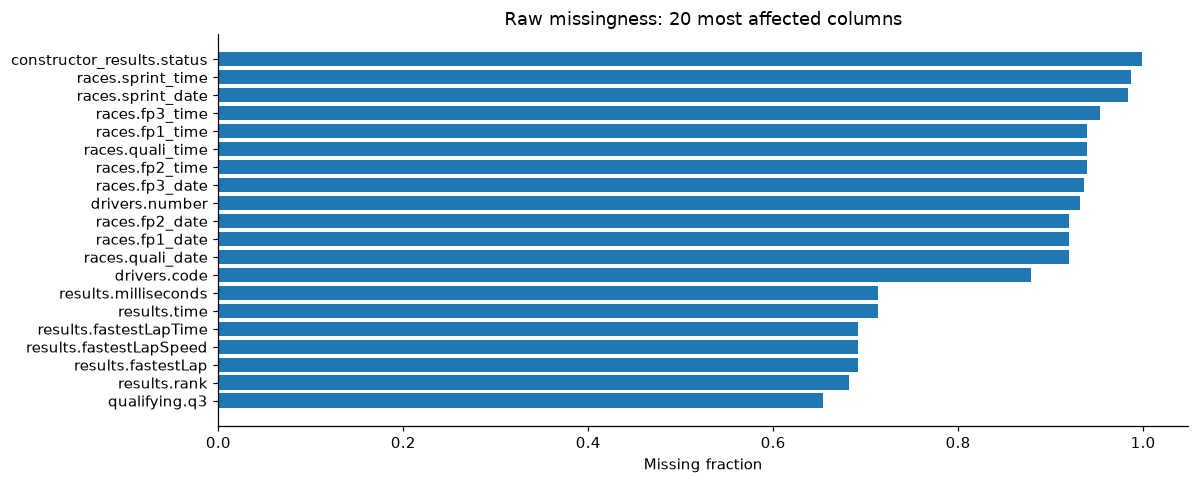

**Task-relevant missingness (within each source table)**

,table,column,missing,rows_in_source_table,missing_percent,interpretation
0,results,positionOrder,0,26759,0.00,Required target source; check completeness.
1,results,grid,0,26759,0.00,"Recorded values need semantic checks, includin..."
2,results,position,10953,26759,40.93,Official position may be absent; do not substi...
3,qualifying,q1,156,10494,1.49,Missingness among recorded qualifying entries ...
4,qualifying,q2,4647,10494,44.28,May reflect elimination before Q2; investigate...
5,qualifying,q3,6865,10494,65.42,May reflect elimination before Q3; investigate...


In [2]:
inventory = pd.DataFrame([{'table': t, 'rows': len(d), 'columns': len(d.columns),
    'sentinel_cells': int(d.eq(r'\N').sum().sum()),
    'empty_cells': int(d.eq('').sum().sum()),
    'exact_duplicate_rows': int(d.duplicated().sum())} for t, d in raw.items()])
display(save_table(inventory, 'raw_inventory'))
missing_rows = []
for t, d in raw.items():
    for col in d:
        n = int((d[col].eq(r'\N') | d[col].eq('')).sum())
        missing_rows.append({'table': t, 'column': col, 'missing': n,
                             'fraction': n / len(d) if len(d) else 0})
missing_before = pd.DataFrame(missing_rows)
save_table(missing_before, 'missingness_before')
top = missing_before.nlargest(20, 'fraction').sort_values('fraction')
plt.barh(top['table'] + '.' + top['column'], top['fraction'])
plt.xlabel('Missing fraction'); plt.title('Raw missingness: 20 most affected columns')
show_plot('01_raw_missingness')

# The top-20 chart can omit complete columns that are central to this task.
# Preserve the source-table denominator: absent qualifying records are not counted here.
focus_notes = {
    ('results', 'positionOrder'): 'Required target source; check completeness.',
    ('results', 'grid'): 'Recorded values need semantic checks, including grid = 0.',
    ('results', 'position'): 'Official position may be absent; do not substitute for positionOrder.',
    ('qualifying', 'q1'): 'Missingness among recorded qualifying entries only.',
    ('qualifying', 'q2'): 'May reflect elimination before Q2; investigate session coverage.',
    ('qualifying', 'q3'): 'May reflect elimination before Q3; investigate session coverage.',
}
task_missingness = (missing_before.set_index(['table', 'column'])
                   .loc[list(focus_notes)].reset_index())
task_missingness['rows_in_source_table'] = task_missingness['table'].map(
    inventory.set_index('table')['rows'])
task_missingness['missing_percent'] = (100 * task_missingness['fraction']).round(2)
task_missingness['interpretation'] = [focus_notes[(row.table, row.column)]
                                    for row in task_missingness.itertuples()]
task_missingness = task_missingness[['table', 'column', 'missing',
    'rows_in_source_table', 'missing_percent', 'interpretation']]
display(Markdown('**Task-relevant missingness (within each source table)**'))
display(save_table(task_missingness, 'task_relevant_missingness'))


**Interpretation of the raw audit.** In this dataset snapshot, `results.positionOrder` has no missing values, so the required podium target can be constructed for every result row. `results.grid` also has no missing markers, but a recorded zero still needs investigation; completeness does not establish semantic validity. The substantial missingness in `results.position` reinforces using the specified `positionOrder` target.

Qualifying percentages above use only rows already present in `qualifying.csv`. They do not include driver–race entries missing from that table entirely; Section 7 measures that coverage through a driver–race join and examines variation by season. Missing Q2/Q3 times may be structural because a driver did not reach those sessions, rather than a recording error. These counts alone do not distinguish the causes or justify dropping rows or imputing times.

The inventory counts missing **cells**, not rows with any missing value. Its zero exact-duplicate count does not establish uniqueness of `(raceId, driverId)`; Section 5 checks and resolves that separate grain requirement. This section measures the raw state before cleaning; later sections verify conversion, duplicate handling, and before/after effects.


## 3. Semantic typing on copies
Identifiers and whole-number quantities become nullable integers; numerical measurements become floats. Dates become timestamps. Clock times become durations since midnight, while lap and elapsed durations become seconds. We retain original duration text alongside the numeric derivative for traceability. Race result time strings beginning with `+` are gaps to the winner, not full race durations; these are exported separately from elapsed times. Every nonmissing value lost during conversion is logged and blocks progress until reviewed.


In [3]:
clean = {t: d.replace({r'\N': pd.NA, '': pd.NA}).copy(deep=True) for t, d in raw.items()}
conversion_rows = []
integer_names = {'year', 'round', 'number', 'grid', 'position', 'positionOrder',
                 'laps', 'lap', 'stop', 'rank', 'wins', 'fastestLap', 'milliseconds'}
float_names = {'lat', 'lng', 'alt', 'points', 'fastestLapSpeed'}
def record_conversion(t, col, old, new, kind):
    invalid = old.notna() & new.isna()
    conversion_rows.append({'table': t, 'column': col, 'conversion': kind,
        'invalid_nonmissing': int(invalid.sum()),
        'examples': '; '.join(old[invalid].astype(str).head(5))})
for t, d in clean.items():
    for col in list(d.columns):
        old = d[col].copy()
        if col.endswith('Id') or col in integer_names:
            new = pd.to_numeric(old, errors='coerce').astype('Int64')
            record_conversion(t, col, old, new, 'nullable integer'); d[col] = new
        elif col in float_names:
            new = pd.to_numeric(old, errors='coerce').astype('Float64')
            record_conversion(t, col, old, new, 'nullable float'); d[col] = new
        elif col == 'date' or col == 'dob' or col.endswith('_date'):
            new = pd.to_datetime(old, errors='coerce', format='%Y-%m-%d')
            record_conversion(t, col, old, new, 'date'); d[col] = new
        elif (t == 'races' and (col == 'time' or col.endswith('_time'))) or (t == 'pit_stops' and col == 'time'):
            new = pd.to_timedelta(old.astype(object).where(old.notna(), None), errors='coerce')
            record_conversion(t, col, old, new, 'clock time'); d[col] = new

def duration_seconds(value):
    if pd.isna(value): return np.nan
    text = str(value).strip().removeprefix('+')
    if not re.fullmatch(r'\d+(?::\d+){0,2}(?:\.\d+)?', text): return np.nan
    total = 0.0
    for part in text.split(':'): total = total * 60 + float(part)
    return total
for t, cols in {'qualifying': ['q1', 'q2', 'q3'], 'lap_times': ['time'],
                'pit_stops': ['duration'], 'results': ['time', 'fastestLapTime'],
                'sprint_results': ['time', 'fastestLapTime']}.items():
    for col in cols:
        old = clean[t][col]
        new = old.map(duration_seconds).astype(float)
        record_conversion(t, col, old, new, 'duration seconds')
        if col == 'time' and t in {'results', 'sprint_results'}:
            is_gap = old.str.startswith('+').fillna(False)
            clean[t]['time_gap_seconds'] = new.where(is_gap)
            clean[t]['time_elapsed_seconds'] = new.where(~is_gap)
        else:
            clean[t][col + '_seconds'] = new
conversion_audit = pd.DataFrame(conversion_rows)
display(save_table(conversion_audit, 'conversion_audit'))
assert conversion_audit['invalid_nonmissing'].sum() == 0, 'Review failed conversions.'


,table,column,conversion,invalid_nonmissing,examples
0,circuits,circuitId,nullable integer,0,
1,circuits,lat,nullable float,0,
2,circuits,lng,nullable float,0,
3,circuits,alt,nullable float,0,
4,constructors,constructorId,nullable integer,0,
...,...,...,...,...,...
91,pit_stops,duration,duration seconds,0,
92,results,time,duration seconds,0,
93,results,fastestLapTime,duration seconds,0,
94,sprint_results,time,duration seconds,0,


## 4. Relational integrity
Check declared primary keys, including composite lap/stop keys. Every referenced driver, constructor, race, circuit, season and status must exist. Missing optional references are reported separately from orphan values. Later joins specify their expected cardinality to prevent accidental row multiplication.


In [4]:
PK = {'circuits': ['circuitId'], 'constructors': ['constructorId'],
      'constructor_results': ['constructorResultsId'], 'constructor_standings': ['constructorStandingsId'],
      'drivers': ['driverId'], 'driver_standings': ['driverStandingsId'], 'races': ['raceId'],
      'results': ['resultId'], 'qualifying': ['qualifyId'], 'lap_times': ['raceId','driverId','lap'],
      'pit_stops': ['raceId','driverId','stop'], 'sprint_results': ['resultId'],
      'seasons': ['year'], 'status': ['statusId']}
pk_audit = pd.DataFrame([{'table': t, 'key': ','.join(keys),
    'null_key_rows': int(clean[t][keys].isna().any(axis=1).sum()),
    'duplicate_key_rows': int(clean[t].duplicated(keys, keep=False).sum())}
    for t, keys in PK.items()])
display(save_table(pk_audit, 'primary_keys'))
parents = {'driverId': 'drivers', 'constructorId': 'constructors', 'raceId': 'races',
           'circuitId': 'circuits', 'statusId': 'status', 'year': 'seasons'}
fk_rows = []
for t, d in clean.items():
    for col, parent in parents.items():
        if col in d and t != parent:
            orphan = d[col].notna() & ~d[col].isin(clean[parent][col])
            fk_rows.append({'table': t, 'column': col, 'parent': parent,
                'null_rows': int(d[col].isna().sum()), 'orphan_rows': int(orphan.sum())})
fk_audit = pd.DataFrame(fk_rows)
display(save_table(fk_audit, 'foreign_keys'))
assert pk_audit[['null_key_rows','duplicate_key_rows']].to_numpy().sum() == 0
assert fk_audit['orphan_rows'].sum() == 0
# These business grains are needed for safe joins, beyond the declared surrogate PKs.
business_rows = []
for t, keys in {'qualifying':['raceId','driverId'],
                'driver_standings':['raceId','driverId'],
                'constructor_standings':['raceId','constructorId'],
                'constructor_results':['raceId','constructorId']}.items():
    business_rows.append({'table':t, 'key':','.join(keys),
                         'duplicate_rows': int(clean[t].duplicated(keys, keep=False).sum())})
business_audit = pd.DataFrame(business_rows)
display(save_table(business_audit, 'join_grains'))
assert business_audit['duplicate_rows'].sum() == 0


,table,key,null_key_rows,duplicate_key_rows
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,constructor_results,constructorResultsId,0,0
3,constructor_standings,constructorStandingsId,0,0
4,drivers,driverId,0,0
5,driver_standings,driverStandingsId,0,0
6,races,raceId,0,0
7,results,resultId,0,0
8,qualifying,qualifyId,0,0
9,lap_times,"raceId,driverId,lap",0,0


,table,column,parent,null_rows,orphan_rows
0,constructor_results,constructorId,constructors,0,0
1,constructor_results,raceId,races,0,0
2,constructor_standings,constructorId,constructors,0,0
3,constructor_standings,raceId,races,0,0
4,driver_standings,driverId,drivers,0,0
5,driver_standings,raceId,races,0,0
6,races,circuitId,circuits,0,0
7,races,year,seasons,0,0
8,results,driverId,drivers,0,0
9,results,constructorId,constructors,0,0


,table,key,duplicate_rows
0,qualifying,"raceId,driverId",0
1,driver_standings,"raceId,driverId",0
2,constructor_standings,"raceId,constructorId",0
3,constructor_results,"raceId,constructorId",0


## 5. Driver–race duplicates and the retained grain
**Policy:** prefer a row with a recorded positive grid; break ties by the smallest `resultId`. If every row has a zero/missing grid, use the smallest `resultId`. This avoids choosing the feature row using finishing position. A positive grid is evidence of a recorded grid assignment, not proof of an actual start.

The retained row supplies both the label and its associated constructor/grid. We do not combine a best outcome from one car with the starting features of another. This deliberately changes the interpretation of historical shared drives to the retained entry; it can miss a podium earned in another car. We quantify that sensitivity in the historical evaluation below.

All discarded rows and the selected result ID are exported. Duplicates are not automatically labeled errors or shared drives without historical evidence.

**Limitation - historical entry ambiguity:** Some historical drivers have multiple result entries for the same race, with different recorded starting grids and sometimes different constructors. These entries already exist in the raw `results.csv` table; they are not created by a join, and they are not duplicate qualifying records. When multiple entries have positive grids, the grid preference cannot identify one original entry. The smallest `resultId` is only a deterministic tie-breaker, not evidence of which car the driver originally started in. The retained row therefore represents a documented selection convention, not a verified reconstruction of the driver's starting circumstances. This uncertainty affects the historical model inputs and labels, especially in the earliest evaluation periods.


Duplicate groups: 85 
Extra rows removed: 91 
Retained entries: 26668 
Labels different from any-car podium policy: 16


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,...,rank,fastestLapTime,fastestLapSpeed,statusId,time_gap_seconds,time_elapsed_seconds,fastestLapTime_seconds,year,selected_resultId,kept
0,13189,540,229,54,10,0,<NA>,F,26,0.0,...,<NA>,<NA>,<NA>,81,NaN,NaN,NaN,1978,13189,True
1,13192,540,229,57,23,0,<NA>,F,29,0.0,...,<NA>,<NA>,<NA>,97,NaN,NaN,NaN,1978,13189,False
2,17363,717,373,172,1,1,7,7,7,0.0,...,<NA>,<NA>,<NA>,60,NaN,NaN,NaN,1964,17363,True
3,17741,733,465,172,48,0,<NA>,W,22,0.0,...,<NA>,<NA>,<NA>,54,NaN,NaN,NaN,1962,17741,True
4,17744,733,465,97,50,0,<NA>,W,25,0.0,...,<NA>,<NA>,<NA>,54,NaN,NaN,NaN,1962,17741,False
5,17962,742,475,102,26,20,<NA>,D,19,0.0,...,<NA>,<NA>,<NA>,2,NaN,NaN,NaN,1961,17962,True
6,17964,742,475,172,28,5,<NA>,R,21,0.0,...,<NA>,<NA>,<NA>,23,NaN,NaN,NaN,1961,17962,False
7,18063,745,418,172,22,11,<NA>,R,17,0.0,...,<NA>,<NA>,<NA>,6,NaN,NaN,NaN,1961,18063,True
8,18083,746,475,170,36,1,<NA>,R,17,0.0,...,<NA>,<NA>,<NA>,22,NaN,NaN,NaN,1960,18083,True
9,18510,766,541,87,22,0,<NA>,F,17,0.0,...,<NA>,<NA>,<NA>,81,NaN,NaN,NaN,1958,18510,True


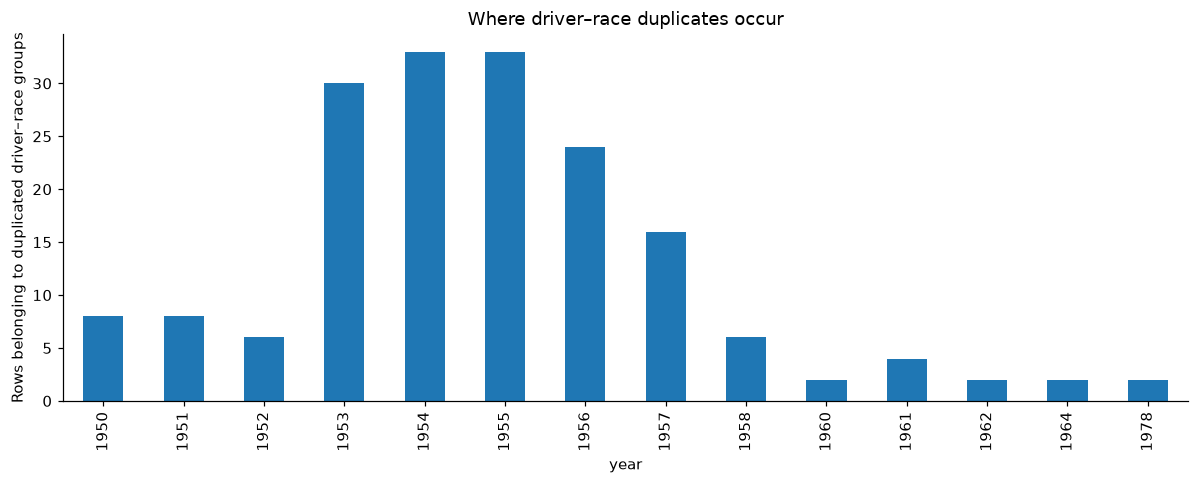

Duplicate year range: 1950 – 1978


In [5]:
results = clean['results'].copy()
keys = ['raceId', 'driverId']
dup_mask = results.duplicated(keys, keep=False)
duplicates = results.loc[dup_mask].merge(clean['races'][['raceId','year']], on='raceId', validate='many_to_one')
# Stable sorting gives a reproducible outcome independent of CSV row order.
ranked = results.assign(_positive_grid=results['grid'].gt(0).fillna(False)).sort_values(
    keys + ['_positive_grid','resultId'], ascending=[True, True, False, True], kind='stable')
entries = ranked.drop_duplicates(keys).drop(columns='_positive_grid').copy()
entries['podium'] = entries['positionOrder'].le(3).astype('int8')
assert not entries.duplicated(keys).any()
selected = entries[keys + ['resultId']].rename(columns={'resultId':'selected_resultId'})
duplicate_log = duplicates.merge(selected, on=keys, validate='many_to_one')
duplicate_log['kept'] = duplicate_log['resultId'].eq(duplicate_log['selected_resultId'])
save_table(duplicate_log, 'duplicate_decisions')
best = results.assign(any_entry_podium=results['positionOrder'].le(3)).groupby(keys)['any_entry_podium'].max()
sensitivity = entries.set_index(keys)[['podium']].join(best)
label_disagreements = int(sensitivity['podium'].ne(sensitivity['any_entry_podium']).sum())
print('Duplicate groups:', duplicates.groupby(keys).ngroups,
      '\nExtra rows removed:', len(results)-len(entries),
      '\nRetained entries:', len(entries),
      '\nLabels different from any-car podium policy:', label_disagreements)
display(duplicate_log.head(15))
if len(duplicates):
    duplicates.groupby('year').size().plot.bar()
    plt.ylabel('Rows belonging to duplicated driver–race groups')
    plt.title('Where driver–race duplicates occur'); show_plot('02_duplicate_years')
    print('Duplicate year range:', duplicates['year'].min(), '–', duplicates['year'].max())


## 6. Outcome semantics and unusual grid values
Do not drop `D` (disqualified) or `N` (not classified) as if they necessarily meant “did not start.” Do not infer non-starts from `grid = 0`: pit-lane starters and other cases can share that value. Zero laps is also insufficient evidence: a driver can retire before completing a lap.

Keep all outcomes in this entry-level audit. For the later mechanical-retirement question, build a separately justified **actual-start denominator**. Outcome/status fields below are audit data and eventual labels, never current-race prediction features.


,positionText,status,entries,zero_grid,positive_laps
608,R,Engine,1856,0,1822
0,1,Finished,1125,0,1125
332,2,Finished,1100,0,1100
565,F,Did not qualify,1024,1012,1
400,3,Finished,993,0,993
583,R,Accident,955,2,733
415,4,Finished,862,0,862
593,R,Collision,801,0,452
623,R,Gearbox,765,0,739
656,R,Spun off,750,0,713


,status,entries
0,Did not qualify,1012
1,Did not prequalify,330
2,Withdrew,163
3,+1 Lap,27
4,Finished,22
5,Accident,20
6,Injury,8
7,+2 Laps,7
8,Excluded,6
9,Engine,6


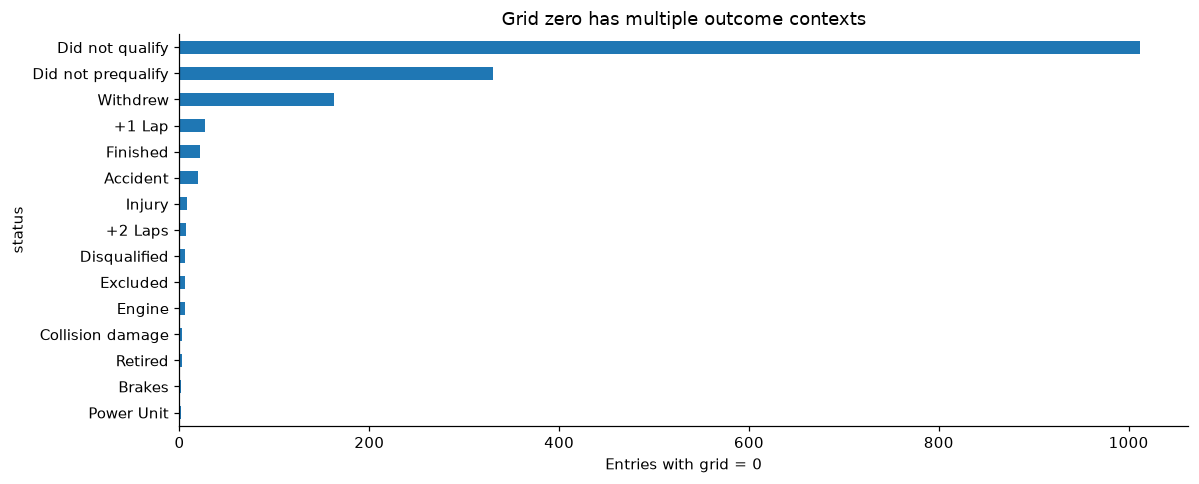

,check,count
0,positionOrder missing or below 1,0
1,grid missing,0
2,negative grid,0
3,negative laps,0
4,qualifying position missing or below 1,0


In [6]:
entry_audit = entries.merge(clean['races'][['raceId','year','round','date','circuitId','name']],
                           on='raceId', validate='many_to_one').merge(
                           clean['status'], on='statusId', validate='many_to_one')
assert len(entry_audit) == len(entries)
status_summary = entry_audit.groupby(['positionText','status'], dropna=False).agg(
    entries=('resultId','size'), zero_grid=('grid', lambda x: int(x.eq(0).sum())),
    positive_laps=('laps', lambda x: int(x.gt(0).sum()))).reset_index()
display(save_table(status_summary, 'outcome_status_summary').sort_values('entries', ascending=False).head(25))
zero_grid = entry_audit.loc[entry_audit['grid'].eq(0)].groupby('status').size().sort_values(ascending=False)
display(save_table(zero_grid.rename('entries').reset_index(), 'zero_grid_statuses').head(20))
zero_grid.head(15).sort_values().plot.barh()
plt.xlabel('Entries with grid = 0'); plt.title('Grid zero has multiple outcome contexts')
show_plot('03_zero_grid_context')
range_checks = pd.DataFrame([
 {'check':'positionOrder missing or below 1', 'count':int((results['positionOrder'].isna() | results['positionOrder'].lt(1)).sum())},
 {'check':'grid missing', 'count':int(results['grid'].isna().sum())},
 {'check':'negative grid', 'count':int(results['grid'].lt(0).sum())},
 {'check':'negative laps', 'count':int(results['laps'].lt(0).sum())},
 {'check':'qualifying position missing or below 1', 'count':int((clean['qualifying']['position'].isna() | clean['qualifying']['position'].lt(1)).sum())}
])
display(save_table(range_checks, 'range_checks'))
assert range_checks['count'].sum() == 0, 'Unexpected range values require review.'


## 7. Qualifying coverage — race level and driver level
A race having at least one qualifying record does not mean every entry has one. Join at `(raceId, driverId)` and separately measure matched records, available qualifying position, and recorded Q1/Q2/Q3 durations. Later-session missingness is expected for eliminated drivers.

The denominator is retained result entries. Missing records may include non-qualifiers or withdrawals, so missingness alone does not establish a recording error. The 2003 boundary below is provisional, not selected by test-set performance.


,year,entries,record_coverage,position_coverage,q1_coverage,q2_coverage,q3_coverage,race_coverage
50,2000,373,0.235925,0.235925,0.235925,0.000000,0.000000,0.235294
51,2001,374,0.058824,0.058824,0.058824,0.000000,0.000000,0.058824
52,2002,362,0.116022,0.116022,0.116022,0.000000,0.000000,0.117647
53,2003,320,1.000000,1.000000,0.965625,0.000000,0.000000,1.0
54,2004,360,1.000000,1.000000,0.941667,0.000000,0.000000,1.0
55,2005,376,1.000000,1.000000,0.954787,0.284574,0.000000,1.0
56,2006,396,1.000000,1.000000,0.979798,0.717172,0.444444,1.0
57,2007,374,1.000000,1.000000,0.994652,0.711230,0.451872,1.0
58,2008,368,1.000000,1.000000,0.994565,0.733696,0.478261,1.0
59,2009,340,1.000000,1.000000,0.997059,0.738235,0.491176,1.0


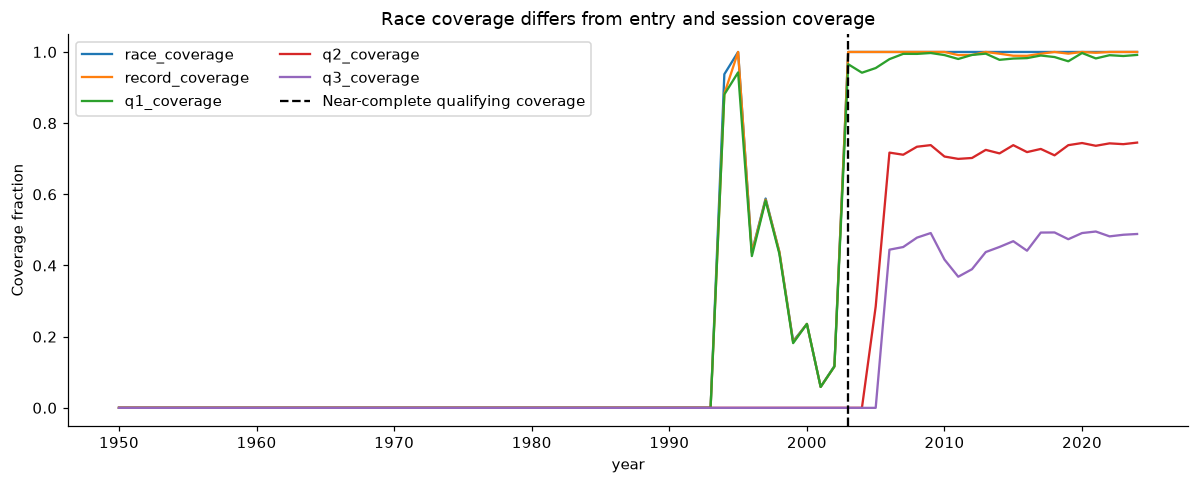

Races with partial entry coverage: 41


,raceId,year,entries,matched,partial
873,875,2012,24,23,True
915,918,2014,20,18,True
917,927,2015,20,19,True
919,929,2015,20,19,True
922,932,2015,20,19,True
930,941,2015,20,19,True
941,954,2016,22,21,True
944,957,2016,22,21,True
947,960,2016,22,21,True
948,961,2016,22,21,True


Constructor mismatches between results and qualifying: 10


In [7]:
q = clean['qualifying'].rename(columns={'position':'qualifying_position', 'constructorId':'qualifying_constructorId'})
coverage = entry_audit.merge(q[keys + ['qualifyId','qualifying_position','qualifying_constructorId',
                                   'q1_seconds','q2_seconds','q3_seconds']],
                            on=keys, how='left', validate='one_to_one')
assert len(coverage) == len(entries)
coverage['has_qualifying_record'] = coverage['qualifyId'].notna()
coverage['has_qualifying_position'] = coverage['qualifying_position'].notna()
for col in ['q1','q2','q3']:
    coverage['has_' + col] = coverage[col+'_seconds'].notna()
season_coverage = coverage.groupby('year').agg(entries=('resultId','size'),
    record_coverage=('has_qualifying_record','mean'), position_coverage=('has_qualifying_position','mean'),
    q1_coverage=('has_q1','mean'), q2_coverage=('has_q2','mean'), q3_coverage=('has_q3','mean')).reset_index()
race_coverage = coverage.groupby(['raceId','year']).agg(entries=('resultId','size'),
    matched=('has_qualifying_record','sum')).reset_index()
race_coverage['partial'] = race_coverage['matched'].gt(0) & race_coverage['matched'].lt(race_coverage['entries'])
race_fraction = clean['races'].assign(has_q=clean['races']['raceId'].isin(q['raceId'])).groupby('year')['has_q'].mean()
season_coverage = season_coverage.merge(race_fraction.rename('race_coverage'), on='year', validate='one_to_one')
save_table(season_coverage, 'qualifying_coverage_by_year')
save_table(race_coverage, 'qualifying_coverage_by_race')
save_table(coverage.loc[~coverage['has_qualifying_record'], keys+['year','name','positionText','status']], 'missing_qualifying_entries')
display(season_coverage.tail(25))
season_coverage.set_index('year')[['race_coverage','record_coverage','q1_coverage','q2_coverage','q3_coverage']].plot()
plt.axvline(2003, color='black', linestyle='--', label='Near-complete qualifying coverage')
plt.ylabel('Coverage fraction'); plt.title('Race coverage differs from entry and session coverage')
plt.legend(ncol=2); show_plot('04_qualifying_coverage')
print('Races with partial entry coverage:', int(race_coverage['partial'].sum()))
display(race_coverage.loc[race_coverage['partial']].tail(15))
constructor_mismatch = coverage['qualifying_constructorId'].notna() & coverage['constructorId'].ne(coverage['qualifying_constructorId'])
save_table(coverage.loc[constructor_mismatch, keys+['year','constructorId','qualifying_constructorId']], 'qualifying_constructor_mismatches')
print('Constructor mismatches between results and qualifying:', int(constructor_mismatch.sum()))


## 8. Before/after EDA and descriptive historical coverage

Compare raw result rows with retained driver-race entries. Counts, target rates and missingness effects
are computed from the data. The five reporting bins are descriptive groupings, not claims that every
boundary is an official regulation era. The separate 2014 boundary in Question 1 answers the brief's
hybrid-era comparison. Whole-history outcome summaries describe the dataset; they do not select model
features. Historical feature decisions use training/validation data within the later evaluation protocol.


,stage,rows,duplicate_extra_rows,podium_count,podium_rate
0,Raw result rows,26759,91,3397,0.126948
1,Retained driver–race entries,26668,0,3379,0.126706


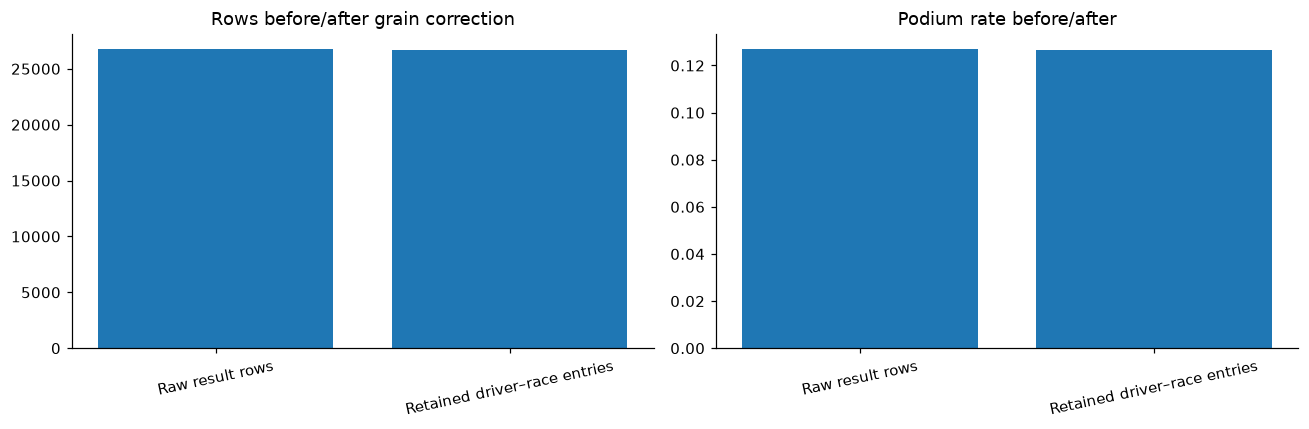

Sentinels were converted to nulls, not imputed; original-column missing counts are unchanged.


,year,size,sum,mean
0,1950–1979,7836,988,0.126085
1,1980–2002,9862,1107,0.112249
2,2003–2013,4344,600,0.138122
3,2014–2021,3267,480,0.146924
4,2022–2024,1359,204,0.150110


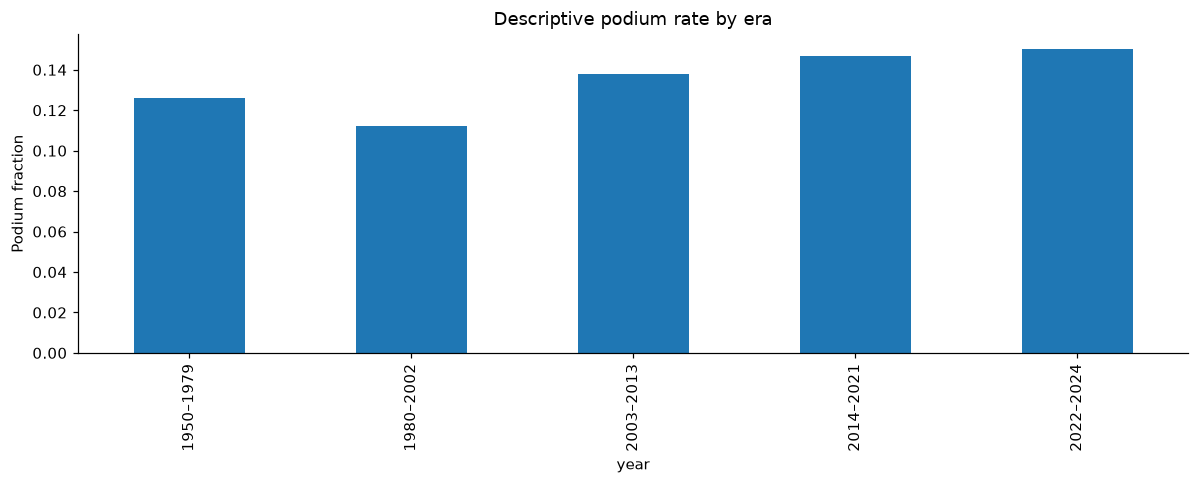

In [8]:
comparison = pd.DataFrame([
 {'stage':'Raw result rows', 'rows':len(results), 'duplicate_extra_rows':int(results.duplicated(keys).sum()),
  'podium_count':int(results['positionOrder'].le(3).sum()), 'podium_rate':float(results['positionOrder'].le(3).mean())},
 {'stage':'Retained driver–race entries', 'rows':len(entries), 'duplicate_extra_rows':int(entries.duplicated(keys).sum()),
  'podium_count':int(entries['podium'].sum()), 'podium_rate':float(entries['podium'].mean())}
])
display(save_table(comparison, 'before_after_grain'))
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].bar(comparison['stage'], comparison['rows']); axes[0].set_title('Rows before/after grain correction')
axes[1].bar(comparison['stage'], comparison['podium_rate']); axes[1].set_title('Podium rate before/after')
for ax in axes: ax.tick_params(axis='x', rotation=12)
show_plot('05_before_after')
missing_after = pd.DataFrame([{'table':t, 'column':col, 'missing':int(d[col].isna().sum()),
    'fraction':float(d[col].isna().mean())} for t,d in clean.items() for col in raw[t].columns])
save_table(missing_after, 'missingness_after')
missing_compare = missing_before.merge(missing_after, on=['table','column'], suffixes=('_before','_after'))
assert missing_compare['missing_before'].eq(missing_compare['missing_after']).all()
print('Sentinels were converted to nulls, not imputed; original-column missing counts are unchanged.')
era = pd.cut(entry_audit['year'], bins=[1949,1979,2002,2013,2021,2024],
             labels=['1950–1979','1980–2002','2003–2013','2014–2021','2022–2024'])
era_summary = entry_audit.groupby(era, observed=True)['podium'].agg(['size','sum','mean']).reset_index()
display(save_table(era_summary, 'podium_by_era'))
era_summary.plot.bar(x='year', y='mean', legend=False)
plt.ylabel('Podium fraction'); plt.title('Descriptive podium rate by era'); show_plot('06_podium_by_era')


## 9. Prediction cutoff and permitted information

The entry audit table deliberately contains outcomes for inspection. Never pass all its columns to a model.

| Information | Modeling treatment |
|---|---|
| Current grid and qualifying | Available by the prediction cutoff; encode zero grid and missing qualifying explicitly |
| Driver and constructor form | Strictly earlier completed events; aggregate team cars before lagging |
| Standings | Snapshot after the previous race in the same season; handle openers and missing snapshots explicitly |
| Current `positionOrder` | Used only to create the podium target |
| Current points, status, laps, race times, fastest laps and pit stops | Excluded from current-race prediction inputs |
| Identifiers | Join keys; selected circuit/team identities are explicit categorical inputs |
| Current-weekend sprint results | Not used; previous-race standings remain stale but pre-race-valid |

The feature builder uses an allowlist and source-date checks. Historical evaluation keeps entire races
together and separates training, validation and testing chronologically. Retain entries unless eligibility
is established by the prediction cutoff; do not remove future crashes, retirements or disqualifications.


## 10. Export and reproducibility check
Cleaned source tables preserve their original grains; `entries_unique.csv` separately applies the documented driver–race rule. The audit table includes forbidden modeling columns and is labeled accordingly. The JSON summary and CSV audit logs provide machine-readable evidence. No input file is overwritten.


In [9]:
for t, d in clean.items():
    d.to_csv(OUT / 'cleaned' / f'{t}.csv', index=False)
entries.to_csv(OUT / 'cleaned' / 'entries_unique.csv', index=False)
coverage.to_csv(OUT / 'entry_audit_NOT_model_features.csv', index=False)
hashes_after = {t: sha256(DATA_DIR / f'{t}.csv') for t in TABLES}
assert hashes_before == hashes_after, 'Input CSVs changed during execution.'
summary = {'input_hashes_sha256': hashes_before,
    'table_count': len(raw), 'raw_result_rows': len(results), 'unique_entry_rows': len(entries),
    'duplicate_groups': int(duplicates.groupby(keys).ngroups),
    'removed_duplicate_rows': len(results)-len(entries),
    'duplicate_label_policy_disagreements': label_disagreements,
    'primary_key_violations': int(pk_audit[['null_key_rows','duplicate_key_rows']].to_numpy().sum()),
    'foreign_key_orphan_rows': int(fk_audit['orphan_rows'].sum()),
    'conversion_failures': int(conversion_audit['invalid_nonmissing'].sum()),
    'races_with_partial_qualifying_coverage': int(race_coverage['partial'].sum()),
    'qualifying_constructor_mismatches': int(constructor_mismatch.sum()),
    'raw_inputs_unchanged': hashes_before == hashes_after}
(OUT / 'audit_summary.json').write_text(json.dumps(summary, indent=2))
display(Markdown(f"**Audit completed:** {len(raw)} tables; {len(results):,} raw result rows → "
    f"{len(entries):,} unique entries. {summary['duplicate_groups']} duplicate groups; "
    f"{summary['removed_duplicate_rows']} extra rows removed. "
    f"{summary['races_with_partial_qualifying_coverage']} races have partial qualifying-record coverage. "
    "Raw input hashes are unchanged. See exported logs for limitations and policy effects."))


**Audit completed:** 14 tables; 26,759 raw result rows → 26,668 unique entries. 85 duplicate groups; 91 extra rows removed. 41 races have partial qualifying-record coverage. Raw input hashes are unchanged. See exported logs for limitations and policy effects.

# 11. Relational analysis: shared definitions
The three questions use the unique driver–race entries from the audit, joined to race, circuit, driver, constructor and status dimensions with explicit join cardinality. Outcomes are allowed for these retrospective questions; they are not automatically allowed as prediction features.

Indianapolis **500 events** (1950–1960) are excluded from Questions 1 and 2 as a different racing context. Later United States Grands Prix at the same circuit remain included. Historical duplicate policy and retrospective classification remain limitations. Rates are descriptive associations, not causal estimates.

Small-sample rankings are unstable. Question 1 requires at least 20 front-row entries per circuit/era for a displayed ranking. Tables retain every circuit, including those below the threshold. Wilson intervals describe binomial uncertainty only; paired drivers within a race and temporal dependence can make those intervals optimistic.


In [10]:
ANALYSIS = ROOT / 'artifacts' / 'analysis'
FEATURES = ROOT / 'artifacts' / 'features'
for folder in [ANALYSIS, FEATURES]:
    (folder / 'figures').mkdir(parents=True, exist_ok=True)
def analysis_table(df, name):
    df.to_csv(ANALYSIS / f'{name}.csv', index=False)
    return df
def analysis_plot(name):
    plt.tight_layout(); plt.savefig(ANALYSIS / 'figures' / f'{name}.png', bbox_inches='tight')
    plt.show(); plt.close()
def wilson(k, n):
    n = np.asarray(n, dtype=float); k = np.asarray(k, dtype=float)
    rate = np.divide(k, n, out=np.zeros_like(k), where=n>0)
    z = 1.95996398454
    den = 1 + z*z / np.maximum(n, 1)
    mid = (rate + z*z/(2*np.maximum(n, 1))) / den
    half = z * np.sqrt(rate*(1-rate)/np.maximum(n,1)+z*z/(4*np.maximum(n,1)**2))/den
    return np.where(n>0, mid-half, np.nan), np.where(n>0, mid+half, np.nan)
analysis = coverage.merge(clean['circuits'][['circuitId','name','country','circuitRef']].rename(
    columns={'name':'circuit_name','country':'circuit_country'}), on='circuitId', validate='many_to_one')
analysis = analysis.merge(clean['drivers'][['driverId','forename','surname','nationality','dob']],
                          on='driverId', validate='many_to_one')
analysis = analysis.merge(clean['constructors'][['constructorId','name']].rename(
    columns={'name':'constructor_name'}), on='constructorId', validate='many_to_one')
assert len(analysis) == len(entries)
analysis['era2014'] = np.where(analysis['year'].lt(2014), '1950–2013', '2014–2024')
analysis['is_indy500'] = analysis['name'].eq('Indianapolis 500')
print('Excluded Indy 500 entries for Q1/Q2:', int(analysis['is_indy500'].sum()))


Excluded Indy 500 entries for Q1/Q2: 381


## 12. Question 1 — which circuits convert a front row into a podium?
**Grain/denominator:** retained driver–race entries with recorded grid 1 or 2, grouped by circuit and era. Qualifying-front-row conversion is a separate measure with its own denominator (qualifying position 1 or 2). Qualifying results are not substituted for grid.

The historical grid comparison uses all available years. Because qualifying coverage changes sharply, a second 2003–2024 comparison uses only rows with both positions recorded. Rankings before/after 2014 are also compared on circuits eligible in **both** eras, so circuit turnover is not mistaken for a rank change. Sprint formats and penalties can both cause a grid/qualifying difference; the difference is not labeled a penalty.


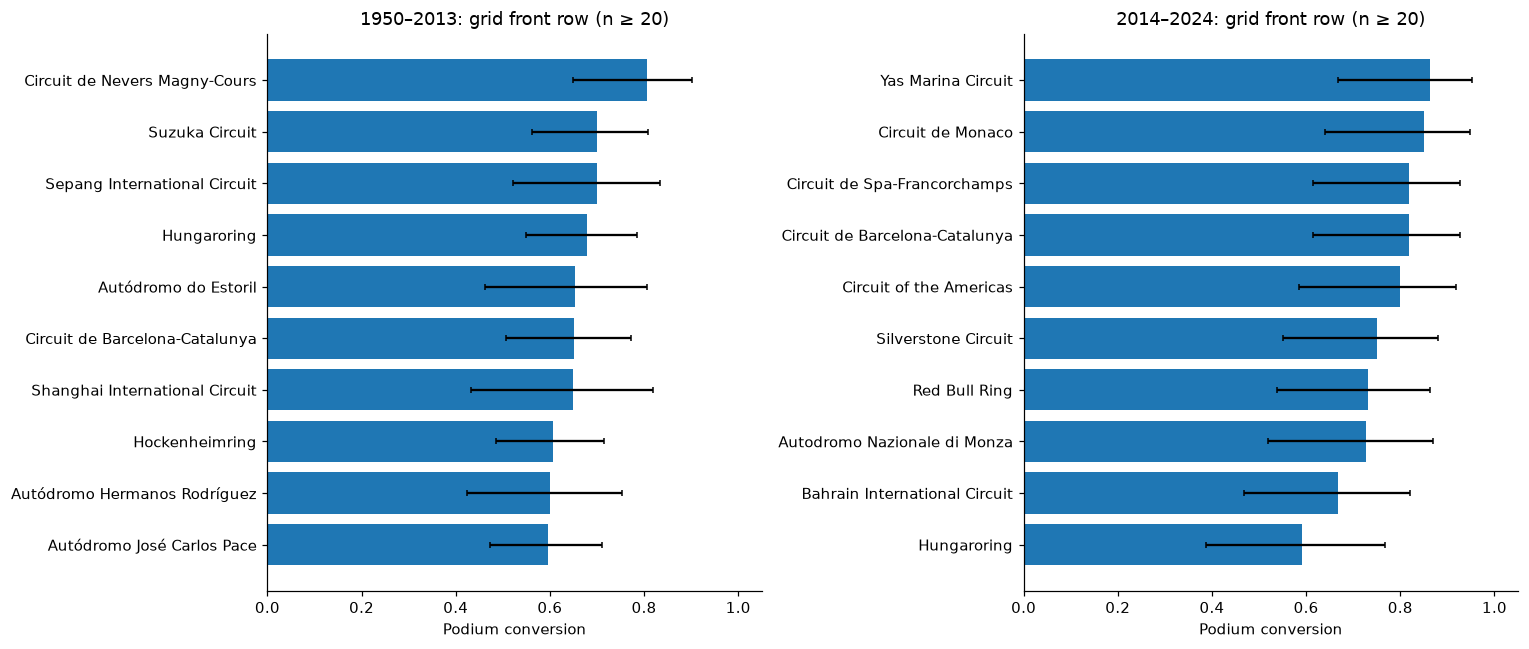

,circuitId,circuit_name,rate_1950–2013,rate_2014–2024,common_rank_1950–2013,common_rank_2014–2024,entries_1950–2013,entries_2014–2024,rate_change,rank_improvement
1,6,Circuit de Monaco,0.491667,0.85,6.0,1.0,120,20,0.358333,5.0
4,13,Circuit de Spa-Francorchamps,0.538462,0.818182,4.0,2.0,91,22,0.27972,2.0
5,14,Autodromo Nazionale di Monza,0.46875,0.727273,7.0,6.0,128,22,0.258523,1.0
6,70,Red Bull Ring,0.52,0.730769,5.0,5.0,50,26,0.210769,0.0
2,9,Silverstone Circuit,0.56383,0.75,3.0,4.0,94,24,0.18617,-1.0
0,4,Circuit de Barcelona-Catalunya,0.652174,0.818182,2.0,2.0,46,22,0.166008,0.0
3,11,Hungaroring,0.678571,0.590909,1.0,7.0,56,22,-0.087662,-6.0


,era,definition,entries,podium_rate
0,1950–2013,grid,400,0.680000
1,1950–2013,qualifying,400,0.672500
2,2014–2024,grid,454,0.759912
3,2014–2024,qualifying,454,0.740088


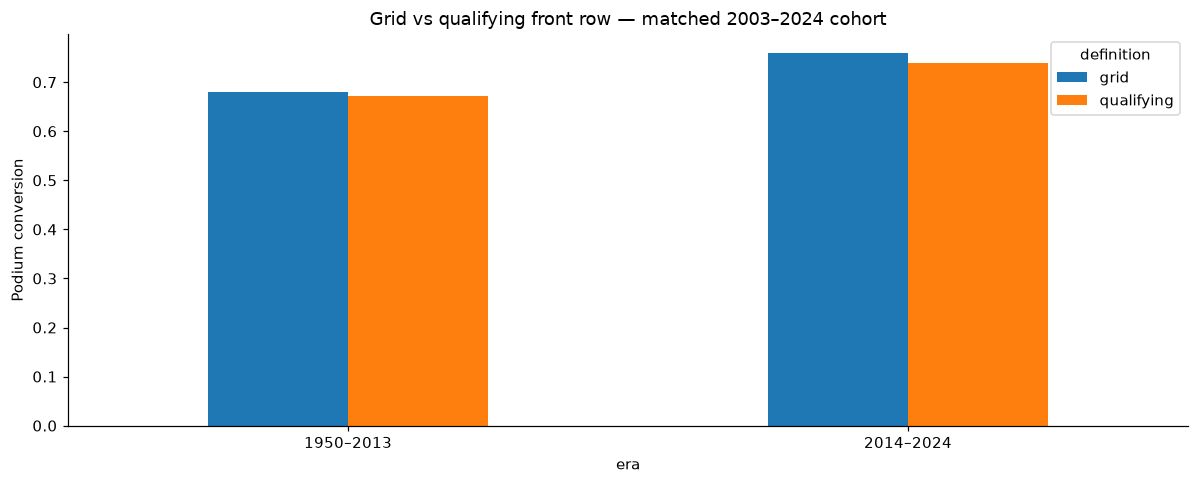

**Answer:** 1950–2013: Circuit de Nevers Magny-Cours 80.6% (29/36); Sepang International Circuit 70.0% (21/30); Suzuka Circuit 70.0% (35/50); 2014–2024: Yas Marina Circuit 86.4% (19/22); Circuit de Monaco 85.0% (17/20); Circuit de Barcelona-Catalunya 81.8% (18/22). Among 7 circuits eligible in both eras, at least one rank changes: **True**. See the common-circuit table for rank and rate changes. These are observed rankings with small and dependent samples, not evidence of a causal 2014 effect.

In [11]:
def front_row_summary(frame, position_col, label):
    selected = frame.loc[frame[position_col].isin([1,2])]
    out = selected.groupby(['circuitId','circuit_name','era2014'], observed=True).agg(
        entries=('resultId','size'), podiums=('podium','sum')).reset_index()
    out['rate'] = out['podiums']/out['entries']
    out['lower95'],out['upper95'] = wilson(out['podiums'],out['entries'])
    out['definition'] = label
    out['eligible_20'] = out['entries'].ge(20)
    out['rank_within_eligible'] = out.loc[out['eligible_20']].groupby('era2014')['rate'].rank(method='min',ascending=False)
    return out
q1_base = analysis.loc[~analysis['is_indy500']].copy()
q1_grid = front_row_summary(q1_base, 'grid', 'recorded grid 1–2')
q1_qualifying = front_row_summary(q1_base, 'qualifying_position', 'qualifying position 1–2')
analysis_table(q1_grid,'q1_grid_all_circuits'); analysis_table(q1_qualifying,'q1_qualifying_all_circuits')
fig,axes=plt.subplots(1,2,figsize=(14,6))
for ax, era in zip(axes,['1950–2013','2014–2024']):
    part=q1_grid.loc[q1_grid['era2014'].eq(era)&q1_grid['eligible_20']].nlargest(10,'rate').sort_values('rate')
    ax.barh(part['circuit_name'],part['rate'])
    ax.errorbar(part['rate'],np.arange(len(part)),xerr=[part['rate']-part['lower95'],part['upper95']-part['rate']],fmt='none',color='black',capsize=2)
    ax.set_title(f'{era}: grid front row (n ≥ 20)'); ax.set_xlim(0,1.05);ax.set_xlabel('Podium conversion')
analysis_plot('q1_front_row_circuit_rankings')
eligible=q1_grid.loc[q1_grid['eligible_20']]
common=eligible.groupby('circuitId')['era2014'].nunique(); common=common[common.eq(2)].index
common_rows=eligible.loc[eligible['circuitId'].isin(common)].copy()
common_rows['common_rank']=common_rows.groupby('era2014')['rate'].rank(method='min',ascending=False)
q1_change=common_rows.pivot(index=['circuitId','circuit_name'],columns='era2014',values=['rate','common_rank','entries'])
q1_change.columns=['_'.join(col) for col in q1_change.columns]
q1_change=q1_change.reset_index()
q1_change['rate_change']=q1_change['rate_2014–2024']-q1_change['rate_1950–2013']
q1_change['rank_improvement']=q1_change['common_rank_1950–2013']-q1_change['common_rank_2014–2024']
display(analysis_table(q1_change.sort_values('rate_change',ascending=False),'q1_common_circuit_changes'))
matched=q1_base.loc[q1_base['year'].ge(2003)&q1_base['qualifying_position'].notna()&q1_base['grid'].gt(0)]
q1_matched=pd.concat([front_row_summary(matched,'grid','grid'),front_row_summary(matched,'qualifying_position','qualifying')],ignore_index=True)
analysis_table(q1_matched,'q1_matched_2003_onward')
matched_aggregate=[]
for era,d in matched.groupby('era2014'):
    for pos,label in [('grid','grid'),('qualifying_position','qualifying')]:
        front=d.loc[d[pos].isin([1,2])]
        matched_aggregate.append({'era':era,'definition':label,'entries':len(front),'podium_rate':front['podium'].mean()})
matched_aggregate=pd.DataFrame(matched_aggregate)
display(analysis_table(matched_aggregate,'q1_matched_aggregate'))
matched_aggregate.pivot(index='era',columns='definition',values='podium_rate').plot.bar(rot=0)
plt.ylabel('Podium conversion');plt.title('Grid vs qualifying front row — matched 2003–2024 cohort')
analysis_plot('q1_grid_vs_qualifying')
leaders=[]
for era,d in eligible.groupby('era2014'):
    best=d.nlargest(3,'rate')
    leaders.append(era+': '+ '; '.join(f"{r.circuit_name} {r.rate:.1%} ({r.podiums}/{r.entries})" for r in best.itertuples()))
q1_answer='; '.join(leaders)
rank_changed=bool(q1_change['rank_improvement'].ne(0).any())
display(Markdown('**Answer:** '+q1_answer+'. '+
    f'Among {len(common)} circuits eligible in both eras, at least one rank changes: **{rank_changed}**. '
    'See the common-circuit table for rank and rate changes. These are observed rankings with small and dependent samples, not evidence of a causal 2014 effect.'))


**Answer.** With at least 20 recorded front-row entries per circuit and era, the highest 1950–2013 conversion is Magny-Cours (29/36, 80.6%). In 2014–2024, Yas Marina leads (19/22, 86.4%), followed by Monaco (17/20, 85.0%). Among seven circuits eligible in both eras, Monaco moves from sixth to first and Hungaroring from first to seventh. The separate matched 2003–2024 comparison shows grid and qualifying front-row rates differ, so they cannot be treated as interchangeable. These are descriptive rates with small modern-era denominators.

## 13. Question 2 — home-country association after adjusting for the grid
Nationality is not directly a country name. The explicit mapping below uses sporting nationality; dual nationalities count either country, East German maps geographically to Germany, and Rhodesian to Zimbabwe. Country aliases are normalized. These are declared conventions, not inferred residences.

**Primary population:** non-Indy entries with a positive recorded grid and a mapped nationality. Adjust within **exact grid position × era** strata (1950–1979, 1980–2002, 2003–2013, 2014–2021, 2022–2024). Retain strata with at least five home and five away entries; use their combined entry proportions as common weights. Report excluded counts and both raw and standardized rates on the same retained cohort.

A race-cluster bootstrap resamples races, holding the original standardization weights fixed, for an approximate interval on the home-minus-away difference. It captures same-race dependence, not every temporal/driver correlation. A secondary calculation restricts to drivers observed both at home and away. Neither adjustment controls all driver ability, constructor strength, or era effects; the result is an association.


,stage,entries
0,non-Indy entries,26287
1,mapped nationality and positive grid,24652
2,common-support strata,21616


,group,unadjusted_same_cohort,grid_era_standardized
0,Away,0.136435,0.135204
1,Home,0.114332,0.125421


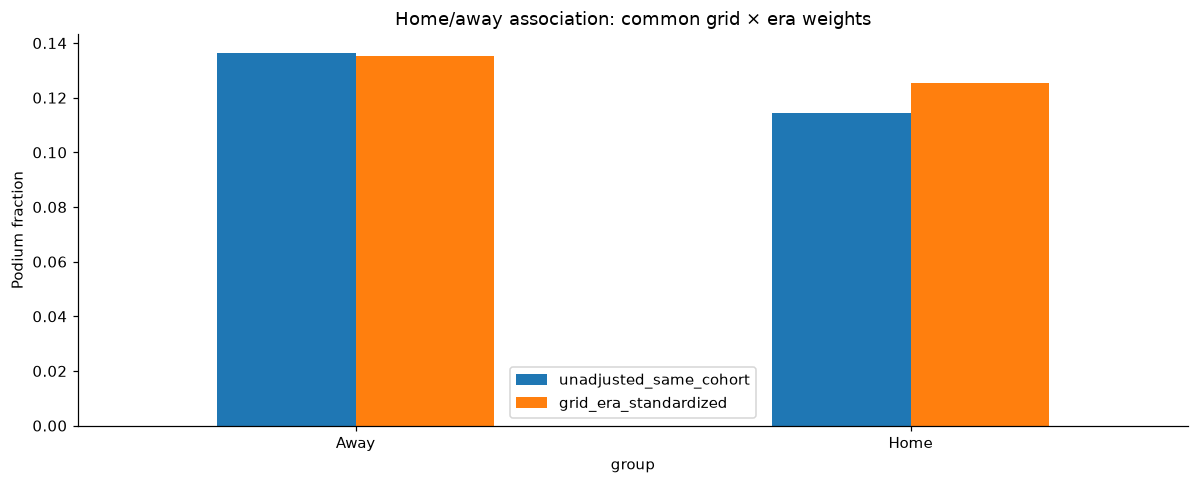

,population,entries,difference
0,all eligible drivers,21616,-0.009784
1,drivers observed at home and away,18033,-0.009815


**Answer:** After grid/era standardization, home podium rate is 12.54% versus 13.52% away: difference -0.98 percentage points (approximate 95% race-bootstrap interval -2.23 to +0.32; 476 valid replicates). This is an adjusted association, not proof of a home advantage. The common-support restriction and remaining driver/team confounding limit generalization.

In [12]:
NATIONALITY_COUNTRIES = {
'American':('USA',),'American-Italian':('USA','Italy'),'Argentine':('Argentina',),
'Argentine-Italian':('Argentina','Italy'),'Argentinian':('Argentina',),'Australian':('Australia',),
'Austrian':('Austria',),'Belgian':('Belgium',),'Brazilian':('Brazil',),'British':('UK',),
'Canadian':('Canada',),'Chilean':('Chile',),'Chinese':('China',),'Colombian':('Colombia',),
'Czech':('Czechia',),'Danish':('Denmark',),'Dutch':('Netherlands',),'East German':('Germany',),
'Finnish':('Finland',),'French':('France',),'German':('Germany',),'Hungarian':('Hungary',),
'Indian':('India',),'Indonesian':('Indonesia',),'Irish':('Ireland',),'Italian':('Italy',),
'Japanese':('Japan',),'Liechtensteiner':('Liechtenstein',),'Malaysian':('Malaysia',),
'Mexican':('Mexico',),'Monegasque':('Monaco',),'New Zealander':('New Zealand',),
'Polish':('Poland',),'Portuguese':('Portugal',),'Rhodesian':('Zimbabwe',),'Russian':('Russia',),
'South African':('South Africa',),'Spanish':('Spain',),'Swedish':('Sweden',),'Swiss':('Switzerland',),
'Thai':('Thailand',),'Uruguayan':('Uruguay',),'Venezuelan':('Venezuela',)}
analysis['nationality_clean']=analysis['nationality'].str.strip()
analysis['country_clean']=analysis['circuit_country'].replace({'United States':'USA'})
analysis['nationality_mapped']=analysis['nationality_clean'].isin(NATIONALITY_COUNTRIES)
analysis['home_race']=[country in NATIONALITY_COUNTRIES.get(nat,()) if mapped else pd.NA
    for nat,country,mapped in zip(analysis['nationality_clean'],analysis['country_clean'],analysis['nationality_mapped'])]
analysis['home_race']=analysis['home_race'].astype('boolean')
analysis_table(pd.DataFrame([{'nationality':n,'home_countries':'|'.join(v)} for n,v in NATIONALITY_COUNTRIES.items()]),'nationality_country_mapping')
assert analysis['nationality_mapped'].all(), 'Review unmapped nationalities instead of assigning away.'
q2=analysis.loc[~analysis['is_indy500']&analysis['grid'].gt(0)&analysis['nationality_mapped']].copy()
q2['home_race']=q2['home_race'].astype(bool)
q2['era']=pd.cut(q2['year'],[1949,1979,2002,2013,2021,2024],labels=['1950–1979','1980–2002','2003–2013','2014–2021','2022–2024'])
q2['stratum']=q2['era'].astype(str)+' / grid '+q2['grid'].astype(str)
def standardize_home(frame, min_group=5):
    counts=frame.groupby(['stratum','home_race'],observed=True)['podium'].agg(['size','sum'])
    n=counts['size'].unstack('home_race',fill_value=0).reindex(columns=[False,True],fill_value=0)
    keep=n.index[n.min(axis=1).ge(min_group)]
    subset=frame.loc[frame['stratum'].isin(keep)].copy()
    table=subset.groupby(['stratum','home_race'],observed=True)['podium'].agg(['size','sum','mean']).reset_index()
    weights=subset.groupby('stratum').size()/len(subset)
    rates=table.pivot(index='stratum',columns='home_race',values='mean').reindex(weights.index)
    adjusted=(rates.mul(weights,axis=0)).sum()
    return subset,table,weights,adjusted
q2_supported,q2_strata,q2_weights,q2_adjusted=standardize_home(q2)
assert len(q2_supported)>0
q2_strata['standard_weight']=q2_strata['stratum'].map(q2_weights)
analysis_table(q2_strata,'q2_grid_era_strata')
q2_counts=pd.DataFrame([{'stage':'non-Indy entries','entries':int((~analysis['is_indy500']).sum())},
    {'stage':'mapped nationality and positive grid','entries':len(q2)},
    {'stage':'common-support strata','entries':len(q2_supported)}])
display(analysis_table(q2_counts,'q2_population_counts'))
raw_home=q2_supported.groupby('home_race')['podium'].mean()
q2_rates=pd.DataFrame({'group':['Away','Home'],
    'unadjusted_same_cohort':[raw_home[False],raw_home[True]],
    'grid_era_standardized':[q2_adjusted[False],q2_adjusted[True]]})
display(analysis_table(q2_rates,'q2_home_away_rates'))
q2_rates.set_index('group').plot.bar(rot=0);plt.ylabel('Podium fraction')
plt.title('Home/away association: common grid × era weights');analysis_plot('q2_home_away_adjustment')
# Pre-aggregate race contributions so a bootstrap need not repeatedly copy all rows.
strata_order=list(q2_weights.index); groups=[(s,h) for s in strata_order for h in [False,True]]
race_ids=np.sort(q2_supported['raceId'].unique()); race_lookup={int(v):i for i,v in enumerate(race_ids)}
group_lookup={g:i for i,g in enumerate(groups)}
count_matrix=np.zeros((len(race_ids),len(groups)));success_matrix=np.zeros_like(count_matrix)
for row in q2_supported.groupby(['raceId','stratum','home_race'],observed=True)['podium'].agg(['size','sum']).reset_index().itertuples():
    i=race_lookup[int(row.raceId)];j=group_lookup[(row.stratum,bool(row.home_race))]
    count_matrix[i,j]=row.size;success_matrix[i,j]=row.sum
rng=np.random.default_rng(903);boot=[]
for _ in range(500):
    multiplicity=rng.multinomial(len(race_ids),np.full(len(race_ids),1/len(race_ids)))
    n=multiplicity@count_matrix;k=multiplicity@success_matrix
    if (n==0).any(): continue
    rates=(k/n).reshape(-1,2)
    boot.append(float(np.sum(q2_weights.to_numpy()*(rates[:,1]-rates[:,0]))))
assert len(boot)>=400, 'Bootstrap common support is too sparse.'
ci=np.quantile(boot,[.025,.975]);gap=float(q2_adjusted[True]-q2_adjusted[False])
analysis_table(pd.DataFrame({'home_minus_away':boot}),'q2_race_bootstrap')
both_ids=q2.groupby('driverId')['home_race'].nunique();both_ids=both_ids[both_ids.eq(2)].index
q2_both,_,_,adjusted_both=standardize_home(q2.loc[q2['driverId'].isin(both_ids)])
q2_sensitivity=pd.DataFrame([{'population':'all eligible drivers','entries':len(q2_supported),'difference':gap},
    {'population':'drivers observed at home and away','entries':len(q2_both),'difference':float(adjusted_both[True]-adjusted_both[False])}])
display(analysis_table(q2_sensitivity,'q2_driver_population_sensitivity'))
q2_answer=(f'After grid/era standardization, home podium rate is {q2_adjusted[True]:.2%} versus '
 f'{q2_adjusted[False]:.2%} away: difference {100*gap:+.2f} percentage points '
 f'(approximate 95% race-bootstrap interval {100*ci[0]:+.2f} to {100*ci[1]:+.2f}; {len(boot)} valid replicates).')
display(Markdown('**Answer:** '+q2_answer+' This is an adjusted association, not proof of a home advantage. The common-support restriction and remaining driver/team confounding limit generalization.'))


**Answer.** On common exact-grid × era support, the standardized podium rate is 12.54% at home versus 13.52% away, a −0.98 percentage-point difference. The race-bootstrap 95% interval is −2.23 to +0.32 points, so this data does not support a clear home advantage after the specified grid/era adjustment. Restricting to drivers observed both home and away yields nearly the same estimate. This remains observational and may reflect unmeasured driver/team differences.

## 14. Question 3 — mechanical retirement rates by constructor
**Grain:** constructor–era aggregation of unique driver entries for 2014–2021 and 2022–2024. Constructor IDs are kept separate across renames; no engine-manufacturer grouping is implied.

**Start evidence:** positive completed laps, recorded race lap/pit-stop data, or an accident/collision/spin outcome indicates a start for this operational analysis. Zero-lap withdrawals/non-qualifiers and illness are excluded as non-starts; other zero-lap cases remain unresolved unless supported by a source. Incident statuses could occasionally describe a formation-lap incident, so this is a documented operational denominator, not a claim that every start has been independently verified.

**Cause mapping:** named powertrain, hydraulic, electrical, cooling and control-system failures form the strict mechanical group. Wings, suspension, wheels/tyres and generic retired/technical/damage statuses are ambiguous because the table does not always distinguish component failure from contact or other causes. Crashes, spins, regulations and driver-health outcomes are excluded. No generic DNF is silently counted as mechanical.

Sourced corrections illustrate why labels need review: Hartley's Italy 2018 `Brakes` entry was a start-line collision ([F1 race report](https://www.formula1.com/en/latest/article/hamilton-snatches-victory-from-raikkonen-in-dramatic-italian-grand-prix.3bTryOzt5SeoQskWeGqkQY)); Albon's Japan 2022 `Hydraulics` followed contact ([F1 driver interview](https://www.formula1.com/en/video/alex-albon-reveals-contact-on-race-start-forced-his-lap-1-dnf-in-japan.1746189374282722401)). Both are excluded from mechanical causes. Grosjean's Australia 2015 power-loss retirement is confirmed as a race start ([F1 review](https://www.formula1.com/en/latest/article/winners-and-losers-the-australian-grand-prix.25r22GSjGljdejJl4AYL9U)). Corrections affect this analysis only and do not modify raw files.

Report strict rates on evidenced starts plus **sensitivity bounds** that allow ambiguous causes/starts to vary. These bounds are classification scenarios, not confidence intervals; Wilson intervals are separately labeled. Exact ranks that overlap these ranges are not definitive. Entries awaiting start/cause review are exported.

The initial zero-lap review was resolved against official F1 reports/results: 21 cases were non-starts, while Sainz (Brazil 2015) and Leclerc (Hungary 2018) did start. Together with the three initial corrections, all 26 annotations and source URLs appear in `q3_sourced_corrections.csv`. Broader cause ambiguity remains quantified; raw files and the model cohort are unchanged.


The 26 annotations were rechecked against the linked official sources during the final review on
19 October 2026. A non-start annotation verifies exclusion from the start denominator; it does not by
itself verify the underlying component cause. The full status mapping remains an operational convention.


,statusId,status,category,reason
0,1,Finished,finished,Reached classification with finished/lapped st...
1,2,Disqualified,nonmechanical,"Incident, regulation, health, explicit non-sta..."
2,3,Accident,nonmechanical,"Incident, regulation, health, explicit non-sta..."
3,4,Collision,nonmechanical,"Incident, regulation, health, explicit non-sta..."
4,5,Engine,mechanical,Named component/system failure; cause inferred...
...,...,...,...,...
134,137,Damage,ambiguous,Generic retirement or component damage without...
135,138,Debris,ambiguous,Generic retirement or component damage without...
136,139,Illness,nonmechanical,"Incident, regulation, health, explicit non-sta..."
137,140,Undertray,ambiguous,Generic retirement or component damage without...


,raceId,driverId,surname,raw_status,cause_category,start_state,source,reason,reviewed_on
0,1002,843,Hartley,Brakes,nonmechanical,evidenced start,https://www.formula1.com/en/latest/article/ham...,Collision at the start; raw Brakes is misleading.,2026-10-19
1,1092,848,Albon,Hydraulics,nonmechanical,evidenced start,https://www.formula1.com/en/video/alex-albon-r...,Contact at race start preceded retirement.,2026-10-19
2,926,154,Grosjean,Power loss,mechanical,evidenced start,https://www.formula1.com/en/latest/article/win...,Opening-lap retirement from power loss.,2026-10-19
3,913,155,Kobayashi,Power Unit,mechanical,non-start,https://www.formula1.com/en/latest/article/rac...,"Official F1 result/report identifies DNS, rath...",2026-10-19
4,927,829,Stevens,Fuel system,mechanical,non-start,https://www.formula1.com/en/latest/article/fue...,"Official F1 result/report identifies DNS, rath...",2026-10-19
5,929,18,Button,ERS,mechanical,non-start,https://www.formula1.com/en/latest/article/but...,"Official F1 result/report identifies DNS, rath...",2026-10-19
6,934,831,Nasr,Gearbox,mechanical,non-start,https://www.formula1.com/en/results/2015/races...,"Official F1 result/report identifies DNS, rath...",2026-10-19
7,937,807,Hülkenberg,Power loss,ambiguous,non-start,https://www.formula1.com/en/results/2015/races...,"Official F1 result/report identifies DNS, rath...",2026-10-19
8,948,826,Kvyat,Retired,ambiguous,non-start,https://www.formula1.com/en/latest/article/sun...,"Official F1 result/report identifies DNS, rath...",2026-10-19
9,949,20,Vettel,Engine,mechanical,non-start,https://www.formula1.com/en/latest/article/vet...,"Official F1 result/report identifies DNS, rath...",2026-10-19


,constructorId,constructor_name,era,entries,starts,mechanical,ambiguous_started,unresolved_starts,unresolved_possible_failure,rate,lower95,upper95,scenario_low,scenario_high,rank
21,208,Lotus F1,2014–2021,76,75,13,5,0,0,0.173333,0.104191,0.274308,0.173333,0.240000,1.0
20,207,Caterham,2014–2021,34,33,5,5,0,0,0.151515,0.066505,0.309199,0.151515,0.303030,2.0
5,5,Toro Rosso,2014–2021,242,242,34,9,0,0,0.140496,0.102313,0.189914,0.140496,0.177686,3.0
4,4,Renault,2014–2021,200,198,22,8,0,0,0.111111,0.074530,0.162495,0.111111,0.151515,4.0
0,1,McLaren,2014–2021,320,315,34,13,0,0,0.107937,0.078274,0.147046,0.107937,0.149206,5.0
11,15,Sauber,2014–2021,200,199,19,6,0,0,0.095477,0.061977,0.144299,0.095477,0.125628,6.0
8,9,Red Bull,2014–2021,320,318,30,7,0,0,0.094340,0.066882,0.131481,0.094340,0.116352,7.0
23,210,Haas F1 Team,2014–2021,244,241,17,12,0,0,0.070539,0.044505,0.110050,0.070539,0.120332,8.0
28,214,Alpine F1 Team,2014–2021,44,44,3,1,0,0,0.068182,0.023459,0.182250,0.068182,0.090909,9.0
25,211,Racing Point,2014–2021,76,75,5,2,0,0,0.066667,0.028810,0.146751,0.066667,0.093333,10.0


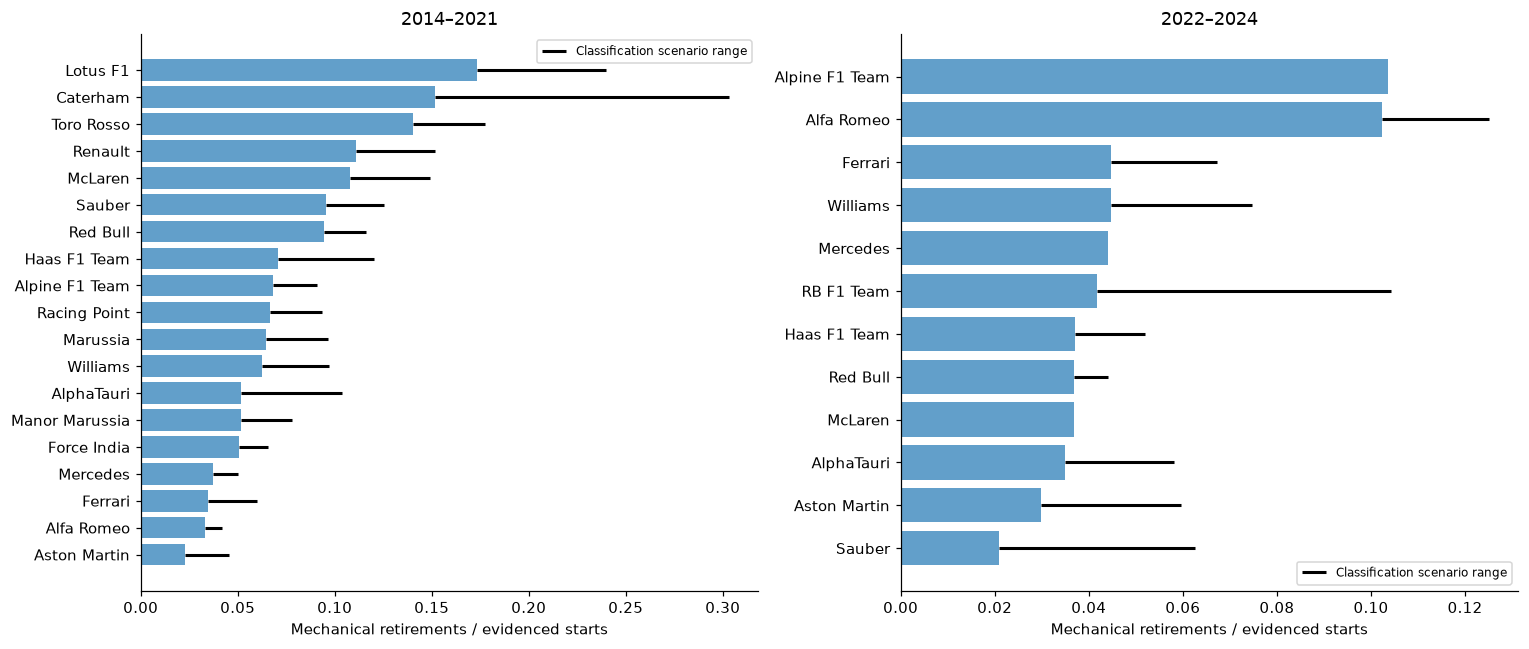

**Answer under the documented strict mapping:** 2014–2021: Lotus F1, 17.3% (13/75); classification range 17.3%–24.0%; robust top rank across these scenarios: False; 2022–2024: Alpine F1 Team, 10.4% (14/135); classification range 10.4%–10.4%; robust top rank across these scenarios: False. 0 entry start statuses remain unresolved. Treat overlapping rankings as provisional, not precise estimates of intrinsic constructor reliability. The status mapping is conservative and not an exhaustive external verification of every retirement.

In [13]:
MECHANICAL = {'Mechanical','Engine','Gearbox','Transmission','Clutch','Hydraulics','Electrical','Radiator','Brakes',
'Differential','Overheating','Driveshaft','Fuel pressure','Water pressure','Throttle','Steering','Electronics',
'Heat shield fire','Exhaust','Oil leak','Water leak','Fuel pump','Track rod','Oil pressure','Engine fire',
'Engine misfire','Wheel rim','Pneumatics','Wheel bearing','Fuel system','Oil line','Launch control',
'Drivetrain','Ignition','Halfshaft','Crankshaft','Battery','Alternator','Oil pump','Fuel leak','Injection',
'Distributor','Turbo','CV joint','Water pump','Spark plugs','Fuel pipe','Oil pipe','Axle','Water pipe',
'Magneto','Supercharger','Power Unit','ERS','Brake duct','Cooling system'}
NONMECHANICAL = {'Accident','Collision','Collision damage','Spun off','Disqualified','Excluded',
'Underweight','Physical','Injured','Injury','Driver unwell','Illness','Fatal accident','Eye injury',
'Did not qualify','Did not prequalify','107% Rule','Withdrew','Out of fuel','Refuelling','Fuel rig',
'Safety','Safety concerns','Not restarted'}
def status_category(s):
    if s=='Finished' or re.fullmatch(r'\+\d+ Laps?',s): return 'finished'
    if s in MECHANICAL: return 'mechanical'
    if s in NONMECHANICAL: return 'nonmechanical'
    return 'ambiguous'
status_map=clean['status'].copy();status_map['category']=status_map['status'].map(status_category)
status_map['reason']=status_map['category'].map({'finished':'Reached classification with finished/lapped status',
 'mechanical':'Named component/system failure; cause inferred from status unless contradicted by evidence',
 'nonmechanical':'Incident, regulation, health, explicit non-start or operational cause',
 'ambiguous':'Generic retirement or component damage without sufficiently clear cause'})
display(analysis_table(status_map,'q3_status_mapping'))
q3=analysis.loc[analysis['year'].between(2014,2024)].copy()
q3['era']=np.where(q3['year'].le(2021),'2014–2021','2022–2024')
q3['cause_category']=q3['status'].map(status_category)
event_evidence=pd.concat([clean['lap_times'][keys],clean['pit_stops'][keys]]).drop_duplicates()
evidence_index=pd.MultiIndex.from_frame(event_evidence)
has_record=pd.MultiIndex.from_frame(q3[keys]).isin(evidence_index)
incident=q3['status'].isin(['Accident','Collision','Collision damage','Spun off','Fatal accident'])
start_evidence=q3['laps'].gt(0)|has_record|incident
explicit_nonstart=q3['laps'].eq(0)&q3['status'].isin(['Withdrew','Did not qualify','Did not prequalify','107% Rule','Illness','Injured','Injury','Driver unwell'])
q3['start_state']=np.select([start_evidence.to_numpy(dtype=bool),explicit_nonstart.to_numpy(dtype=bool)],['evidenced start','non-start'],default='unresolved')
# Identify evidence-backed rows by race and driver surname; assert unique matches.
correction_specs=[
 (1002,'Hartley','nonmechanical','https://www.formula1.com/en/latest/article/hamilton-snatches-victory-from-raikkonen-in-dramatic-italian-grand-prix.3bTryOzt5SeoQskWeGqkQY','Collision at the start; raw Brakes is misleading.'),
 (1092,'Albon','nonmechanical','https://www.formula1.com/en/video/alex-albon-reveals-contact-on-race-start-forced-his-lap-1-dnf-in-japan.1746189374282722401','Contact at race start preceded retirement.'),
 (926,'Grosjean','mechanical','https://www.formula1.com/en/latest/article/winners-and-losers-the-australian-grand-prix.25r22GSjGljdejJl4AYL9U','Opening-lap retirement from power loss.')]
corrections=[]
for race,surname,category,url,note in correction_specs:
    mask=q3['raceId'].eq(race)&q3['surname'].eq(surname)
    assert mask.sum()==1
    row=q3.loc[mask].iloc[0]
    corrections.append({'raceId':race,'driverId':int(row.driverId),'surname':surname,
        'raw_status':row.status,'cause_category':category,'start_state':'evidenced start','source':url,'reason':note})
    q3.loc[mask,'cause_category']=category;q3.loc[mask,'start_state']='evidenced start'

# Resolve the zero-lap cases flagged by the initial audit using official F1 sources.
# These annotations are retrospective analysis evidence, NEVER modeling features.
DNS_SOURCES = [
 (913,'Kobayashi','https://www.formula1.com/en/latest/article/race-selected-team-and-driver-quotes.TcJiEt8tNocEWcLVHIiFO.TcJiEt8tNocEWcLVHIiFO'),
 (927,'Stevens','https://www.formula1.com/en/latest/article/fuel-system-issue-rules-stevens-out-of-malaysia.1kvtGOnc8Ar0qkMda2shpA'),
 (929,'Button','https://www.formula1.com/en/latest/article/button-a-non-starter-in-bahrain.1B9dPjmGnEDJaPKHVqpLi7'),
 (934,'Nasr','https://www.formula1.com/en/results/2015/races/925/great-britain/race-result'),
 (937,'Hülkenberg','https://www.formula1.com/en/results/2015/races/928/belgium/race-result'),
 (948,'Kvyat','https://www.formula1.com/en/latest/article/sunday-in-melbourne-team-by-team.3N3ZpWbGMRqSO8f9cI6K6i'),
 (949,'Vettel','https://www.formula1.com/en/latest/article/vettel-retires-on-bahrain-formation-lap.27juYcGClFJmBVSFyffNGK.27juYcGClFJmBVSFyffNGK'),
 (949,'Palmer','https://www.formula1.com/en/latest/article/vettel-retires-on-bahrain-formation-lap.27juYcGClFJmBVSFyffNGK.27juYcGClFJmBVSFyffNGK'),
 (971,'Vandoorne','https://www.formula1.com/en/latest/article/vandoorne-fails-to-start-in-bahrain.5l5dlGw1kkG406QGcIMq0k.5l5dlGw1kkG406QGcIMq0k.5l5dlGw1kkG406QGcIMq0k.5l5dlGw1kkG406QGcIMq0k.5l5dlGw1kkG406QGcIMq0k'),
 (972,'Alonso','https://www.formula1.com/en/results/2017/drivers/FERALO01/fernando-alonso'),
 (978,'Palmer','https://www.formula1.com/en/results/2017/drivers/JOLPAL02/jolyon-palmer'),
 (983,'Räikkönen','https://www.formula1.com/en/latest/article/raikkonen-fails-to-take-the-start-in-malaysia.7AZSUN9JKgG4A8M0MWeawo'),
 (1034,'Hülkenberg','https://www.formula1.com/en/latest/article/hulkenberg-fails-to-make-british-gp-start-after-last-minute-technical-issue.3LeAfHcnAKt5KhqxFjDB82.3LeAfHcnAKt5KhqxFjDB82'),
 (1037,'Sainz','https://www.formula1.com/en/results/2020/races/1051/belgium/race-result'),
 (1056,'Leclerc','https://www.formula1.com/en/latest/article/ferrari-investigation-finds-that-leclerc-qualifying-crash-was-to-blame-for.1NNRCOZ5MBnYZVLGSg1HrC'),
 (1065,'Tsunoda','https://www.formula1.com/en/latest/article/tsunoda-laments-tough-run-of-luck-as-alphatauri-suffer-double-dnf-at-home.3pSVbpPAzh40rX98SI3SHn'),
 (1075,'Tsunoda','https://www.formula1.com/en/results/2022/drivers/YUKTSU01/yuki-tsunoda'),
 (1112,'Tsunoda','https://www.formula1.com/en/results/2023/drivers/YUKTSU01/yuki-tsunoda'),
 (1115,'Sainz','https://www.formula1.com/en/latest/article/breaking-sainz-ruled-out-of-qatar-grand-prix-due-to-pre-race-technical-issue.31LMb3qvRyvp5w6x5Orv0o'),
 (1118,'Leclerc','https://www.formula1.com/en/results/2023/races/1224/brazilian-grand-prix/race-result'),
 (1132,'Gasly','https://www.formula1.com/en/video/gasly-reveals-why-he-wasnt-able-to-start-the-race-at-silverstone.1803934435576335700')]
for race,surname,url in DNS_SOURCES:
    mask=q3['raceId'].eq(race)&q3['surname'].eq(surname)
    assert mask.sum()==1
    row=q3.loc[mask].iloc[0]
    corrections.append({'raceId':race,'driverId':int(row.driverId),'surname':surname,
      'raw_status':row.status,'cause_category':row.cause_category,'start_state':'non-start',
      'source':url,'reason':'Official F1 result/report identifies DNS, rather than an opening-lap race retirement.'})
    q3.loc[mask,'start_state']='non-start'
for race,surname,category,url,note in [
 (944,'Sainz','mechanical','https://www.formula1.com/en/latest/article/winners-and-losers-brazil.6JM8K5zPDcKeLYgQH2WDDA','Started from pits; engine cut out on opening race lap.'),
 (1000,'Leclerc','nonmechanical','https://www.formula1.com/en/latest/article/leclerc-very-happy-with-sauber-progress-despite-hungary-disappointment.6gFtjPvj1eiKo46AQkesqw','Contact on opening race lap damaged the car.')]:
    mask=q3['raceId'].eq(race)&q3['surname'].eq(surname);assert mask.sum()==1
    row=q3.loc[mask].iloc[0]
    corrections.append({'raceId':race,'driverId':int(row.driverId),'surname':surname,
      'raw_status':row.status,'cause_category':category,'start_state':'evidenced start','source':url,'reason':note})
    q3.loc[mask,'start_state']='evidenced start';q3.loc[mask,'cause_category']=category

corrections_table=pd.DataFrame(corrections)
corrections_table['reviewed_on']='2026-10-19'
display(analysis_table(corrections_table,'q3_sourced_corrections'))
q3['is_start']=q3['start_state'].eq('evidenced start')
q3['strict_failure']=q3['is_start']&q3['cause_category'].eq('mechanical')
q3['ambiguous_started']=q3['is_start']&q3['cause_category'].eq('ambiguous')
q3['unresolved_start']=q3['start_state'].eq('unresolved')
q3['unresolved_possible_failure']=q3['unresolved_start']&q3['cause_category'].isin(['mechanical','ambiguous'])
q3_summary=q3.groupby(['constructorId','constructor_name','era']).agg(
    entries=('resultId','size'),starts=('is_start','sum'),mechanical=('strict_failure','sum'),
    ambiguous_started=('ambiguous_started','sum'),unresolved_starts=('unresolved_start','sum'),
    unresolved_possible_failure=('unresolved_possible_failure','sum')).reset_index()
q3_summary['rate']=q3_summary['mechanical']/q3_summary['starts']
q3_summary['lower95'],q3_summary['upper95']=wilson(q3_summary['mechanical'],q3_summary['starts'])
# Conservative scenario minimum: all unresolved entries started, none mechanically failed.
q3_summary['scenario_low']=q3_summary['mechanical']/(q3_summary['starts']+q3_summary['unresolved_starts'])
# Scenario maximum: ambiguous started causes and only mechanically plausible unresolved starts failed.
q3_summary['scenario_high']=(q3_summary['mechanical']+q3_summary['ambiguous_started']+q3_summary['unresolved_possible_failure'])/(q3_summary['starts']+q3_summary['unresolved_possible_failure'])
q3_summary['rank']=q3_summary.groupby('era')['rate'].rank(method='min',ascending=False)
display(analysis_table(q3_summary.sort_values(['era','rate'],ascending=[True,False]),'q3_constructor_rates'))
review_cols=['raceId','driverId','year','name','surname','constructor_name','grid','laps','status','cause_category','start_state']
analysis_table(q3.loc[q3['unresolved_start']|q3['cause_category'].eq('ambiguous'),review_cols],'q3_cases_for_review')
analysis_table(q3[review_cols+['strict_failure']],'q3_entry_classification')
fig,axes=plt.subplots(1,2,figsize=(14,6))
for ax,era in zip(axes,['2014–2021','2022–2024']):
    part=q3_summary.loc[q3_summary['era'].eq(era)].sort_values('rate')
    y=np.arange(len(part));ax.barh(part['constructor_name'],part['rate'],alpha=.7)
    ax.hlines(y,part['scenario_low'],part['scenario_high'],color='black',linewidth=2,label='Classification scenario range')
    ax.set_title(era);ax.set_xlabel('Mechanical retirements / evidenced starts');ax.legend(fontsize=8)
analysis_plot('q3_mechanical_retirement_rates')
q3_leaders=[]
for era,d in q3_summary.groupby('era'):
    leader=d.nlargest(1,'rate').iloc[0]
    others=d.loc[d['constructorId'].ne(leader.constructorId)]
    robust=bool(leader.scenario_low>others.scenario_high.max())
    q3_leaders.append(f'{era}: {leader.constructor_name}, {leader.rate:.1%} ({int(leader.mechanical)}/{int(leader.starts)}); '
                     f'classification range {leader.scenario_low:.1%}–{leader.scenario_high:.1%}; robust top rank across these scenarios: {robust}')
q3_answer='; '.join(q3_leaders)
display(Markdown('**Answer under the documented strict mapping:** '+q3_answer+'. '
    f'{int(q3.unresolved_start.sum())} entry start statuses remain unresolved. '
    'Treat overlapping rankings as provisional, not precise estimates of intrinsic constructor reliability. The status mapping is conservative and not an exhaustive external verification of every retirement.'))


**Answer.** Under the strict mechanical-cause definition, Lotus F1 has the highest 2014–2021 rate (13/75 starts, 17.3%); Alpine F1 Team has the highest 2022–2024 rate (14/135, 10.4%). Neither top rank is robust to all ambiguous-cause classification scenarios. These are constructor-ID rates, with separate identities across team renames and an operational actual-start denominator.

# 15. Pre-race feature construction
The candidate model table uses 1950–2024 entries, including entries with missing qualifying data. No row is removed because of a future crash, retirement or disqualification. Race roster, constructor and grid in the retrospective results table are treated as pre-race entry information per the brief, although this dataset does not provide timestamped entry-list revisions.

**Identity disagreement policy:** use the constructor associated with the result entry as the canonical team; join qualifying by driver–race and retain its different constructor ID only in the audit. The ten 2015 disagreements concern Manor Marussia versus Marussia. Do not silently merge constructor identities across seasons. This is an explicit retrospective identity assumption.

**History:** last five driver appearances (podium fraction and mean finishing order); last five constructor race events (mean driver podium fraction). Historical form crosses season boundaries but includes only events within the preceding **365 days**; average only those available past events, with counts exposing cold starts. The exported gap audit motivates this rule: constructor IDs can reappear decades later (Aston Martin and Mercedes), and returning drivers can also have long absences. Five events and one year are fixed design choices: they emphasize recent form and prevent stale constructor identities from linking across long absences. Historical group ablation evaluates their contribution; the exact window length has not been separately optimized. Aggregate both constructor cars in a race before rolling/lagging. Sorting is by actual race date and round, never by race ID.

**Standings:** join the snapshot after the immediately preceding completed race in the same season, including drivers absent from that race if the standings table contains them. First-race points and wins are zero; rank stays unknown. A missing snapshot later in the season remains missing. No current-race standing is used. Prior-race standings deliberately omit any current-weekend sprint points; this is stale but valid information before the main race.

**Qualifying:** position plus Q1 time relative to the fastest recorded Q1 in the same session. Relative pace removes much of circuit lap-length variation. Pre-2006 stored qualifying sessions are not identical to knockout Q1; formats, weather and missing sessions remain limitations. Q2/Q3 time features are deferred because their missingness is structural. Grid-minus-qualifying is named a position difference, not a penalty.

The exported feature list is an explicit allowlist. Current results/status/points/laps, future histories, source dates, join identifiers and the target never enter `X`. Candidate features require subsequent model comparison and ablation; these cells do not assert they are the final optimal set.


In [14]:
FEATURE_GROUPS = {
 'grid':['grid_position','grid_zero'],
 'qualifying':['qualifying_position','grid_qualifying_difference','q1_relative_pct','qualifying_missing','q1_missing'],
 'driver_form':['driver_podium_rate_5','driver_mean_finish_5','driver_history_count_5'],
 'constructor_form':['constructor_podium_rate_5','constructor_history_count_5'],
 'standings':['driver_points_before','driver_rank_before','driver_wins_before',
              'constructor_points_before','constructor_rank_before','constructor_wins_before'],
 'context':['circuit_category','constructor_category','driver_age','home_race','year','round']}
FEATURE_COLUMNS=[c for cols in FEATURE_GROUPS.values() for c in cols]
CATEGORICAL=['circuit_category','constructor_category']
NUMERIC=[c for c in FEATURE_COLUMNS if c not in CATEGORICAL]

def bounded_history(frame, entity, value_columns):
    """Last five strictly earlier appearances, no older than 365 days."""
    grouped=frame.groupby(entity,sort=False)
    lags={col:[] for col in value_columns}; valid_lags=[]
    for step in range(1,6):
        source_date=grouped['date'].shift(step)
        age=(frame['date']-source_date).dt.days
        valid=age.between(1,365).fillna(False)
        valid_lags.append(valid)
        for col in value_columns:
            lags[col].append(grouped[col].shift(step).where(valid))
    values={col:pd.concat(series,axis=1).mean(axis=1) for col,series in lags.items()}
    count=pd.concat(valid_lags,axis=1).sum(axis=1)
    last_date=grouped['date'].shift(1).where(valid_lags[0])
    return values,count,last_date

def build_prerace_features(entry_rows, races, drivers, circuits, qualifying, driver_standings, constructor_standings, start_year=1950, end_year=2024):
    # Keep only deliberate source columns; never carry the audit table into X.
    b=entry_rows[['raceId','driverId','constructorId','grid','positionOrder']].copy()
    b['podium']=b['positionOrder'].le(3).astype('int8')
    calendar=races[['raceId','year','round','date','circuitId']].sort_values(['date','round','raceId']).copy()
    calendar['previous_raceId']=calendar.groupby('year')['raceId'].shift(1).astype('Int64')
    calendar['previous_race_date']=calendar.groupby('year')['date'].shift(1)
    b=b.merge(calendar,on='raceId',validate='many_to_one').sort_values(['date','round','raceId','driverId']).reset_index(drop=True)
    # Lagged, time-bounded driver history preserves genuine cold starts.
    driver_values,driver_count,driver_source=bounded_history(b,'driverId',['podium','positionOrder'])
    b['driver_podium_rate_5']=driver_values['podium']
    b['driver_mean_finish_5']=driver_values['positionOrder']
    b['driver_history_count_5']=driver_count
    b['driver_form_source_date']=driver_source
    # One row per constructor/event BEFORE shifting: no teammate result leakage.
    cr=b.groupby(['constructorId','raceId','date','round'],as_index=False).agg(race_podium_fraction=('podium','mean'))
    cr=cr.sort_values(['date','round','raceId','constructorId'])
    constructor_values,constructor_count,constructor_source=bounded_history(cr,'constructorId',['race_podium_fraction'])
    cr['constructor_podium_rate_5']=constructor_values['race_podium_fraction']
    cr['constructor_history_count_5']=constructor_count
    cr['constructor_form_source_date']=constructor_source
    b=b.merge(cr[['constructorId','raceId','constructor_podium_rate_5','constructor_history_count_5','constructor_form_source_date']],
              on=['constructorId','raceId'],validate='many_to_one')
    # Snapshot joins use previous race explicitly, not a shift over current entrant rows.
    for source,entity,prefix in [(driver_standings,'driverId','driver'),(constructor_standings,'constructorId','constructor')]:
        snap=source[['raceId',entity,'points','position','wins']].rename(columns={'raceId':'previous_raceId',
             'points':prefix+'_points_before','position':prefix+'_rank_before','wins':prefix+'_wins_before'})
        b=b.merge(snap,on=['previous_raceId',entity],how='left',validate='many_to_one')
        opener=b['previous_raceId'].isna()
        b.loc[opener,[prefix+'_points_before',prefix+'_wins_before']]=0
    q=qualifying[['raceId','driverId','position','q1_seconds']].rename(columns={'position':'qualifying_position'}).copy()
    fastest=q.groupby('raceId')['q1_seconds'].transform('min')
    q['q1_relative_pct']=100*(q['q1_seconds']/fastest-1)
    b=b.merge(q[['raceId','driverId','qualifying_position','q1_relative_pct']],on=['raceId','driverId'],how='left',validate='one_to_one')
    b['grid_position']=b['grid'].where(b['grid'].gt(0))
    b['grid_zero']=b['grid'].eq(0).astype('int8')
    b['grid_qualifying_difference']=b['grid_position']-b['qualifying_position']
    b['qualifying_missing']=b['qualifying_position'].isna().astype('int8')
    b['q1_missing']=b['q1_relative_pct'].isna().astype('int8')
    b=b.merge(drivers[['driverId','dob','nationality']],on='driverId',validate='many_to_one')
    b=b.merge(circuits[['circuitId','country']],on='circuitId',validate='many_to_one')
    b['driver_age']=(b['date']-b['dob']).dt.days/365.2425
    b['home_race']=[int(country in NATIONALITY_COUNTRIES[nat.strip()])
                   for nat,country in zip(b['nationality'],b['country'].replace({'United States':'USA'}))]
    b['circuit_category']='circuit_'+b['circuitId'].astype(str)
    b['constructor_category']='constructor_'+b['constructorId'].astype(str)
    b=b.loc[b['year'].between(start_year,end_year)].sort_values(['date','raceId','driverId']).reset_index(drop=True)
    return b

# Descriptive event gaps across the full historical dataset.

raw_event_history=entries.merge(clean['races'][['raceId','date','round','year']],on='raceId',validate='many_to_one')
gap_rows=[]
for entity in ['driverId','constructorId']:
    events=raw_event_history.drop_duplicates([entity,'raceId']).sort_values(['date','round','raceId'])
    events['prior_date']=events.groupby(entity)['date'].shift(1)
    events['gap_days']=(events['date']-events['prior_date']).dt.days
    gap_rows.append({'entity':entity,'events_with_gap_over_365_days':int(events['gap_days'].gt(365).sum()),
                     'maximum_gap_days':float(events['gap_days'].max())})
gap_audit=pd.DataFrame(gap_rows);gap_audit.to_csv(FEATURES/'history_gap_audit.csv',index=False);display(gap_audit)

feature_args=(clean['races'],clean['drivers'],clean['circuits'],clean['qualifying'],clean['driver_standings'],clean['constructor_standings'])

(FEATURES/'feature_groups.json').write_text(json.dumps(FEATURE_GROUPS,indent=2))


,entity,events_with_gap_over_365_days,maximum_gap_days
0,driverId,416,3745.0
1,constructorId,99,22170.0


738

## 16. Historical feature coverage and model inputs

**Question:** How does a pre-race binary podium classifier perform on held-out races across the historical
dataset, including periods before 2003? This is broader than asking whether older training rows improve
modern performance.

Use expanding historical backtests. In each fold, every training race precedes every validation race,
which precedes every test race. **Whole races remain together**. Historical form is updated only from
results strictly before the prediction date, including earlier completed races within a test period;
the fitted model and threshold do not update during that period. This models sequential pre-race use,
not a forecast of an entire season made before its opening race.

The target, deterministic historical duplicate policy, canonical constructor convention and 365-day/five-event
history rule are unchanged. All retained championship entries are available, including historical Indianapolis
500 entries; their different context and shared-drive ambiguity remain limitations. There is no claim to
evaluate the first races without initial training history. Reporting-era boundaries are descriptive groupings.
Historical entries include non-qualifiers and withdrawals; the population is not restricted to actual
starters. Era scores can partly reflect those population differences, so the grid-only baseline and
positive prevalence are important context. Outcome/status fields are never included in the model inputs.

Compare fixed logistic, forest and shallow-NN configurations on identical rows within each fold
and feature set. **Historical core** omits the five qualifying features; **qualifying extended** requests the
original 24. A training-only support check drops all-missing or constant columns; unsupported qualifying
columns cannot be learned simply by imputing them. If two feature sets become identical, reuse the same
fit, giving an exact controlled comparison. Missing qualifying entries are retained. A grid-only logistic
baseline gives context beyond the no-information AP baseline (positive prevalence).

This is a retrospective experiment designed after reviewing the modern project. Settings are fixed before
these historical results are computed; no test result selects a model, feature set or threshold. The
2022-2024 outcomes were already inspected in the original project and are not a newly untouched holdout.


,reporting_era,entries,races,podium_rate,qualifying_position_coverage,q1_pace_coverage,driver_form_coverage,driver_standings_coverage,grid_zero_fraction,recorded_nonqualifier_fraction
0,1950-1979,7836,328,0.1261,0.0,0.0000,0.8814,0.756,0.0784,0.0579
1,1980-2002,9862,369,0.1122,0.157,0.1537,0.9777,0.8841,0.0948,0.0918
2,2003-2013,4344,200,0.1381,0.9982,0.9814,0.9825,0.9174,0.0016,0.0009
3,2014-2021,3267,160,0.1469,0.9951,0.9835,0.9878,0.9452,0.0119,0.0000
4,2022-2024,1359,68,0.1501,1.0,0.9904,0.9912,0.95,0.0294,0.0000


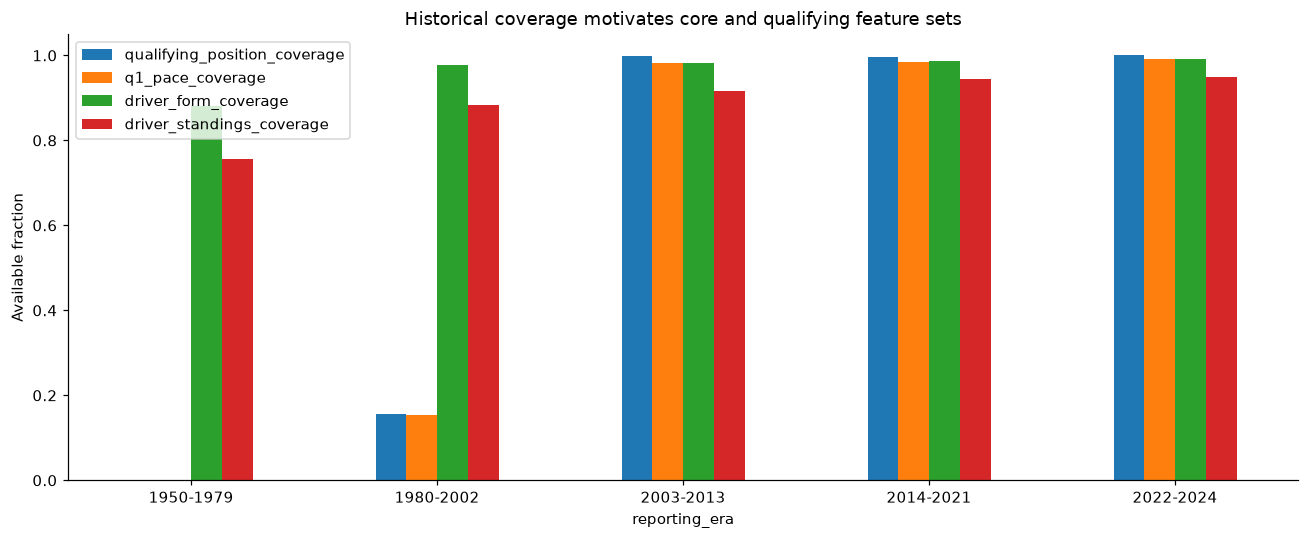

All-era candidate table: 26,668 entries in 1,125 races.


In [15]:
from sklearn.base import clone as era_clone
from sklearn.metrics import accuracy_score as era_accuracy_score
from threadpoolctl import threadpool_limits as era_thread_limits
import time as era_time

ERA_OUT = ROOT / 'artifacts' / 'all_era'
(ERA_OUT / 'figures').mkdir(parents=True, exist_ok=True)
era_table = build_prerace_features(entries, *feature_args, start_year=1950, end_year=2024)
assert len(era_table) == len(entries) and not era_table.duplicated(['raceId','driverId']).any()
ERA_LABELS = ['1950-1979','1980-2002','2003-2013','2014-2021','2022-2024']
era_table['reporting_era'] = pd.cut(era_table['year'], [1949,1979,2002,2013,2021,2024], labels=ERA_LABELS)
for era_source in ['driver_form_source_date','constructor_form_source_date','previous_race_date']:
    era_present = era_table[era_source].notna()
    assert era_table.loc[era_present,era_source].lt(era_table.loc[era_present,'date']).all()
assert set(FEATURE_COLUMNS).isdisjoint({'podium','positionOrder','status','statusId','laps','points','raceId','driverId'})
era_qualifying = set(FEATURE_GROUPS['qualifying'])
ERA_FEATURE_SETS = {'historical_core':[c for c in FEATURE_COLUMNS if c not in era_qualifying],
                    'qualifying_extended':list(FEATURE_COLUMNS)}
assert len(ERA_FEATURE_SETS['historical_core']) == 19
era_coverage = era_table.groupby('reporting_era', observed=True).agg(
    entries=('driverId','size'), races=('raceId','nunique'), podium_rate=('podium','mean'),
    qualifying_position_coverage=('qualifying_position',lambda x:x.notna().mean()),
    q1_pace_coverage=('q1_relative_pct',lambda x:x.notna().mean()),
    driver_form_coverage=('driver_podium_rate_5',lambda x:x.notna().mean()),
    driver_standings_coverage=('driver_rank_before',lambda x:x.notna().mean()),
    grid_zero_fraction=('grid_zero','mean')).reset_index()
era_context=era_table[['raceId','driverId','reporting_era']].merge(
    entry_audit[['raceId','driverId','status']],on=['raceId','driverId'],validate='one_to_one')
era_context['recorded_nonqualifier']=era_context['status'].isin(['Did not qualify','Did not prequalify','107% Rule'])
era_nonqualifier=era_context.groupby('reporting_era',observed=True)['recorded_nonqualifier'].mean()
era_coverage['recorded_nonqualifier_fraction']=era_coverage['reporting_era'].map(era_nonqualifier).astype(float)
era_coverage.to_csv(ERA_OUT/'era_data_coverage.csv',index=False)
era_export_columns=list(dict.fromkeys(['raceId','driverId','date','year','reporting_era','podium']+FEATURE_COLUMNS))
era_table[era_export_columns].to_csv(
    ERA_OUT/'all_era_modeling_table.csv',index=False)
era_table[['raceId','driverId','date','previous_raceId','previous_race_date',
           'driver_form_source_date','constructor_form_source_date']].to_csv(ERA_OUT/'feature_provenance.csv',index=False)
display(era_coverage.round(4))
era_coverage.set_index('reporting_era')[['qualifying_position_coverage','q1_pace_coverage',
    'driver_form_coverage','driver_standings_coverage']].plot.bar(figsize=(12,5),rot=0)
plt.ylabel('Available fraction');plt.title('Historical coverage motivates core and qualifying feature sets')
plt.tight_layout();plt.savefig(ERA_OUT/'figures/01_historical_coverage.png',dpi=150,bbox_inches='tight')
plt.show();plt.close()
print(f'All-era candidate table: {len(era_table):,} entries in {era_table.raceId.nunique():,} races.')


## 17. Fixed evaluation protocol and whole-race split checks

Eight expanding-history folds cover held-out races from 1957 onward, spanning every reporting era.
The first five years supply initial training history. Validation years and other gaps are shown explicitly;
this is not an out-of-sample score for every year or every race. Training always begins in 1950.
Folds may reuse past races as training/validation in later evaluations, as information accumulates;
within each fold the three sets are disjoint. Test windows do not overlap each other.

Within each fold, select the feature-set/model combination by **validation AP**, with validation F1 as a
tie-breaker. Each decision threshold maximizes validation F1 on the fixed 0.05-0.95 grid. Freeze that selection before scoring that fold's test period. Report every predefined candidate,
not only the selected one. No global winner will be selected from test scores.


In [16]:
import warnings
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.exceptions import ConvergenceWarning

def best_f1_threshold(y_true, probability):
    grid = np.linspace(0.05, 0.95, 181)
    scores = np.array([f1_score(y_true, probability >= t, zero_division=0) for t in grid])
    return float(grid[np.flatnonzero(scores == scores.max())[0]])

def score_row(name, split, y_true, probability, threshold):
    prediction = probability >= threshold
    return {'model': name, 'split': split,
            'roc_auc': roc_auc_score(y_true, probability),
            'pr_auc': average_precision_score(y_true, probability),
            'f1': f1_score(y_true, prediction, zero_division=0),
            'precision': precision_score(y_true, prediction, zero_division=0),
            'recall': recall_score(y_true, prediction, zero_division=0),
            'threshold': threshold, 'rows': len(y_true), 'podium_rate': float(np.mean(y_true))}

In [17]:
ERA_FOLDS = [
    {'fold':'F1','train_end':1954,'validation_start':1955,'validation_end':1956,'test_start':1957,'test_end':1959},
    {'fold':'F2','train_end':1959,'validation_start':1960,'validation_end':1961,'test_start':1962,'test_end':1969},
    {'fold':'F3','train_end':1969,'validation_start':1970,'validation_end':1971,'test_start':1972,'test_end':1979},
    {'fold':'F4','train_end':1979,'validation_start':1980,'validation_end':1981,'test_start':1982,'test_end':1989},
    {'fold':'F5','train_end':1989,'validation_start':1990,'validation_end':1991,'test_start':1992,'test_end':2002},
    {'fold':'F6','train_end':2002,'validation_start':2003,'validation_end':2004,'test_start':2005,'test_end':2013},
    {'fold':'F7','train_end':2013,'validation_start':2014,'validation_end':2015,'test_start':2016,'test_end':2021},
    {'fold':'F8','train_end':2019,'validation_start':2020,'validation_end':2021,'test_start':2022,'test_end':2024},
]
era_fold_frames = {}
era_split_rows = []
era_race_assignments = []
era_previously_tested = set()
for era_fold in ERA_FOLDS:
    era_parts = {
        'train':era_table.loc[era_table['year'].le(era_fold['train_end'])].copy(),
        'validation':era_table.loc[era_table['year'].between(era_fold['validation_start'],era_fold['validation_end'])].copy(),
        'test':era_table.loc[era_table['year'].between(era_fold['test_start'],era_fold['test_end'])].copy()}
    era_ids = {name:set(frame['raceId']) for name,frame in era_parts.items()}
    assert all(not era_ids[a]&era_ids[b] for a,b in [('train','validation'),('train','test'),('validation','test')])
    assert era_parts['train']['date'].max() < era_parts['validation']['date'].min()
    assert era_parts['validation']['date'].max() < era_parts['test']['date'].min()
    assert not era_previously_tested & era_ids['test']
    era_previously_tested |= era_ids['test']
    for era_partition,era_frame in era_parts.items():
        assert era_frame['podium'].nunique()==2
        era_split_rows.append({'fold':era_fold['fold'],'partition':era_partition,
            'first_year':int(era_frame['year'].min()),'last_year':int(era_frame['year'].max()),
            'entries':len(era_frame),'races':era_frame['raceId'].nunique(),
            'podium_rate':float(era_frame['podium'].mean())})
        era_race_assignments.append(era_frame[['raceId','year','date']].drop_duplicates().assign(
            fold=era_fold['fold'],partition=era_partition))
    era_fold_frames[era_fold['fold']] = era_parts
era_plan = pd.DataFrame(era_split_rows)
era_assignments = pd.concat(era_race_assignments,ignore_index=True)
assert era_assignments.groupby(['fold','raceId'])['partition'].nunique().eq(1).all()
era_plan.to_csv(ERA_OUT/'split_plan.csv',index=False)
era_assignments.to_csv(ERA_OUT/'race_split_assignments.csv',index=False)
display(era_plan)
ERA_ESTIMATORS = {
    'logistic_regression':LogisticRegression(C=1.0,max_iter=1500,random_state=903),
    'random_forest':RandomForestClassifier(n_estimators=200,max_depth=8,min_samples_leaf=8,random_state=903,n_jobs=2),
    'shallow_nn':MLPClassifier(hidden_layer_sizes=(32,),activation='relu',alpha=0.01,
        early_stopping=False,n_iter_no_change=15,max_iter=5000,random_state=903)}
era_protocol = {'folds':ERA_FOLDS,'feature_sets':ERA_FEATURE_SETS,
    'estimators':{name:estimator.get_params() for name,estimator in ERA_ESTIMATORS.items()},
    'selection':'Validation AP, then validation F1; grid-only baseline excluded from main-model selection.',
    'threshold_grid':{'minimum':0.05,'maximum':0.95,'points':181},
    'seed':903,'drop_columns':'All-missing or constant in training only',
    'current_test_previously_inspected':True,
    'interpretation':'Fixed retrospective temporal backtests; no claim of independent predictions for initial warm-up years.'}
(ERA_OUT/'protocol_before_fit.json').write_text(json.dumps(era_protocol,indent=2,default=str))
print('Whole-race and chronological split checks passed for all 8 folds.')

# These development experiments are fixed before fitting; none uses test outcomes.
development_protocol={'ablation':{'folds':[f['fold'] for f in ERA_FOLDS],
    'model':'fixed extended random forest','groups':list(FEATURE_GROUPS),
    'grid_ablation_also_removes':'grid_qualifying_difference','score':'validation AP'},
    'preprocessing':{'folds':['F6','F8'],'model':'fixed extended logistic regression',
    'pairs':['median imputation versus standardization order','median imputation versus quantile-normalization order']},
    'xai':{'models':'actual extended logistic fits in F1-F8','background':'training only',
    'explained_rows':'validation only','local_case':'F8 closest to validation-fixed threshold'},
    'nn_budget':{'before':300,'after_allowance':5000,'selection_uses':'training/validation only'}}
(ERA_OUT/'development_protocol_before_fit.json').write_text(json.dumps(development_protocol,indent=2))


,fold,partition,first_year,last_year,entries,races,podium_rate
0,F1,train,1950,1954,986,41,0.126775
1,F1,validation,1955,1956,340,15,0.138235
2,F1,test,1957,1959,596,28,0.140940
3,F2,train,1950,1959,1922,84,0.133195
4,F2,validation,1960,1961,440,18,0.122727
5,F2,test,1962,1969,1668,82,0.147482
6,F3,train,1950,1969,4030,184,0.137965
7,F3,validation,1970,1971,557,24,0.129264
8,F3,test,1972,1979,3249,120,0.110803
9,F4,train,1950,1979,7836,328,0.126085


Whole-race and chronological split checks passed for all 8 folds.


1006

### 17.1 Training-only evidence and feature hypotheses

Each field has a pre-race rationale. Quantify availability, variation and target association using
training rows separately at every cutoff. These descriptive plots motivate a candidate feature set;
later ablations measure conditional contributions after fitting. No test evidence selects a field.


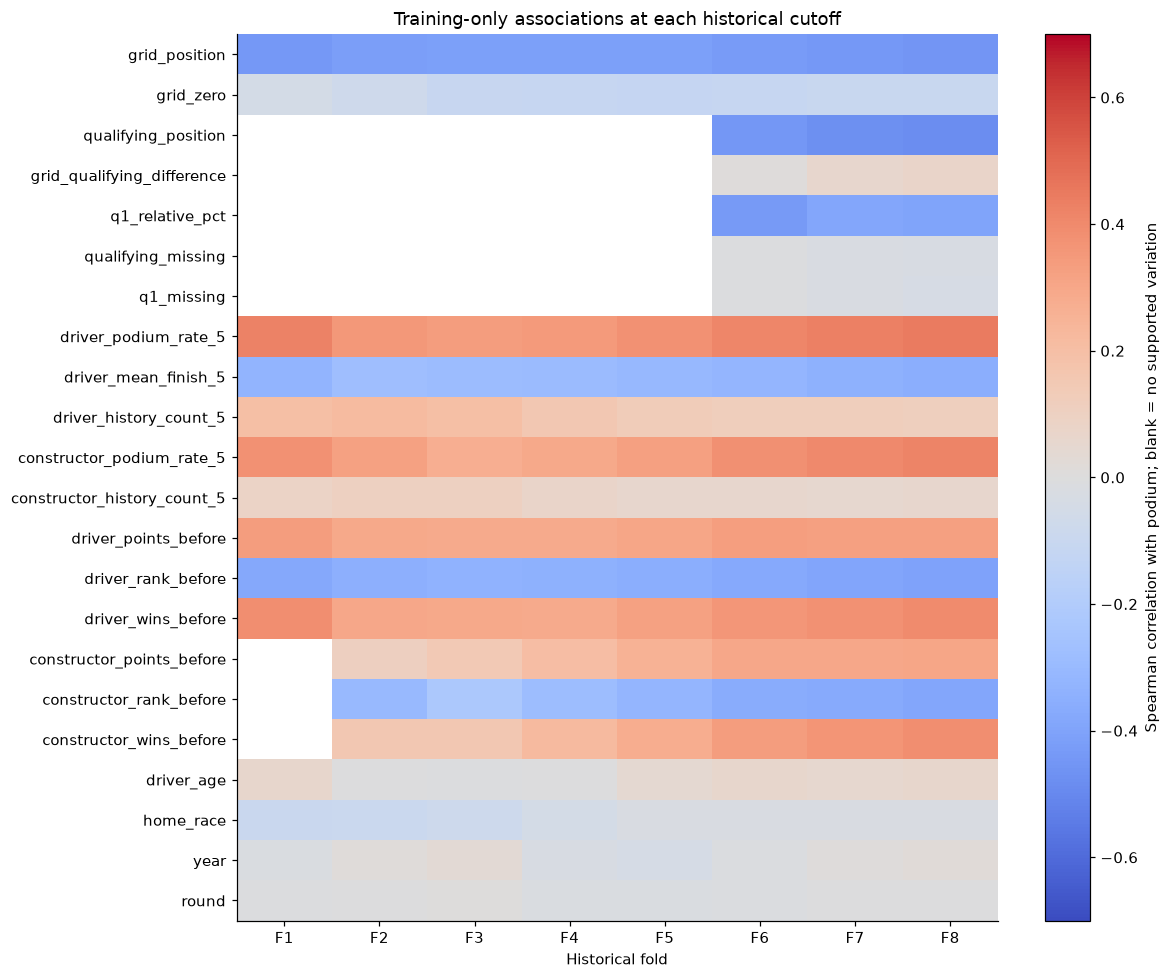

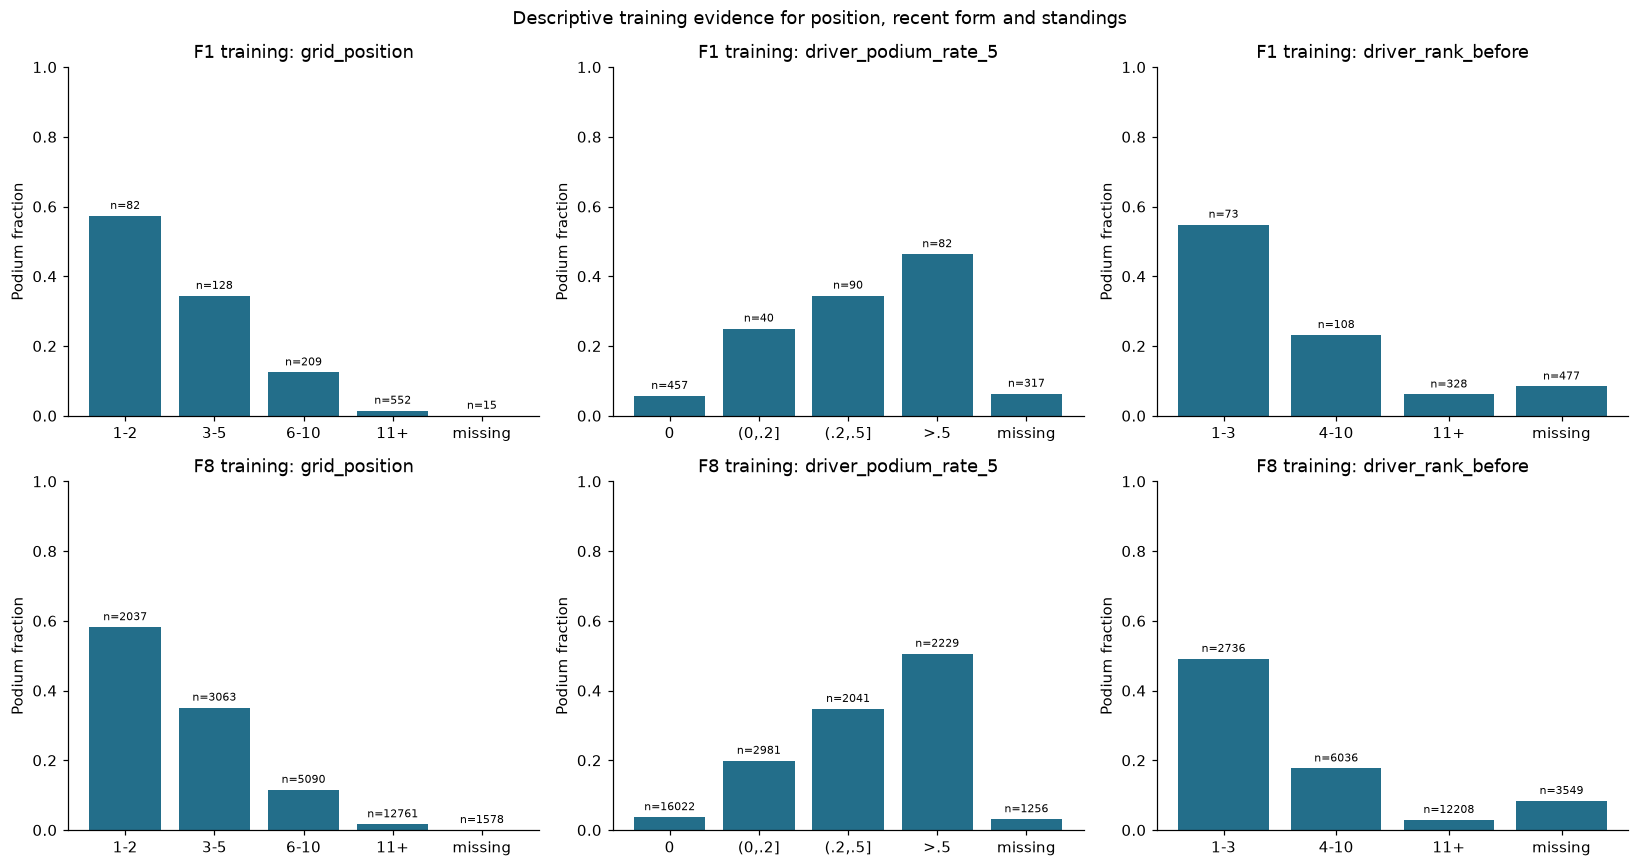

,fold,group,feature,training_entries,available_fraction,distinct_observed,spearman_with_podium
168,F8,grid,grid_position,24529,0.9357,34,-0.4493
169,F8,grid,grid_zero,24529,1.0000,2,-0.0990
170,F8,qualifying,qualifying_position,24529,0.3407,28,-0.4864
171,F8,qualifying,grid_qualifying_difference,24529,0.3394,29,0.0747
172,F8,qualifying,q1_relative_pct,24529,0.3352,7807,-0.3975
173,F8,qualifying,qualifying_missing,24529,1.0000,2,-0.0311
174,F8,qualifying,q1_missing,24529,1.0000,2,-0.0332
175,F8,driver_form,driver_podium_rate_5,24529,0.9488,11,0.4469
176,F8,driver_form,driver_mean_finish_5,24529,0.9488,334,-0.3549
177,F8,driver_form,driver_history_count_5,24529,1.0000,6,0.1146


**Feature rationale.** **grid:** Starting nearer the front should associate with a podium; distinguish a known zero grid from a positive position. **qualifying:** Qualifying rank and session-relative pace describe pre-race speed; availability flags expose historical coverage drift. **driver_form:** Recent completed appearances proxy driver/car performance; history count identifies cold starts. **constructor_form:** Earlier team event averages proxy car/team strength without counting both cars as separate time steps. **standings:** The prior-race snapshot summarizes season performance; season openers have zero points/wins and unknown rank. **context:** Circuit/team identity, age, home indicator, year and round allow differing race context; this can overfit identities and time. Correlations describe associations rather than causation; missingness and correlated predictors limit their interpretation. All 24 fields form a prespecified candidate set. Training support and validation core/extended comparisons determine the effective set per fold; the later six-group ablation measures conditional predictive contribution. An association alone does not justify an optimal feature claim.

In [18]:
# Training-only evidence; no validation or test label is used in these plots.
EVIDENCE_OUT = ERA_OUT / 'development'
(EVIDENCE_OUT / 'figures').mkdir(parents=True, exist_ok=True)
evidence_rows = []
for fold, parts in era_fold_frames.items():
    frame = parts['train']
    for group, columns in FEATURE_GROUPS.items():
        for column in columns:
            values = frame[column]
            correlation = np.nan
            if column not in CATEGORICAL and values.nunique(dropna=True) > 1:
                correlation = pd.to_numeric(values).corr(frame['podium'], method='spearman')
            evidence_rows.append({'fold':fold, 'group':group, 'feature':column,
                'training_entries':len(frame), 'available_fraction':float(values.notna().mean()),
                'distinct_observed':int(values.nunique(dropna=True)),
                'spearman_with_podium':correlation})
feature_evidence = pd.DataFrame(evidence_rows)
feature_evidence.to_csv(EVIDENCE_OUT/'training_feature_evidence.csv',index=False)
fig, ax = plt.subplots(figsize=(11,9))
matrix = feature_evidence.loc[~feature_evidence.feature.isin(CATEGORICAL)].pivot(
    index='feature', columns='fold', values='spearman_with_podium').reindex(NUMERIC)
im = ax.imshow(matrix.to_numpy(),aspect='auto',cmap='coolwarm',vmin=-.7,vmax=.7)
ax.set_xticks(range(8),matrix.columns); ax.set_yticks(range(len(matrix)),matrix.index)
ax.set(title='Training-only associations at each historical cutoff',xlabel='Historical fold')
fig.colorbar(im,ax=ax,label='Spearman correlation with podium; blank = no supported variation')
fig.tight_layout(); fig.savefig(EVIDENCE_OUT/'figures/01_training_feature_associations.png',dpi=150,bbox_inches='tight')
plt.show(); plt.close(fig)

fig, axes = plt.subplots(2,3,figsize=(15,8))
bin_definitions = {
    'grid_position':([0,2,5,10,100],['1-2','3-5','6-10','11+']),
    'driver_podium_rate_5':([-.001,0,.2,.5,1.001],['0','(0,.2]','(.2,.5]','>.5']),
    'driver_rank_before':([0,3,10,1000],['1-3','4-10','11+'])}
bin_rows=[]
for row, fold in enumerate(['F1','F8']):
    frame=era_fold_frames[fold]['train']
    for ax,(feature,(edges,labels)) in zip(axes[row],bin_definitions.items()):
        bins=pd.cut(frame[feature],edges,labels=labels).astype('string').fillna('missing')
        summary=frame.assign(bin=bins).groupby('bin',observed=True).podium.agg(['mean','size'])
        order=[label for label in labels+['missing'] if label in summary.index]
        summary=summary.reindex(order)
        ax.bar(order,summary['mean'],color='#236e8a')
        ax.set(title=f'{fold} training: {feature}',ylabel='Podium fraction',ylim=(0,1))
        for i,r in enumerate(summary.itertuples()):
            ax.text(i,r.mean+.02,f'n={r.size}',ha='center',fontsize=7)
        bin_rows.extend({'fold':fold,'feature':feature,'bin':str(i),'podium_rate':r['mean'],'entries':int(r['size'])}
                        for i,r in summary.iterrows())
fig.suptitle('Descriptive training evidence for position, recent form and standings')
fig.tight_layout(); fig.savefig(EVIDENCE_OUT/'figures/02_training_feature_bins.png',dpi=150,bbox_inches='tight')
plt.show(); plt.close(fig)
pd.DataFrame(bin_rows).to_csv(EVIDENCE_OUT/'training_feature_bins.csv',index=False)

feature_hypotheses = {
 'grid':'Starting nearer the front should associate with a podium; distinguish a known zero grid from a positive position.',
 'qualifying':'Qualifying rank and session-relative pace describe pre-race speed; availability flags expose historical coverage drift.',
 'driver_form':'Recent completed appearances proxy driver/car performance; history count identifies cold starts.',
 'constructor_form':'Earlier team event averages proxy car/team strength without counting both cars as separate time steps.',
 'standings':'The prior-race snapshot summarizes season performance; season openers have zero points/wins and unknown rank.',
 'context':'Circuit/team identity, age, home indicator, year and round allow differing race context; this can overfit identities and time.'}
registry=pd.DataFrame([{'feature':c,'group':g,'cutoff_justification':feature_hypotheses[g],
                       'categorical':c in CATEGORICAL}
                      for g,columns in FEATURE_GROUPS.items() for c in columns])
registry.to_csv(EVIDENCE_OUT/'feature_registry.csv',index=False)
display(feature_evidence.loc[feature_evidence.fold.eq('F8')].round(4))
display(Markdown('**Feature rationale.** '+ ' '.join(f'**{g}:** {text}' for g,text in feature_hypotheses.items())+
    ' Correlations describe associations rather than causation; missingness and correlated predictors limit their interpretation. '
    'All 24 fields form a prespecified candidate set. Training support and validation core/extended comparisons determine the '
    'effective set per fold; the later six-group ablation measures conditional predictive contribution. '
    'An association alone does not justify an optimal feature claim.'))


## 18. Fit and compare the three model families

The fixed configurations are logistic regression (C=1), random forest (200 trees, depth 8, minimum leaf
8) and a one-hidden-layer NN with 32 ReLU units and alpha 0.01. These are starting configurations, not
claims of optimal settings for every historical era. The NN uses training-loss stopping with 15-iteration
patience and a generous 5,000-iteration allowance. A later cell compares its training/validation metrics
with the archived 300-iteration baseline and checks the stopping diagnostics. The allowance is not a claim of optimal training.

Median imputation, standardization and category encoding fit on each fold's training rows only. Unknown
later categories are ignored. Train-constant/all-missing inputs are omitted identically for all three
families. Core/extended variants that become identical reuse one fitted model. The grid-only logistic
control receives the same rows and threshold rule and is excluded from main-model selection.

Every candidate's training and validation scores are computed before the fold's test evaluation.
Validation AP selects the model/feature variant; validation F1 determines its decision threshold.


In [19]:
def era_make_pipeline(estimator, columns):
    num = [c for c in columns if c not in CATEGORICAL]
    cat = [c for c in columns if c in CATEGORICAL]
    return Pipeline([('prepare',ColumnTransformer([
        ('numeric',Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
                             ('scale',StandardScaler())]),num),
        ('category',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat)],
        remainder='drop',sparse_threshold=0)),('model',era_clone(estimator))])

def era_x(frame, columns):
    out=frame[columns].copy()
    for col in columns:
        if col not in CATEGORICAL:
            out[col]=pd.to_numeric(out[col],errors='coerce').astype(float)
    return out

era_metric_rows=[]; era_prediction_frames=[]; era_fit_rows=[]; era_choice_rows=[]
era_fitted={}; era_selected={}; era_candidates={}; era_started=era_time.monotonic()
for era_fold in ERA_FOLDS:
    fold_name=era_fold['fold']; parts=era_fold_frames[fold_name]
    train_frame=parts['train']; val_frame=parts['validation']
    train_y=train_frame['podium'].astype(int); val_y=val_frame['podium'].astype(int)
    candidates=[]; cache={}
    specifications=[(variant,name,columns,estimator)
        for variant,columns in ERA_FEATURE_SETS.items() for name,estimator in ERA_ESTIMATORS.items()]
    specifications.append(('grid_only','logistic_regression',['grid_position','grid_zero'],ERA_ESTIMATORS['logistic_regression']))
    # Complete training and validation selection before accessing this fold's test outcomes.
    for variant,name,requested,estimator in specifications:
        usable=[c for c in requested if train_frame[c].nunique(dropna=True)>1]
        assert usable and set(usable).issubset(requested)
        key=(name,tuple(usable)); reused=key in cache
        if not reused:
            fitted=era_make_pipeline(estimator,usable)
            with warnings.catch_warnings(record=True) as caught, era_thread_limits(limits=2):
                warnings.simplefilter('always',ConvergenceWarning)
                fitted.fit(era_x(train_frame,usable),train_y)
            val_p=fitted.predict_proba(era_x(val_frame,usable))[:,1]
            train_p=fitted.predict_proba(era_x(train_frame,usable))[:,1]
            cutoff=best_f1_threshold(val_y,val_p)
            cache[key]=(fitted,val_p,train_p,cutoff,[str(w.message) for w in caught])
        fitted,val_p,train_p,cutoff,fit_warnings=cache[key]
        candidate={'feature_set':variant,'model':name,'columns':usable,'pipeline':fitted,
                   'threshold':cutoff,'validation_ap':average_precision_score(val_y,val_p),
                   'validation_f1':f1_score(val_y,val_p>=cutoff,zero_division=0)}
        candidates.append(candidate);era_fitted[(fold_name,variant,name)]=candidate
        for partition,target,probability in [('train',train_y,train_p),('validation',val_y,val_p)]:
            metric=score_row(name,partition,target,probability,cutoff)
            metric.update({'fold':fold_name,'feature_set':variant,'effective_features':len(usable)})
            era_metric_rows.append(metric)
        encoder=fitted.named_steps['prepare']; num=[c for c in usable if c not in CATEGORICAL]
        assert np.allclose(encoder.named_transformers_['numeric'].named_steps['impute'].statistics_,
                           np.nanmedian(era_x(train_frame,num).to_numpy(),axis=0))
        era_fit_rows.append({'fold':fold_name,'feature_set':variant,'model':name,'reused_equivalent_fit':reused,
            'requested_features':len(requested),'effective_features':len(usable),'columns':'|'.join(usable),
            'unsupported_or_constant':'|'.join(c for c in requested if c not in usable),
            'training_qualifying_coverage':float(train_frame['qualifying_position'].notna().mean()),
            'threshold':cutoff,'nn_iterations':getattr(fitted.named_steps['model'],'n_iter_',np.nan),
            'fit_warnings':' | '.join(fit_warnings)})
    selected=sorted([c for c in candidates if c['feature_set']!='grid_only'],
        key=lambda c:(-c['validation_ap'],-c['validation_f1'],c['feature_set'],c['model']))[0]
    era_selected[fold_name]=selected
    era_choice_rows.append({'fold':fold_name,'feature_set':selected['feature_set'],'model':selected['model'],
        'validation_ap':selected['validation_ap'],'validation_f1':selected['validation_f1'],
        'threshold':selected['threshold'],'test_start':era_fold['test_start'],'test_end':era_fold['test_end']})
    era_candidates[fold_name]=list(candidates)
    print(f"{fold_name}: test {era_fold['test_start']}-{era_fold['test_end']}; validation selected "
          f"{selected['feature_set']} / {selected['model']} (AP {selected['validation_ap']:.3f})",flush=True)
    (ERA_OUT/'progress.json').write_text(json.dumps({'completed_fold':fold_name,
        'test_years':[era_fold['test_start'],era_fold['test_end']],
        'elapsed_seconds':round(era_time.monotonic()-era_started,2),
        'validation_selected_feature_set':selected['feature_set'],
        'validation_selected_model':selected['model']},indent=2))
era_metrics=pd.DataFrame(era_metric_rows)
era_fits=pd.DataFrame(era_fit_rows);era_choices=pd.DataFrame(era_choice_rows)
era_fits.to_csv(ERA_OUT/'fit_diagnostics.csv',index=False)
era_choices.to_csv(ERA_OUT/'validation_selected_policy.csv',index=False)
display(era_metrics.round(4))


F1: test 1957-1959; validation selected historical_core / random_forest (AP 0.402)


F2: test 1962-1969; validation selected historical_core / logistic_regression (AP 0.450)


F3: test 1972-1979; validation selected historical_core / logistic_regression (AP 0.416)


F4: test 1982-1989; validation selected historical_core / logistic_regression (AP 0.503)


F5: test 1992-2002; validation selected historical_core / logistic_regression (AP 0.548)


F6: test 2005-2013; validation selected historical_core / logistic_regression (AP 0.687)


F7: test 2016-2021; validation selected qualifying_extended / logistic_regression (AP 0.729)


F8: test 2022-2024; validation selected qualifying_extended / logistic_regression (AP 0.730)


,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate,fold,feature_set,effective_features
0,logistic_regression,train,0.9092,0.5591,0.5905,0.4530,0.8480,0.180,986,0.1268,F1,historical_core,16
1,logistic_regression,validation,0.8267,0.4019,0.4921,0.3924,0.6596,0.180,340,0.1382,F1,historical_core,16
2,random_forest,train,0.9301,0.6707,0.6230,0.5278,0.7600,0.235,986,0.1268,F1,historical_core,16
3,random_forest,validation,0.8148,0.4025,0.5179,0.4462,0.6170,0.235,340,0.1382,F1,historical_core,16
4,shallow_nn,train,0.9990,0.9942,0.9344,0.9030,0.9680,0.260,986,0.1268,F1,historical_core,16
...,...,...,...,...,...,...,...,...,...,...,...,...,...
107,random_forest,validation,0.9234,0.7126,0.7004,0.6917,0.7094,0.395,780,0.1500,F8,qualifying_extended,24
108,shallow_nn,train,0.9751,0.8488,0.7182,0.5796,0.9438,0.195,24529,0.1247,F8,qualifying_extended,24
109,shallow_nn,validation,0.9002,0.6511,0.6454,0.6045,0.6923,0.195,780,0.1500,F8,qualifying_extended,24
110,logistic_regression,train,0.8900,0.4926,0.5406,0.5407,0.5405,0.350,24529,0.1247,F8,grid_only,2


### 18.1 NN optimization-budget trial

The preceding fits use the same 32-unit architecture with a larger allowance. The cell below embeds
the actual earlier 300-iteration development metrics, not fabricated or recomputed test comparisons.
The full earlier executed notebook and outputs are archived separately. The stopping rule depends on
training loss; model-family/feature-set selection still uses only validation AP and F1.


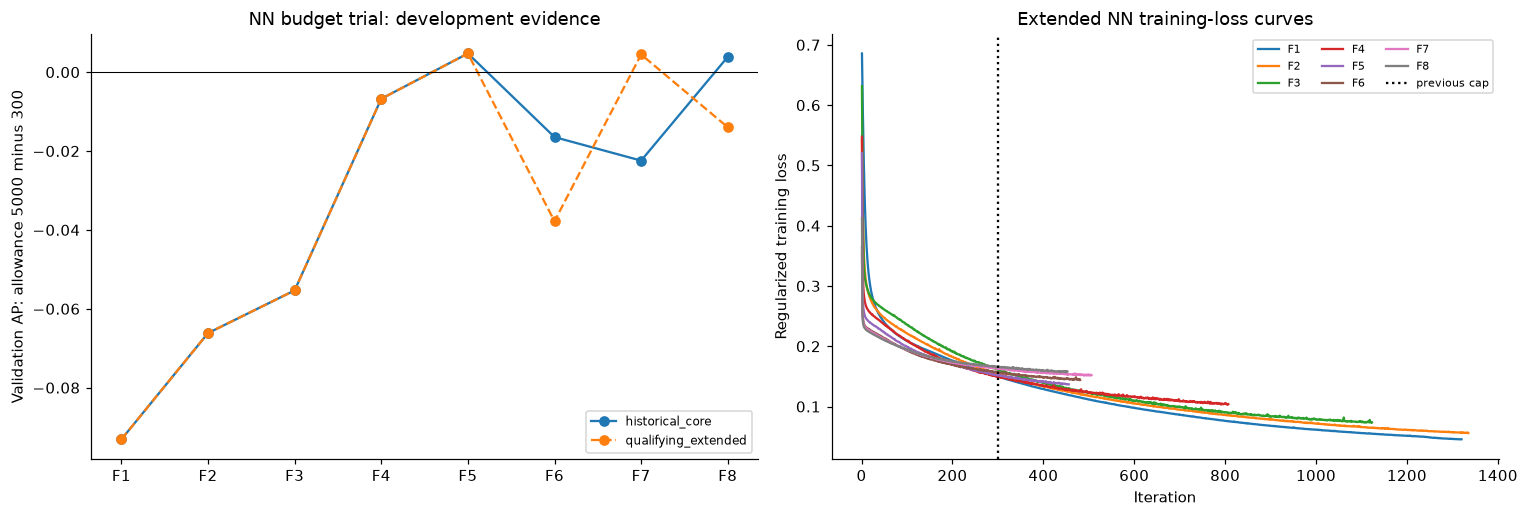

,fold,feature_set,iterations,max_iter,hit_cap,loss,no_improvement_count,patience,tol
0,F1,historical_core,1320,5000,False,0.045744,16,15,0.0001
1,F1,qualifying_extended,1320,5000,False,0.045744,16,15,0.0001
2,F2,historical_core,1335,5000,False,0.056089,16,15,0.0001
3,F2,qualifying_extended,1335,5000,False,0.056089,16,15,0.0001
4,F3,historical_core,1123,5000,False,0.073776,16,15,0.0001
5,F3,qualifying_extended,1123,5000,False,0.073776,16,15,0.0001
6,F4,historical_core,807,5000,False,0.103990,16,15,0.0001
7,F4,qualifying_extended,807,5000,False,0.103990,16,15,0.0001
8,F5,historical_core,456,5000,False,0.136796,16,15,0.0001
9,F5,qualifying_extended,456,5000,False,0.136796,16,15,0.0001


,fold,feature_set,pr_auc_300,pr_auc_5000,ap_change,f1_300,f1_5000
1,F1,historical_core,0.3525,0.2594,-0.0931,0.4366,0.3636
3,F1,qualifying_extended,0.3525,0.2594,-0.0931,0.4366,0.3636
5,F2,historical_core,0.3565,0.2903,-0.0662,0.4167,0.3761
7,F2,qualifying_extended,0.3565,0.2903,-0.0662,0.4167,0.3761
9,F3,historical_core,0.3661,0.3108,-0.0553,0.4536,0.4076
11,F3,qualifying_extended,0.3661,0.3108,-0.0553,0.4536,0.4076
13,F4,historical_core,0.2908,0.2840,-0.0068,0.4189,0.3920
15,F4,qualifying_extended,0.2908,0.2840,-0.0068,0.4189,0.3920
17,F5,historical_core,0.4852,0.4900,0.0047,0.5152,0.5446
19,F5,qualifying_extended,0.4852,0.4900,0.0047,0.5152,0.5446


**NN stopping result:** 11/11 unique fits stopped before the generous cap. This verifies the configured training-loss stopping rule, not a global optimum or improved generalization. The architecture, seed, regularization and rows stayed fixed. The 300-iteration baseline is an archived executed notebook; its training/validation snapshot is embedded here for a self-contained recorded comparison. Both sides remain visible. The updated family competes on validation AP under the same frozen fold policy; test scores do not decide the budget.

In [20]:
NN_300_SNAPSHOT = json.loads('{"metrics": [{"model": "shallow_nn", "split": "train", "roc_auc": 0.973138211382114, "pr_auc": 0.8659895915734498, "f1": 0.6611570247933884, "precision": 0.5042016806722689, "recall": 0.96, "threshold": 0.135, "rows": 986, "podium_rate": 0.1267748478701825, "fold": "F1", "feature_set": "historical_core", "effective_features": 16}, {"model": "shallow_nn", "split": "validation", "roc_auc": 0.7830222932248929, "pr_auc": 0.3524851421446167, "f1": 0.4366197183098591, "precision": 0.3263157894736842, "recall": 0.6595744680851063, "threshold": 0.135, "rows": 340, "podium_rate": 0.138235294117647, "fold": "F1", "feature_set": "historical_core", "effective_features": 16}, {"model": "shallow_nn", "split": "train", "roc_auc": 0.973138211382114, "pr_auc": 0.8659895915734498, "f1": 0.6611570247933884, "precision": 0.5042016806722689, "recall": 0.96, "threshold": 0.135, "rows": 986, "podium_rate": 0.1267748478701825, "fold": "F1", "feature_set": "qualifying_extended", "effective_features": 16}, {"model": "shallow_nn", "split": "validation", "roc_auc": 0.7830222932248929, "pr_auc": 0.3524851421446167, "f1": 0.4366197183098591, "precision": 0.3263157894736842, "recall": 0.6595744680851063, "threshold": 0.135, "rows": 340, "podium_rate": 0.138235294117647, "fold": "F1", "feature_set": "qualifying_extended", "effective_features": 16}, {"model": "shallow_nn", "split": "train", "roc_auc": 0.9746820603241296, "pr_auc": 0.8741343785061836, "f1": 0.5952941176470589, "precision": 0.4259259259259259, "recall": 0.98828125, "threshold": 0.075, "rows": 1922, "podium_rate": 0.1331945889698231, "fold": "F2", "feature_set": "historical_core", "effective_features": 19}, {"model": "shallow_nn", "split": "validation", "roc_auc": 0.8184129725580502, "pr_auc": 0.3564879204610223, "f1": 0.4166666666666667, "precision": 0.3333333333333333, "recall": 0.5555555555555556, "threshold": 0.075, "rows": 440, "podium_rate": 0.1227272727272727, "fold": "F2", "feature_set": "historical_core", "effective_features": 19}, {"model": "shallow_nn", "split": "train", "roc_auc": 0.9746820603241296, "pr_auc": 0.8741343785061836, "f1": 0.5952941176470589, "precision": 0.4259259259259259, "recall": 0.98828125, "threshold": 0.075, "rows": 1922, "podium_rate": 0.1331945889698231, "fold": "F2", "feature_set": "qualifying_extended", "effective_features": 19}, {"model": "shallow_nn", "split": "validation", "roc_auc": 0.8184129725580502, "pr_auc": 0.3564879204610223, "f1": 0.4166666666666667, "precision": 0.3333333333333333, "recall": 0.5555555555555556, "threshold": 0.075, "rows": 440, "podium_rate": 0.1227272727272727, "fold": "F2", "feature_set": "qualifying_extended", "effective_features": 19}, {"model": "shallow_nn", "split": "train", "roc_auc": 0.9733379099828946, "pr_auc": 0.873450874912429, "f1": 0.680796403339756, "precision": 0.5294705294705294, "recall": 0.9532374100719424, "threshold": 0.1649999999999999, "rows": 4030, "podium_rate": 0.1379652605459057, "fold": "F3", "feature_set": "historical_core", "effective_features": 19}, {"model": "shallow_nn", "split": "validation", "roc_auc": 0.7999140893470791, "pr_auc": 0.3661372879042061, "f1": 0.4536082474226804, "precision": 0.360655737704918, "recall": 0.6111111111111112, "threshold": 0.1649999999999999, "rows": 557, "podium_rate": 0.1292639138240574, "fold": "F3", "feature_set": "historical_core", "effective_features": 19}, {"model": "shallow_nn", "split": "train", "roc_auc": 0.9733379099828946, "pr_auc": 0.873450874912429, "f1": 0.680796403339756, "precision": 0.5294705294705294, "recall": 0.9532374100719424, "threshold": 0.1649999999999999, "rows": 4030, "podium_rate": 0.1379652605459057, "fold": "F3", "feature_set": "qualifying_extended", "effective_features": 19}, {"model": "shallow_nn", "split": "validation", "roc_auc": 0.7999140893470791, "pr_auc": 0.3661372879042061, "f1": 0.4536082474226804, "precision": 0.360655737704918, "recall": 0.6111111111111112, "threshold": 0.1649999999999999, "rows": 557, "podium_rate": 0.1292639138240574, "fold": "F3", "feature_set": "qualifying_extended", "effective_features": 19}, {"model": "shallow_nn", "split": "train", "roc_auc": 0.9769739798138408, "pr_auc": 0.8790193083985636, "f1": 0.5742983751846381, "precision": 0.4055068836045056, "recall": 0.9838056680161944, "threshold": 0.06, "rows": 7836, "podium_rate": 0.1260847371107708, "fold": "F4", "feature_set": "historical_core", "effective_features": 19}, {"model": "shallow_nn", "split": "validation", "roc_auc": 0.8403455990125743, "pr_auc": 0.2908023288675831, "f1": 0.4189189189189189, "precision": 0.2966507177033493, "recall": 0.7126436781609196, "threshold": 0.06, "rows": 832, "podium_rate": 0.1045673076923077, "fold": "F4", "feature_set": "historical_core", "effective_features": 19}, {"model": "shallow_nn", "split": "train", "roc_auc": 0.9769739798138408, "pr_auc": 0.8790193083985636, "f1": 0.5742983751846381, "precision": 0.4055068836045056, "recall": 0.9838056680161944, "threshold": 0.06, "rows": 7836, "podium_rate": 0.1260847371107708, "fold": "F4", "feature_set": "qualifying_extended", "effective_features": 19}, {"model": "shallow_nn", "split": "validation", "roc_auc": 0.8403455990125743, "pr_auc": 0.2908023288675831, "f1": 0.4189189189189189, "precision": 0.2966507177033493, "recall": 0.7126436781609196, "threshold": 0.06, "rows": 832, "podium_rate": 0.1045673076923077, "fold": "F4", "feature_set": "qualifying_extended", "effective_features": 19}, {"model": "shallow_nn", "split": "train", "roc_auc": 0.9754305409283356, "pr_auc": 0.8525057024539369, "f1": 0.7647058823529411, "precision": 0.7898975109809663, "recall": 0.7410714285714286, "threshold": 0.3999999999999999, "rows": 12339, "podium_rate": 0.1179998379123105, "fold": "F5", "feature_set": "historical_core", "effective_features": 19}, {"model": "shallow_nn", "split": "validation", "roc_auc": 0.9048223350253808, "pr_auc": 0.4852471349381776, "f1": 0.5151515151515151, "precision": 0.5, "recall": 0.53125, "threshold": 0.3999999999999999, "rows": 1081, "podium_rate": 0.0888066604995374, "fold": "F5", "feature_set": "historical_core", "effective_features": 19}, {"model": "shallow_nn", "split": "train", "roc_auc": 0.9754305409283356, "pr_auc": 0.8525057024539369, "f1": 0.7647058823529411, "precision": 0.7898975109809663, "recall": 0.7410714285714286, "threshold": 0.3999999999999999, "rows": 12339, "podium_rate": 0.1179998379123105, "fold": "F5", "feature_set": "qualifying_extended", "effective_features": 19}, {"model": "shallow_nn", "split": "validation", "roc_auc": 0.9048223350253808, "pr_auc": 0.4852471349381776, "f1": 0.5151515151515151, "precision": 0.5, "recall": 0.53125, "threshold": 0.3999999999999999, "rows": 1081, "podium_rate": 0.0888066604995374, "fold": "F5", "feature_set": "qualifying_extended", "effective_features": 19}, {"model": "shallow_nn", "split": "train", "roc_auc": 0.972456126101446, "pr_auc": 0.8299446517619881, "f1": 0.6966292134831461, "precision": 0.5560933940774487, "recall": 0.932219570405728, "threshold": 0.145, "rows": 17698, "podium_rate": 0.1183749576223302, "fold": "F6", "feature_set": "historical_core", "effective_features": 19}, {"model": "shallow_nn", "split": "validation", "roc_auc": 0.8745165886423774, "pr_auc": 0.5637304430145401, "f1": 0.5352112676056338, "precision": 0.5135135135135135, "recall": 0.5588235294117647, "threshold": 0.145, "rows": 680, "podium_rate": 0.15, "fold": "F6", "feature_set": "historical_core", "effective_features": 19}, {"model": "shallow_nn", "split": "train", "roc_auc": 0.9730297566850018, "pr_auc": 0.838596893715196, "f1": 0.5967460778617083, "precision": 0.4288995614950929, "recall": 0.9804295942720764, "threshold": 0.0849999999999999, "rows": 17698, "podium_rate": 0.1183749576223302, "fold": "F6", "feature_set": "qualifying_extended", "effective_features": 24}, {"model": "shallow_nn", "split": "validation", "roc_auc": 0.8640002713888324, "pr_auc": 0.486820213554584, "f1": 0.5367647058823529, "precision": 0.4294117647058823, "recall": 0.7156862745098039, "threshold": 0.0849999999999999, "rows": 680, "podium_rate": 0.15, "fold": "F6", "feature_set": "qualifying_extended", "effective_features": 24}, {"model": "shallow_nn", "split": "train", "roc_auc": 0.967330368056948, "pr_auc": 0.8053019830142035, "f1": 0.7322754895340986, "precision": 0.6717249922576649, "recall": 0.8048237476808905, "threshold": 0.2749999999999999, "rows": 22042, "podium_rate": 0.1222665819798566, "fold": "F7", "feature_set": "historical_core", "effective_features": 19}, {"model": "shallow_nn", "split": "validation", "roc_auc": 0.9265301853740164, "pr_auc": 0.7028941011881146, "f1": 0.6960352422907489, "precision": 0.6991150442477876, "recall": 0.6929824561403509, "threshold": 0.2749999999999999, "rows": 785, "podium_rate": 0.1452229299363057, "fold": "F7", "feature_set": "historical_core", "effective_features": 19}, {"model": "shallow_nn", "split": "train", "roc_auc": 0.9695145575392792, "pr_auc": 0.8200609484627869, "f1": 0.6189856957087126, "precision": 0.4541984732824427, "recall": 0.9714285714285714, "threshold": 0.0999999999999999, "rows": 22042, "podium_rate": 0.1222665819798566, "fold": "F7", "feature_set": "qualifying_extended", "effective_features": 24}, {"model": "shallow_nn", "split": "validation", "roc_auc": 0.8731534499437864, "pr_auc": 0.5475801931071016, "f1": 0.5375, "precision": 0.4174757281553398, "recall": 0.7543859649122807, "threshold": 0.0999999999999999, "rows": 785, "podium_rate": 0.1452229299363057, "fold": "F7", "feature_set": "qualifying_extended", "effective_features": 24}, {"model": "shallow_nn", "split": "train", "roc_auc": 0.968458680284804, "pr_auc": 0.8230710320839805, "f1": 0.7440970006381621, "precision": 0.7264797507788162, "recall": 0.762589928057554, "threshold": 0.4099999999999999, "rows": 24529, "podium_rate": 0.1246687594276163, "fold": "F8", "feature_set": "historical_core", "effective_features": 19}, {"model": "shallow_nn", "split": "validation", "roc_auc": 0.9032112516275412, "pr_auc": 0.6976358640231186, "f1": 0.6577777777777778, "precision": 0.6851851851851852, "recall": 0.6324786324786325, "threshold": 0.4099999999999999, "rows": 780, "podium_rate": 0.15, "fold": "F8", "feature_set": "historical_core", "effective_features": 19}, {"model": "shallow_nn", "split": "train", "roc_auc": 0.9691760608305564, "pr_auc": 0.8192275749858582, "f1": 0.6474267529902338, "precision": 0.4872006606110652, "recall": 0.9646827992151732, "threshold": 0.145, "rows": 24529, "podium_rate": 0.1246687594276163, "fold": "F8", "feature_set": "qualifying_extended", "effective_features": 24}, {"model": "shallow_nn", "split": "validation", "roc_auc": 0.9062665171262456, "pr_auc": 0.6650542393767196, "f1": 0.6617100371747212, "precision": 0.5855263157894737, "recall": 0.7606837606837606, "threshold": 0.145, "rows": 780, "podium_rate": 0.15, "fold": "F8", "feature_set": "qualifying_extended", "effective_features": 24}], "baseline_max_iter": 300, "new_allowance": 5000, "recorded_baseline": "Executed pre-completion historical notebook; archived with its complete outputs.", "protocol_sha256": "54b51e2f2afc8df49075c254922fe0c0e6684bd1a3f4d12b81d773f0fb070b36"}')
# The embedded 300-iteration snapshot contains development metrics only, not test scores.
nn_before = pd.DataFrame(NN_300_SNAPSHOT['metrics'])
nn_after = era_metrics.loc[era_metrics.model.eq('shallow_nn') & era_metrics['split'].isin(['train','validation'])]
nn_budget_comparison = nn_before.merge(nn_after,on=['fold','feature_set','model','split'],suffixes=('_300','_5000'),validate='one_to_one')
nn_budget_comparison['ap_change']=nn_budget_comparison.pr_auc_5000-nn_budget_comparison.pr_auc_300
nn_budget_comparison['f1_change']=nn_budget_comparison.f1_5000-nn_budget_comparison.f1_300
nn_budget_comparison.to_csv(EVIDENCE_OUT/'nn_budget_comparison.csv',index=False)
nn_diagnostics=[]
for (fold,variant,name),candidate in era_fitted.items():
    if name!='shallow_nn': continue
    model=candidate['pipeline'].named_steps['model']
    nn_diagnostics.append({'fold':fold,'feature_set':variant,'iterations':model.n_iter_,
        'max_iter':model.max_iter,'hit_cap':model.n_iter_>=model.max_iter,
        'loss':model.loss_,'no_improvement_count':int(model._no_improvement_count),
        'patience':model.n_iter_no_change,'tol':model.tol})
nn_diagnostics=pd.DataFrame(nn_diagnostics)
nn_diagnostics.to_csv(EVIDENCE_OUT/'nn_stopping_diagnostics.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(14,4.8))
for variant,style in [('historical_core','-'),('qualifying_extended','--')]:
    part=nn_budget_comparison.loc[nn_budget_comparison['split'].eq('validation')&nn_budget_comparison.feature_set.eq(variant)]
    axes[0].plot(part.fold,part.ap_change,marker='o',linestyle=style,label=variant)
axes[0].axhline(0,color='black',linewidth=.7)
axes[0].set(title='NN budget trial: development evidence',ylabel='Validation AP: allowance 5000 minus 300')
axes[0].legend(fontsize=8)
for fold in era_fold_frames:
    model=era_fitted[(fold,'qualifying_extended','shallow_nn')]['pipeline'].named_steps['model']
    axes[1].plot(range(1,len(model.loss_curve_)+1),model.loss_curve_,label=fold)
axes[1].axvline(300,color='black',linestyle=':',label='previous cap')
axes[1].set(title='Extended NN training-loss curves',xlabel='Iteration',ylabel='Regularized training loss')
axes[1].legend(fontsize=7,ncol=3)
fig.tight_layout();fig.savefig(EVIDENCE_OUT/'figures/03_nn_budget_and_loss.png',dpi=150,bbox_inches='tight')
plt.show();plt.close(fig)
display(nn_diagnostics);display(nn_budget_comparison.loc[nn_budget_comparison['split'].eq('validation'),
    ['fold','feature_set','pr_auc_300','pr_auc_5000','ap_change','f1_300','f1_5000']].round(4))
nn_unique={id(c['pipeline']):c['pipeline'].named_steps['model'] for key,c in era_fitted.items() if key[2]=='shallow_nn'}
display(Markdown(f'**NN stopping result:** {sum(m.n_iter_<m.max_iter for m in nn_unique.values())}/{len(nn_unique)} '
    'unique fits stopped before the generous cap. This verifies the configured training-loss stopping rule, '
    'not a global optimum or improved generalization. The architecture, seed, regularization and rows stayed fixed. '
    'The 300-iteration baseline is an archived executed notebook; its training/validation snapshot is embedded here '
    'for a self-contained recorded comparison. Both sides remain visible. The updated family competes on validation '
    'AP under the same frozen fold policy; test scores do not decide the budget.'))


### 18.2 Six-group ablation across historical folds

Remove one group at a time from a fixed forest, refit on each fold's training rows, and evaluate only
its validation rows. All six groups are reported, including unsupported early qualifying groups.
Removing grid also removes its qualifying-position difference. This experiment does not refit or
choose the main models from test results.


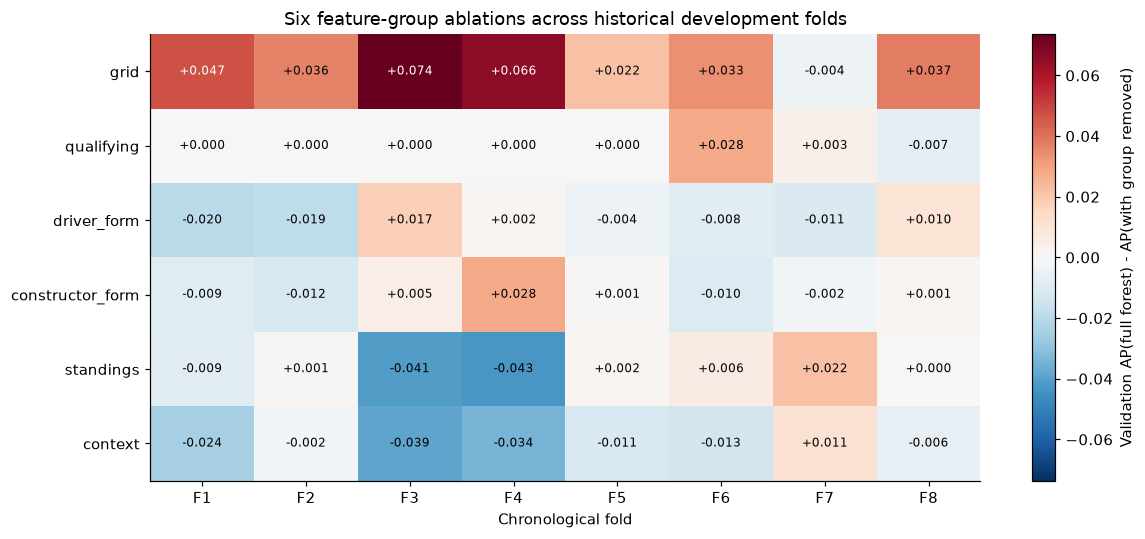

,mean_ap_drop,minimum,maximum,positive_folds,unchanged_inputs
removed_group,,,,,
grid,0.0389,-0.0039,0.0736,7,0
qualifying,0.0030,-0.0072,0.0278,2,5
driver_form,-0.0040,-0.0200,0.0174,3,0
constructor_form,0.0003,-0.0118,0.0281,4,0
standings,-0.0078,-0.0430,0.0218,5,0
context,-0.0148,-0.0385,0.0115,1,0


**Ablation interpretation.** Positive cells indicate useful conditional predictive information for this fixed forest; negative cells indicate better validation AP after removal. This is not a causal effect. Each fold uses the same rows, estimator parameters and threshold rule. Removing grid also removes its qualifying difference so the grid is not reconstructed from that interaction. All-missing/constant inputs had already been excluded using training data; unchanged early qualifying sets are transparently reused. This is sensitivity evidence across eras, not a new test-driven feature search. The prespecified core/extended candidate comparison is retained; a small gain from one group deletion is not assumed to generalize.

In [21]:
# Fixed full-candidate forest, same training/validation rows, six leave-one-group-out trials per fold.
ablation_rows=[]; ablation_fit_records=[]
for fold,parts in era_fold_frames.items():
    baseline=era_fitted[(fold,'qualifying_extended','random_forest')]
    base_columns=baseline['columns']; baseline_ap=baseline['validation_ap']; cache={tuple(base_columns):baseline['pipeline']}
    for removed,group_columns in FEATURE_GROUPS.items():
        excluded=set(group_columns)
        if removed=='grid': excluded.add('grid_qualifying_difference')
        columns=[c for c in base_columns if c not in excluded]
        key=tuple(columns);reused=key in cache
        if not reused:
            pipeline=era_make_pipeline(ERA_ESTIMATORS['random_forest'],columns)
            with era_thread_limits(limits=2):
                pipeline.fit(era_x(parts['train'],columns),parts['train'].podium.astype(int))
            cache[key]=pipeline
        pipeline=cache[key]
        p=pipeline.predict_proba(era_x(parts['validation'],columns))[:,1]
        threshold=best_f1_threshold(parts['validation'].podium,p)
        row=score_row('random_forest','validation',parts['validation'].podium,p,threshold)
        row.update({'fold':fold,'removed_group':removed,'baseline_ap':baseline_ap,
            'ap_drop':baseline_ap-row['pr_auc'],'removed_effective_columns':'|'.join(c for c in base_columns if c in excluded),
            'remaining_features':len(columns),'identical_to_baseline':columns==base_columns,
            'reused_identical_fit':reused})
        ablation_rows.append(row)
        ablation_fit_records.append({'fold':fold,'group':removed,'pipeline':pipeline,'columns':columns})
ablation_results=pd.DataFrame(ablation_rows)
ablation_results.to_csv(EVIDENCE_OUT/'feature_group_ablation.csv',index=False)
fig,ax=plt.subplots(figsize=(11,5))
matrix=ablation_results.pivot(index='removed_group',columns='fold',values='ap_drop').reindex(FEATURE_GROUPS)
bound=max(.01,float(np.abs(matrix.to_numpy()).max()))
im=ax.imshow(matrix.to_numpy(),aspect='auto',cmap='RdBu_r',vmin=-bound,vmax=bound)
ax.set_xticks(range(8),matrix.columns);ax.set_yticks(range(6),matrix.index)
for r in range(6):
    for c in range(8): ax.text(c,r,f'{matrix.iloc[r,c]:+.3f}',ha='center',va='center',fontsize=8,
        color='white' if abs(matrix.iloc[r,c])>.6*bound else 'black')
ax.set(title='Six feature-group ablations across historical development folds',xlabel='Chronological fold')
fig.colorbar(im,ax=ax,label='Validation AP(full forest) - AP(with group removed)')
fig.tight_layout();fig.savefig(EVIDENCE_OUT/'figures/04_group_ablation.png',dpi=150,bbox_inches='tight')
plt.show();plt.close(fig)
ablation_summary=ablation_results.groupby('removed_group',sort=False).agg(
    mean_ap_drop=('ap_drop','mean'),minimum=('ap_drop','min'),maximum=('ap_drop','max'),
    positive_folds=('ap_drop',lambda x:int(x.gt(0).sum())),unchanged_inputs=('identical_to_baseline','sum'))
display(ablation_summary.round(4))
display(Markdown('**Ablation interpretation.** Positive cells indicate useful conditional predictive information for '
    'this fixed forest; negative cells indicate better validation AP after removal. This is not a causal effect. '
    'Each fold uses the same rows, estimator parameters and threshold rule. Removing grid also removes its qualifying '
    'difference so the grid is not reconstructed from that interaction. All-missing/constant inputs had already been '
    'excluded using training data; unchanged early qualifying sets are transparently reused. '
    'This is sensitivity evidence across eras, not a new test-driven feature search. The prespecified core/extended '
    'candidate comparison is retained; a small gain from one group deletion is not assumed to generalize.'))


### 18.3 Two controlled preprocessing-order experiments

At F6 (training 1950-2002, validation 2003-2004) and F8 (training 1950-2019, validation 2020-2021),
compare imputation/standardization order and imputation/quantile-normalization order. Each pair keeps
the model, feature list, rows and threshold rule fixed. QuantileTransformer preserves missing values
until the imputer; every fitted statistic comes from training. Plot training distribution changes too.


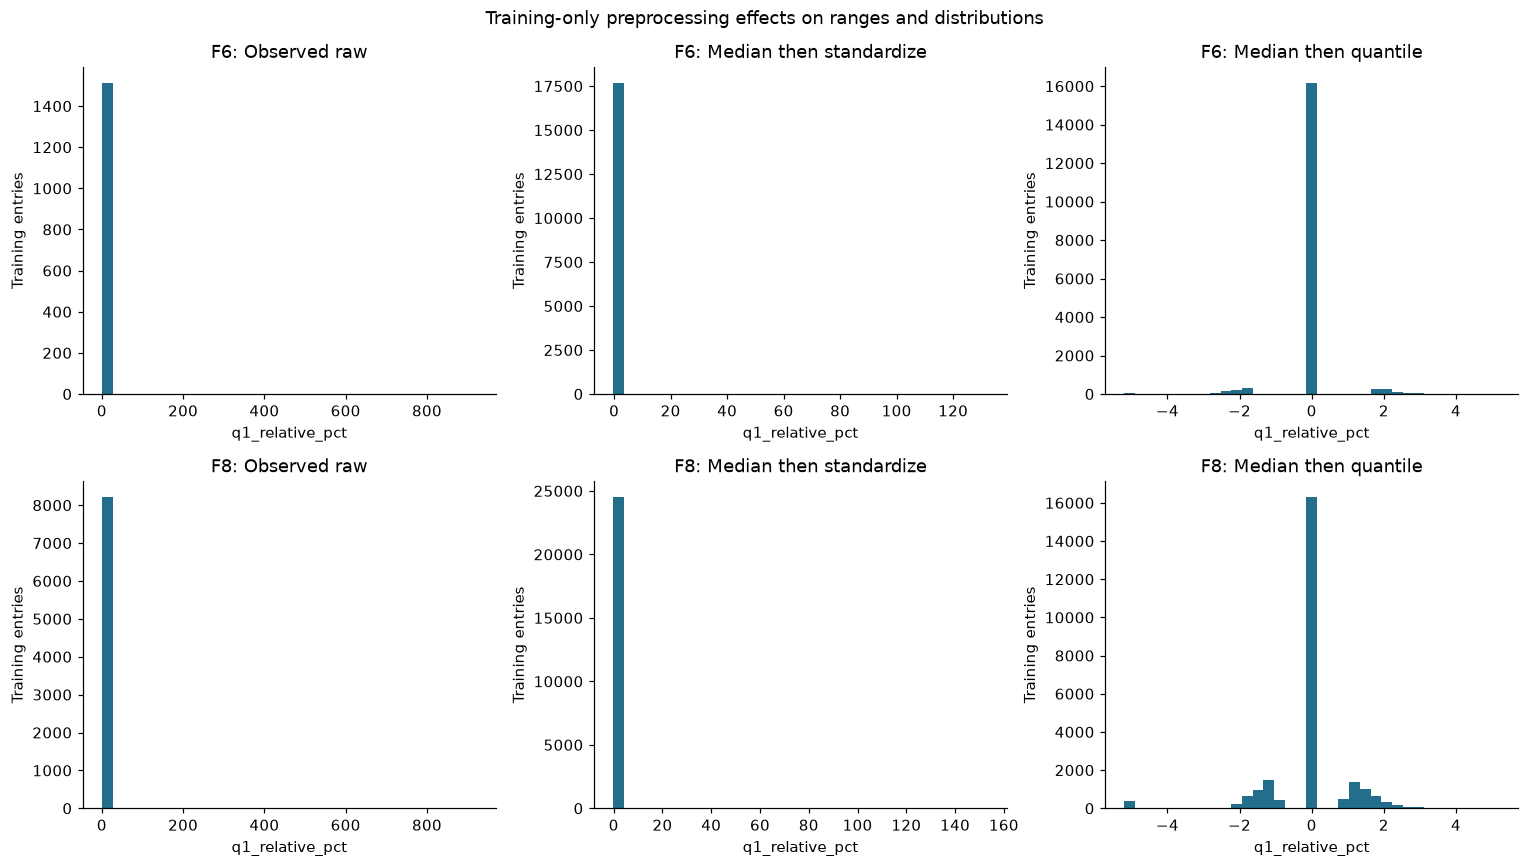

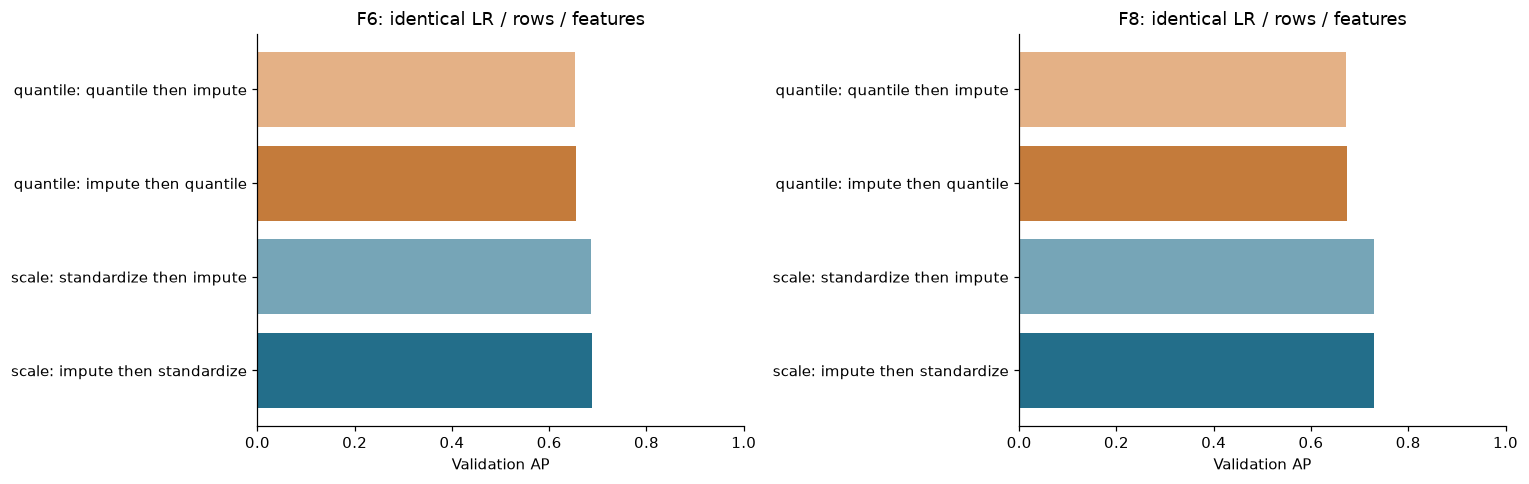

,fold,order,pr_auc,roc_auc,f1,precision,recall,threshold
0,F6,scale: impute then standardize,0.6870,0.9195,0.6635,0.6422,0.6863,0.350
1,F6,scale: standardize then impute,0.6858,0.9187,0.6578,0.6016,0.7255,0.305
2,F6,quantile: impute then quantile,0.6545,0.9074,0.6600,0.6735,0.6471,0.315
3,F6,quantile: quantile then impute,0.6537,0.9046,0.6438,0.5725,0.7353,0.225
4,F8,scale: impute then standardize,0.7300,0.9283,0.7054,0.6454,0.7778,0.270
5,F8,scale: standardize then impute,0.7290,0.9282,0.7054,0.6454,0.7778,0.270
6,F8,quantile: impute then quantile,0.6742,0.9085,0.7000,0.6829,0.7179,0.225
7,F8,quantile: quantile then impute,0.6722,0.9038,0.7000,0.6829,0.7179,0.215


**Order evidence.** F6 quantile: AP difference between the two orders = -0.0008. F6 scale: AP difference between the two orders = -0.0012. F8 quantile: AP difference between the two orders = -0.0020. F8 scale: AP difference between the two orders = -0.0010. Standardization before imputation estimates moments on observed values; imputation first includes the median-filled mass. Quantile fitting before imputation estimates the empirical distribution without that mass. All fitting uses training rows only; thresholds use the same validation F1 rule. The two pairs are independent order experiments, each repeated at two historical cutoffs. These limited trials do not establish a universal best transform, so the transparent prespecified median-then-standardize pipeline is retained for the main comparison. Quantile mapping compresses tails and changes distances; this can help or hurt generalization.

,raceId,driverId,year,q1_relative_pct,q1,q1_seconds
0,255,87,1995,922.861981,16:42.640,1002.64


**Timing-tail limitation.** The diagnostic flag (>50% slower than the stored session best) does not automatically label a record erroneous. F8 training contains one especially long stored value: `raceId=255`, `driverId=87`, 1995 Japanese GP, Q1 `16:42.640`, producing relative pace about 922.9%. It is syntactically parseable but unusual; its original meaning/correction has not been verified. Retain and flag it rather than invent a replacement. It dominates the standardized range and can affect extended-model fitting. The qualifying-free core and quantile-order trials provide sensitivity evidence; a future outlier-treatment trial should use development data only. No test-tail inspection changes the main pipeline.

In [22]:
from sklearn.preprocessing import QuantileTransformer

def historical_order_pipeline(columns,steps):
    numeric=[c for c in columns if c not in CATEGORICAL]
    categorical=[c for c in columns if c in CATEGORICAL]
    return Pipeline([('prepare',ColumnTransformer([
        ('numeric',Pipeline(steps),numeric),
        ('category',OneHotEncoder(handle_unknown='ignore',sparse_output=False),categorical)],sparse_threshold=0)),
        ('model',era_clone(ERA_ESTIMATORS['logistic_regression']))])

order_rows=[]; order_fit_records=[]; order_distribution_rows=[]
fig,axes=plt.subplots(2,3,figsize=(14,8))
for row,fold in enumerate(['F6','F8']):
    parts=era_fold_frames[fold];columns=era_fitted[(fold,'qualifying_extended','logistic_regression')]['columns']
    train_x=era_x(parts['train'],columns);validation_x=era_x(parts['validation'],columns)
    def quantile(): return QuantileTransformer(n_quantiles=min(500,len(train_x)),
        output_distribution='normal',random_state=903)
    variants={
        'scale: impute then standardize':[('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())],
        'scale: standardize then impute':[('scale',StandardScaler()),('impute',SimpleImputer(strategy='median'))],
        'quantile: impute then quantile':[('impute',SimpleImputer(strategy='median')),('quantile',quantile())],
        'quantile: quantile then impute':[('quantile',quantile()),('impute',SimpleImputer(strategy='median'))]}
    for name,steps in variants.items():
        fitted=historical_order_pipeline(columns,steps)
        with era_thread_limits(limits=2): fitted.fit(train_x,parts['train'].podium.astype(int))
        p=fitted.predict_proba(validation_x)[:,1]
        threshold=best_f1_threshold(parts['validation'].podium,p)
        metric=score_row('logistic_regression','validation',parts['validation'].podium,p,threshold)
        metric.update({'fold':fold,'experiment':name.split(':')[0],'order':name,'features':len(columns)})
        order_rows.append(metric);order_fit_records.append({'fold':fold,'order':name,'pipeline':fitted,'columns':columns})
    feature='q1_relative_pct';single=train_x[[feature]]
    transforms={
      'Observed raw':single[feature].dropna().to_numpy(),
      'Median then standardize':Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]).fit_transform(single).ravel(),
      'Median then quantile':Pipeline([('impute',SimpleImputer(strategy='median')),('quantile',quantile())]).fit_transform(single).ravel()}
    for ax,(name,values) in zip(axes[row],transforms.items()):
        ax.hist(values,bins=35,color='#236e8a');ax.set(title=f'{fold}: {name}',xlabel=feature,ylabel='Training entries')
        order_distribution_rows.append({'fold':fold,'stage':name,'rows':len(values),
            'missing':int(single[feature].isna().sum()) if name=='Observed raw' else 0,
            'minimum':values.min(),'maximum':values.max(),'mean':values.mean(),'std':values.std(),
            'median':np.median(values),'p05':np.quantile(values,.05),'p95':np.quantile(values,.95)})
fig.suptitle('Training-only preprocessing effects on ranges and distributions')
fig.tight_layout();fig.savefig(EVIDENCE_OUT/'figures/05_preprocessing_distributions.png',dpi=150,bbox_inches='tight')
plt.show();plt.close(fig)
order_results=pd.DataFrame(order_rows)
order_results.to_csv(EVIDENCE_OUT/'preprocessing_order_experiments.csv',index=False)
pd.DataFrame(order_distribution_rows).to_csv(EVIDENCE_OUT/'preprocessing_distribution.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
for ax,fold in zip(axes,['F6','F8']):
    view=order_results.loc[order_results.fold.eq(fold)]
    ax.barh(view['order'],view.pr_auc,color=['#236e8a','#76a5b7','#c47b3b','#e4b186'])
    ax.set(title=f'{fold}: identical LR / rows / features',xlabel='Validation AP',xlim=(0,1))
fig.tight_layout();fig.savefig(EVIDENCE_OUT/'figures/06_preprocessing_order_comparison.png',dpi=150,bbox_inches='tight')
plt.show();plt.close(fig)
display(order_results[['fold','order','pr_auc','roc_auc','f1','precision','recall','threshold']].round(4))
order_differences=[]
for (fold,experiment),view in order_results.groupby(['fold','experiment']):
    order_differences.append(f'{fold} {experiment}: AP difference between the two orders = '
        f'{view.iloc[1].pr_auc-view.iloc[0].pr_auc:+.4f}.')
display(Markdown('**Order evidence.** '+' '.join(order_differences)+
    ' Standardization before imputation estimates moments on observed values; imputation first includes the '
    'median-filled mass. Quantile fitting before imputation estimates the empirical distribution without that mass. '
    'All fitting uses training rows only; thresholds use the same validation F1 rule. The two pairs are independent '
    'order experiments, each repeated at two historical cutoffs. These limited trials do not establish a universal '
    'best transform, so the transparent prespecified median-then-standardize pipeline is retained for the main comparison. '
    'Quantile mapping compresses tails and changes distances; this can help or hurt generalization.'))

# Audit extreme stored durations on F8 training only; no unverified source correction is invented.
timing_tail_audit=era_fold_frames['F8']['train'].loc[
    era_fold_frames['F8']['train']['q1_relative_pct'].gt(50),
    ['raceId','driverId','year','q1_relative_pct']].merge(
    clean['qualifying'][['raceId','driverId','q1','q1_seconds']],on=['raceId','driverId'],validate='one_to_one')
timing_tail_audit.to_csv(EVIDENCE_OUT/'training_timing_tail_audit.csv',index=False)
display(timing_tail_audit)
display(Markdown('**Timing-tail limitation.** The diagnostic flag (>50% slower than the stored session best) '
    'does not automatically label a record erroneous. F8 training contains one especially long stored value: '
    '`raceId=255`, `driverId=87`, 1995 Japanese GP, Q1 `16:42.640`, producing relative pace about 922.9%. '
    'It is syntactically parseable but unusual; its original meaning/correction has not been verified. '
    'Retain and flag it rather than invent a replacement. It dominates the standardized range and can affect '
    'extended-model fitting. The qualifying-free core and quantile-order trials provide sensitivity evidence; '
    'a future outlier-treatment trial should use development data only. No test-tail inspection changes the main pipeline.'))


## 19. Historical test results and prevalence-aware comparisons

Show five metrics for every candidate and era. AP depends on positive prevalence, so report the podium
rate and AP/prevalence alongside it. Pooled scores combine out-of-fold probabilities from different fits;
their calibration and thresholds can differ. Per-fold metrics are the primary record. Macro fold AP and
pooled AP are different summaries and are not interchangeable. No claim of causal era effects is made.


In [23]:
# All development experiments above are complete; main fits/variants/thresholds stay frozen.
for era_fold in ERA_FOLDS:
    fold_name=era_fold['fold'];parts=era_fold_frames[fold_name]
    candidates=era_candidates[fold_name];selected=era_selected[fold_name]
    test_frame=parts['test']; test_y=test_frame['podium'].astype(int)
    for candidate in candidates:
        probability=candidate['pipeline'].predict_proba(era_x(test_frame,candidate['columns']))[:,1]
        metric=score_row(candidate['model'],'test',test_y,probability,candidate['threshold'])
        metric.update({'fold':fold_name,'feature_set':candidate['feature_set'],
                       'effective_features':len(candidate['columns'])});era_metric_rows.append(metric)
        out=test_frame[['raceId','driverId','date','year','reporting_era','podium']].copy()
        out['fold']=fold_name;out['feature_set']=candidate['feature_set'];out['model']=candidate['model']
        out['probability']=probability;out['threshold']=candidate['threshold']
        out['prediction']=probability>=candidate['threshold']
        out['validation_selected']=(candidate['feature_set']==selected['feature_set'] and candidate['model']==selected['model'])
        era_prediction_frames.append(out)

era_metrics=pd.DataFrame(era_metric_rows)
era_predictions=pd.concat(era_prediction_frames,ignore_index=True)
era_metrics.to_csv(ERA_OUT/'metrics_by_fold.csv',index=False)
era_predictions.to_csv(ERA_OUT/'test_predictions.csv',index=False)
assert not era_predictions.duplicated(['fold','feature_set','model','raceId','driverId']).any()
display(era_metrics.loc[era_metrics['split'].eq('test')].round(4))


,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate,fold,feature_set,effective_features
112,logistic_regression,test,0.8350,0.4606,0.4236,0.3613,0.5119,0.180,596,0.1409,F1,historical_core,16
113,random_forest,test,0.8384,0.4544,0.4545,0.3676,0.5952,0.235,596,0.1409,F1,historical_core,16
114,shallow_nn,test,0.6938,0.3082,0.3417,0.2957,0.4048,0.260,596,0.1409,F1,historical_core,16
115,logistic_regression,test,0.8350,0.4606,0.4236,0.3613,0.5119,0.180,596,0.1409,F1,qualifying_extended,16
116,random_forest,test,0.8384,0.4544,0.4545,0.3676,0.5952,0.235,596,0.1409,F1,qualifying_extended,16
117,shallow_nn,test,0.6938,0.3082,0.3417,0.2957,0.4048,0.260,596,0.1409,F1,qualifying_extended,16
118,logistic_regression,test,0.8362,0.4131,0.4694,0.4107,0.5476,0.280,596,0.1409,F1,grid_only,2
119,logistic_regression,test,0.8385,0.4259,0.2866,0.5393,0.1951,0.430,1668,0.1475,F2,historical_core,19
120,random_forest,test,0.8310,0.4480,0.4817,0.3611,0.7236,0.215,1668,0.1475,F2,historical_core,19
121,shallow_nn,test,0.7432,0.2832,0.1238,0.3115,0.0772,0.050,1668,0.1475,F2,historical_core,19


,feature_set,model,reporting_era,rows,races,tested_years,podium_rate,roc_auc,pooled_ap,macro_fold_ap,ap_over_prevalence,f1,precision,recall
0,grid_only,logistic_regression,1950-1979,5513,230,1957-1979,0.1252,0.8619,0.4116,0.4048,3.2887,0.4814,0.3744,0.6739
1,grid_only,logistic_regression,1980-2002,7949,308,1982-2002,0.1162,0.8981,0.4897,0.4655,4.2125,0.5479,0.4383,0.7305
2,grid_only,logistic_regression,2003-2013,3664,166,2005-2013,0.1359,0.8983,0.5874,0.5874,4.3218,0.6104,0.6104,0.6104
3,grid_only,logistic_regression,2014-2021,2482,122,2016-2021,0.1475,0.9239,0.6779,0.6779,4.5970,0.6964,0.6099,0.8115
4,grid_only,logistic_regression,2022-2024,1359,68,2022-2024,0.1501,0.9138,0.6473,0.6473,4.3122,0.6486,0.6502,0.6471
5,historical_core,logistic_regression,1950-1979,5513,230,1957-1979,0.1252,0.8664,0.4338,0.4422,3.4663,0.4416,0.4315,0.4522
6,historical_core,logistic_regression,1980-2002,7949,308,1982-2002,0.1162,0.9092,0.5145,0.5014,4.4263,0.5499,0.4996,0.6115
7,historical_core,logistic_regression,2003-2013,3664,166,2005-2013,0.1359,0.9069,0.5951,0.5951,4.3783,0.6128,0.5398,0.7088
8,historical_core,logistic_regression,2014-2021,2482,122,2016-2021,0.1475,0.9343,0.6943,0.6943,4.7083,0.7016,0.6330,0.7869
9,historical_core,logistic_regression,2022-2024,1359,68,2022-2024,0.1501,0.9325,0.6823,0.6823,4.5451,0.6569,0.5730,0.7696


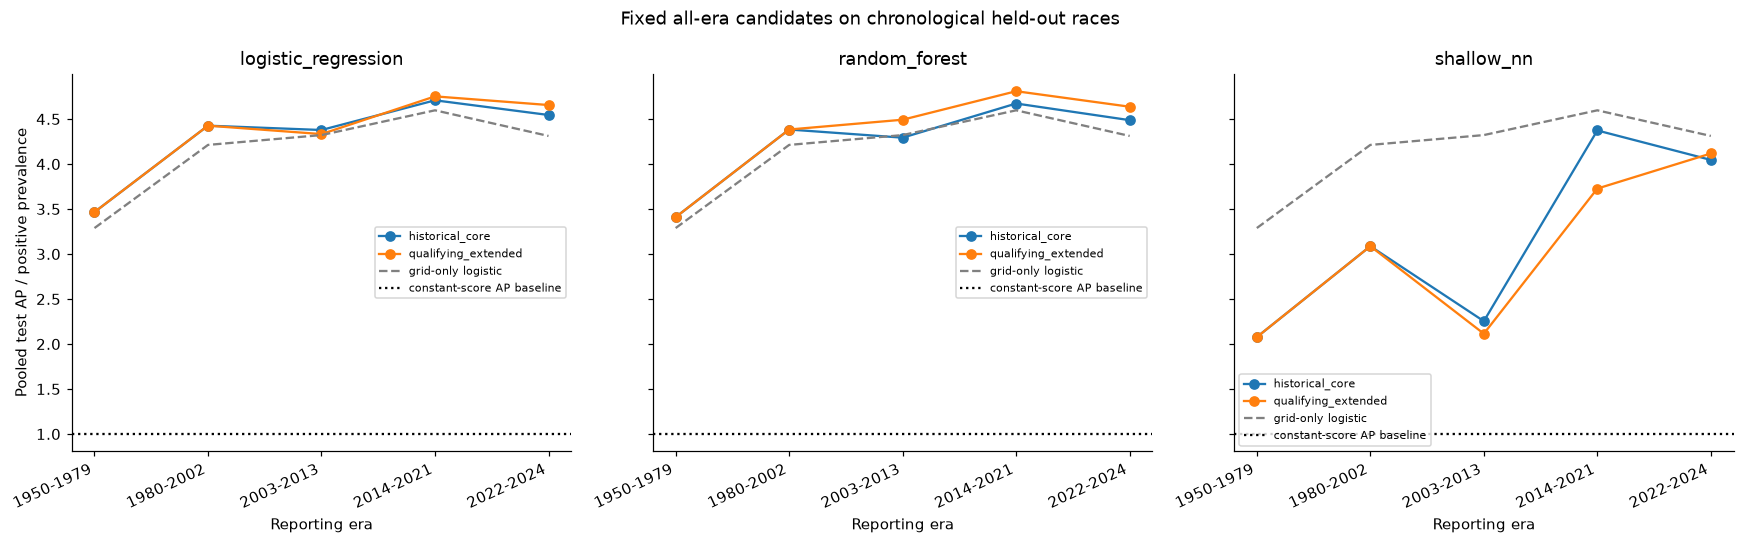

,fold,feature_set,model,validation_ap,validation_f1,threshold,test_start,test_end
0,F1,historical_core,random_forest,0.4025,0.5179,0.235,1957,1959
1,F2,historical_core,logistic_regression,0.4505,0.4944,0.430,1962,1969
2,F3,historical_core,logistic_regression,0.4164,0.5248,0.165,1972,1979
3,F4,historical_core,logistic_regression,0.5032,0.5505,0.260,1982,1989
4,F5,historical_core,logistic_regression,0.5476,0.6038,0.350,1992,2002
5,F6,historical_core,logistic_regression,0.6873,0.6549,0.300,2005,2013
6,F7,qualifying_extended,logistic_regression,0.7288,0.7132,0.275,2016,2021
7,F8,qualifying_extended,logistic_regression,0.7300,0.7054,0.270,2022,2024


In [24]:
era_result_rows=[]
for (variant,name,period),group in era_predictions.groupby(['feature_set','model','reporting_era'],observed=True):
    target=group['podium'].to_numpy(dtype=int); prediction=group['prediction'].to_numpy(dtype=bool)
    prevalence=float(target.mean()); ap=average_precision_score(target,group['probability'])
    fold_aps=[average_precision_score(g['podium'],g['probability']) for _,g in group.groupby('fold')]
    era_result_rows.append({'feature_set':variant,'model':name,'reporting_era':str(period),
        'rows':len(group),'races':group['raceId'].nunique(),'tested_years':f'{group.year.min()}-{group.year.max()}',
        'podium_rate':prevalence,'roc_auc':roc_auc_score(target,group['probability']),'pooled_ap':ap,
        'macro_fold_ap':float(np.mean(fold_aps)),'ap_over_prevalence':ap/prevalence,
        'f1':f1_score(target,prediction,zero_division=0),
        'precision':precision_score(target,prediction,zero_division=0),
        'recall':recall_score(target,prediction,zero_division=0)})
era_results=pd.DataFrame(era_result_rows)
era_results.to_csv(ERA_OUT/'metrics_by_era.csv',index=False)
display(era_results.round(4))
fig,axes=plt.subplots(1,3,figsize=(16,5),sharey=True)
for ax,name in zip(axes,ERA_ESTIMATORS):
    for variant in ERA_FEATURE_SETS:
        part=era_results.loc[era_results['model'].eq(name)&era_results['feature_set'].eq(variant)].set_index('reporting_era').reindex(ERA_LABELS)
        ax.plot(np.arange(len(ERA_LABELS)),part['ap_over_prevalence'],marker='o',label=variant)
    base=era_results.loc[era_results['feature_set'].eq('grid_only')].set_index('reporting_era').reindex(ERA_LABELS)
    ax.plot(np.arange(len(ERA_LABELS)),base['ap_over_prevalence'],linestyle='--',color='gray',label='grid-only logistic')
    ax.axhline(1,color='black',linestyle=':',label='constant-score AP baseline')
    ax.set_title(name);ax.set_xticks(np.arange(len(ERA_LABELS)),ERA_LABELS,rotation=25,ha='right')
    ax.set_xlabel('Reporting era');ax.legend(fontsize=7)
axes[0].set_ylabel('Pooled test AP / positive prevalence')
fig.suptitle('Fixed all-era candidates on chronological held-out races')
fig.tight_layout();fig.savefig(ERA_OUT/'figures/02_performance_by_era.png',dpi=150,bbox_inches='tight')
plt.show();plt.close(fig)
era_policy_predictions=era_predictions.loc[era_predictions['validation_selected']].copy()
assert not era_policy_predictions.duplicated(['raceId','driverId']).any()
assert era_policy_predictions['raceId'].nunique()==len(era_previously_tested)
era_policy_predictions.to_csv(ERA_OUT/'validation_selected_test_predictions.csv',index=False)
display(era_choices.round(4))


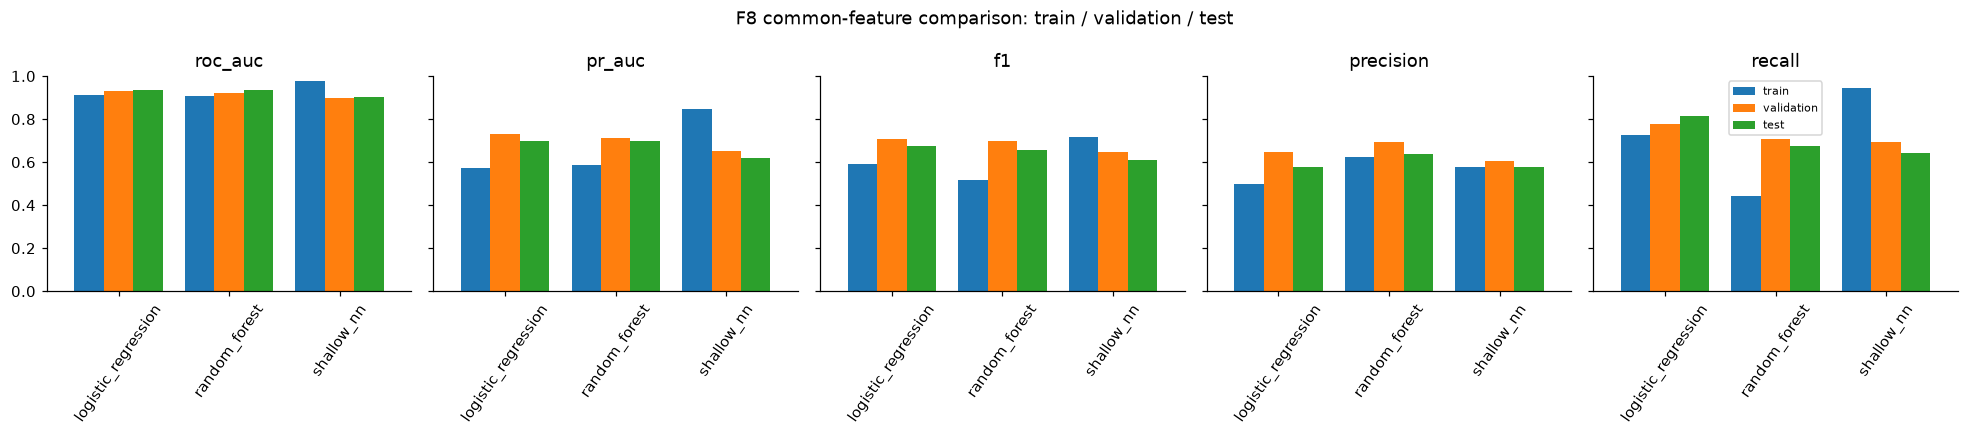

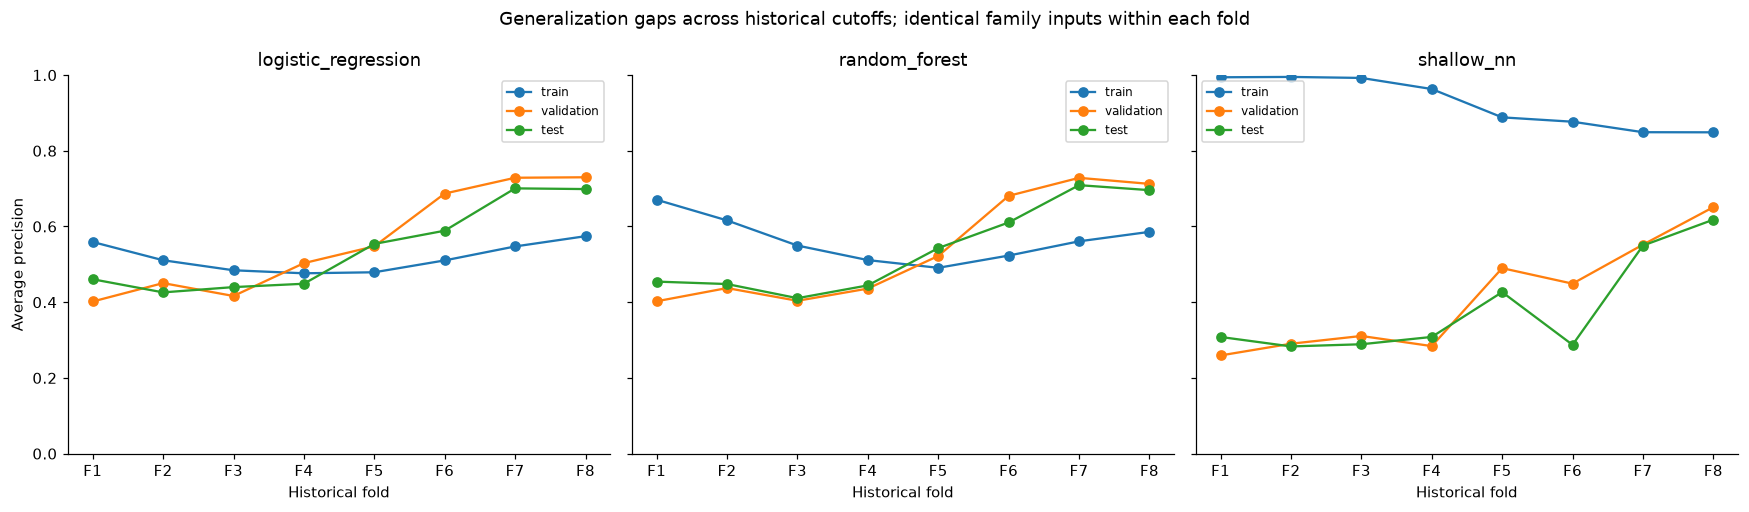

**Metric choice.** Average precision (AP) is the primary ranking measure because podiums are the minority class. Here PR-AUC means recall-increment-weighted average precision, not trapezoidal integration. ROC-AUC is also reported; F1 is secondary at a validation-fixed threshold, with precision and recall exposing the error trade-off. Training scores describe fit and can reveal overfitting. Accuracy is not a selection metric. Fold-wise metrics are primary for each fitted model. Pooled cross-fold AP mixes scores from differently fitted, uncalibrated models; the macro-fold AP in the era table is complementary. Prior inspection makes this a retrospective comparison rather than a newly untouched prospective benchmark.

In [25]:
# Every family on the same extended effective features. All five required metrics are in metrics_by_fold.csv.
fig,axes=plt.subplots(1,5,figsize=(18,4),sharey=True)
for ax,metric in zip(axes,['roc_auc','pr_auc','f1','precision','recall']):
    view=era_metrics.loc[era_metrics.fold.eq('F8')&era_metrics.feature_set.eq('qualifying_extended')]
    table=view.pivot(index='model',columns='split',values=metric).reindex(ERA_ESTIMATORS)
    table[['train','validation','test']].plot.bar(ax=ax,rot=55,legend=metric=='recall',width=.8)
    ax.set(title=metric,ylim=(0,1),xlabel='')
    if ax.get_legend(): ax.legend(fontsize=7)
fig.suptitle('F8 common-feature comparison: train / validation / test')
fig.tight_layout();fig.savefig(ERA_OUT/'figures/04_five_metrics.png',dpi=150,bbox_inches='tight')
plt.show();plt.close(fig)
fig,axes=plt.subplots(1,3,figsize=(16,4.7),sharey=True)
for ax,name in zip(axes,ERA_ESTIMATORS):
    view=era_metrics.loc[era_metrics.model.eq(name)&era_metrics.feature_set.eq('qualifying_extended')]
    for split in ['train','validation','test']:
        part=view.loc[view['split'].eq(split)]
        ax.plot(part.fold,part.pr_auc,marker='o',label=split)
    ax.set(title=name,xlabel='Historical fold',ylim=(0,1));ax.legend(fontsize=8)
axes[0].set_ylabel('Average precision')
fig.suptitle('Generalization gaps across historical cutoffs; identical family inputs within each fold')
fig.tight_layout();fig.savefig(ERA_OUT/'figures/05_train_validation_test_ap.png',dpi=150,bbox_inches='tight')
plt.show();plt.close(fig)
display(Markdown('**Metric choice.** Average precision (AP) is the primary ranking measure because podiums are the '
    'minority class. Here PR-AUC means recall-increment-weighted average precision, not trapezoidal integration. '
    'ROC-AUC is also reported; F1 is secondary at a validation-fixed threshold, with precision and recall exposing '
    'the error trade-off. Training scores describe fit and can reveal overfitting. Accuracy is not a selection metric. '
    'Fold-wise metrics are primary for each fitted model. Pooled cross-fold AP mixes scores from differently fitted, '
    'uncalibrated models; the macro-fold AP in the era table is complementary. Prior inspection makes this a '
    'retrospective comparison rather than a newly untouched prospective benchmark.'))


## 20. Uncertainty and historical label sensitivity

For the validation-selected policy, resample **whole test races** within each reporting era. These
conditional intervals hold fitted models and validation decisions fixed; they do not include uncertainty
from refitting or temporal/driver dependence. Era-level pooled probabilities can have different calibration
across folds. Overlapping intervals do not prove equivalent performance.

Historical duplicate decisions can change the target. Re-score the selected policy against the alternative
any-car podium label as a sensitivity check, **without refitting**. This is not an alternate trained solution
and does not establish which historical label is correct.


,reporting_era,rows,races,tested_years,podium_rate,roc_auc,pooled_ap,ap_lower95,ap_upper95,grid_only_ap,ap_minus_grid_only,f1,precision,recall,valid_bootstraps
0,1950-1979,5513,230,1957-1979,0.1252,0.8636,0.4286,0.3954,0.4632,0.4116,0.0170,0.4462,0.4311,0.4623,300
1,1980-2002,7949,308,1982-2002,0.1162,0.9092,0.5145,0.4848,0.5528,0.4897,0.0249,0.5499,0.4996,0.6115,300
2,2003-2013,3664,166,2005-2013,0.1359,0.9069,0.5951,0.5563,0.6360,0.5874,0.0077,0.6128,0.5398,0.7088,300
3,2014-2021,2482,122,2016-2021,0.1475,0.9366,0.7007,0.6453,0.7537,0.6779,0.0228,0.6984,0.5969,0.8415,300
4,2022-2024,1359,68,2022-2024,0.1501,0.9349,0.6989,0.6444,0.7546,0.6473,0.0516,0.6762,0.5784,0.8137,300


,reporting_era,changed_labels,retained_entry_ap,alternative_label_ap,retained_entry_f1,alternative_label_f1
0,1950-1979,1,0.4286,0.4293,0.4462,0.4472
1,1980-2002,0,0.5145,0.5145,0.5499,0.5499
2,2003-2013,0,0.5951,0.5951,0.6128,0.6128
3,2014-2021,0,0.7007,0.7007,0.6984,0.6984
4,2022-2024,0,0.6989,0.6989,0.6762,0.6762


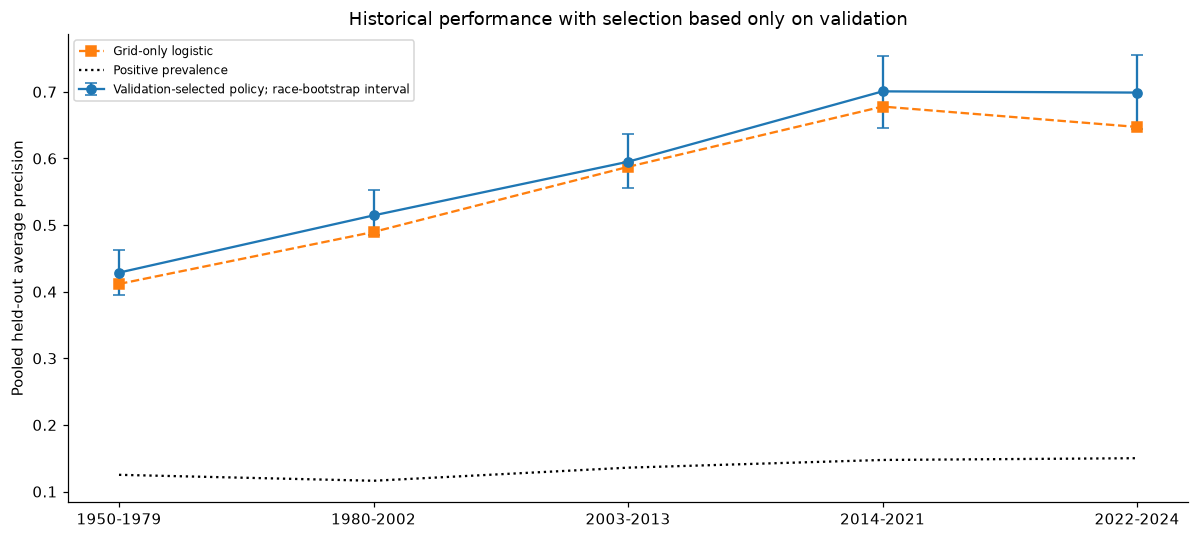

In [26]:
era_policy_rows=[];era_bootstrap_rows=[];era_label_rows=[]
era_rng=np.random.default_rng(903)
era_any_car=results.assign(alternative_podium=results['positionOrder'].le(3)).groupby(['raceId','driverId'])['alternative_podium'].max()
for period,group in era_policy_predictions.groupby('reporting_era',observed=True):
    group=group.reset_index(drop=True)
    target=group['podium'].to_numpy(dtype=int);probability=group['probability'].to_numpy()
    prediction=group['prediction'].to_numpy(dtype=bool)
    ids=group['raceId'].to_numpy();unique=np.unique(ids)
    positions={race:np.flatnonzero(ids==race) for race in unique}
    sampled_aps=[]
    for replicate in range(300):
        selected_races=era_rng.choice(unique,size=len(unique),replace=True)
        idx=np.concatenate([positions[race] for race in selected_races])
        if np.unique(target[idx]).size<2:continue
        value=average_precision_score(target[idx],probability[idx]);sampled_aps.append(value)
        era_bootstrap_rows.append({'reporting_era':str(period),'replicate':replicate,'pooled_ap':value})
    lower,upper=np.quantile(sampled_aps,[.025,.975])
    observed=average_precision_score(target,probability)
    grid_base=era_predictions.loc[era_predictions['feature_set'].eq('grid_only')&era_predictions['reporting_era'].eq(period)]
    base_ap=average_precision_score(grid_base['podium'],grid_base['probability'])
    era_policy_rows.append({'reporting_era':str(period),'rows':len(group),'races':len(unique),
        'tested_years':f'{group.year.min()}-{group.year.max()}','podium_rate':float(target.mean()),
        'roc_auc':roc_auc_score(target,probability),'pooled_ap':observed,'ap_lower95':lower,'ap_upper95':upper,
        'grid_only_ap':base_ap,'ap_minus_grid_only':observed-base_ap,
        'f1':f1_score(target,prediction,zero_division=0),'precision':precision_score(target,prediction,zero_division=0),
        'recall':recall_score(target,prediction,zero_division=0),'valid_bootstraps':len(sampled_aps)})
    alternative=era_any_car.reindex(pd.MultiIndex.from_frame(group[['raceId','driverId']])).to_numpy(dtype=int)
    era_label_rows.append({'reporting_era':str(period),'changed_labels':int(np.sum(target!=alternative)),
        'retained_entry_ap':observed,'alternative_label_ap':average_precision_score(alternative,probability),
        'retained_entry_f1':f1_score(target,prediction,zero_division=0),
        'alternative_label_f1':f1_score(alternative,prediction,zero_division=0)})
era_policy_results=pd.DataFrame(era_policy_rows)
era_policy_results.to_csv(ERA_OUT/'validation_selected_metrics_by_era.csv',index=False)
pd.DataFrame(era_bootstrap_rows).to_csv(ERA_OUT/'policy_race_bootstrap.csv',index=False)
era_label_sensitivity=pd.DataFrame(era_label_rows)
era_label_sensitivity.to_csv(ERA_OUT/'historical_label_sensitivity.csv',index=False)
display(era_policy_results.round(4));display(era_label_sensitivity.round(4))
fig,ax=plt.subplots(figsize=(11,5))
positions=np.arange(len(era_policy_results))
ax.errorbar(positions,era_policy_results['pooled_ap'],yerr=[era_policy_results['pooled_ap']-era_policy_results['ap_lower95'],
    era_policy_results['ap_upper95']-era_policy_results['pooled_ap']],marker='o',capsize=4,label='Validation-selected policy; race-bootstrap interval')
ax.plot(positions,era_policy_results['grid_only_ap'],marker='s',linestyle='--',label='Grid-only logistic')
ax.plot(positions,era_policy_results['podium_rate'],linestyle=':',color='black',label='Positive prevalence')
ax.set_xticks(positions,era_policy_results['reporting_era']);ax.set_ylabel('Pooled held-out average precision')
ax.set_title('Historical performance with selection based only on validation');ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(ERA_OUT/'figures/03_selected_policy_uncertainty.png',dpi=150,bbox_inches='tight')
plt.show();plt.close(fig)


## 21. Historical inference and experiment integrity checks

The helper below looks up the assembled pre-race features for a historical driver-race entry, then uses
the most recent backtest model whose training **and threshold-validation** periods ended before that race.
It never reads that entry's podium label. It refuses years before an initial model is available. This
demonstrates the chronological model sequence, rather than claiming a single model fitted on all 75 years
can make independently evaluated predictions about its own training races.


In [27]:
def predict_historical_entry(race_id, driver_id):
    row=era_table.loc[era_table['raceId'].eq(race_id)&era_table['driverId'].eq(driver_id)]
    if len(row)!=1:raise ValueError('Expected one known historical driver-race entry.')
    year=int(row.iloc[0]['year'])
    eligible=[fold for fold in ERA_FOLDS if fold['validation_end']<year]
    if not eligible:raise ValueError('No independently fitted initial model is available for this early year.')
    fold=max(eligible,key=lambda f:f['validation_end'])
    candidate=era_selected[fold['fold']]
    probability=float(candidate['pipeline'].predict_proba(era_x(row,candidate['columns']))[0,1])
    return {'raceId':int(race_id),'driverId':int(driver_id),'year':year,'fold':fold['fold'],
        'feature_set':candidate['feature_set'],'model':candidate['model'],'podium_probability':probability,
        'threshold':candidate['threshold'],'predicted_podium':bool(probability>=candidate['threshold'])}

era_inference=[]
for period,group in era_policy_predictions.groupby('reporting_era',observed=True):
    example=group.sort_values(['date','raceId','driverId']).iloc[0]
    scored=predict_historical_entry(int(example.raceId),int(example.driverId))
    assert scored['fold']==example['fold'] and np.isclose(scored['podium_probability'],example['probability'])
    era_inference.append({'reporting_era':str(period),**scored})
pd.DataFrame(era_inference).to_csv(ERA_OUT/'historical_inference_examples.csv',index=False)
display(pd.DataFrame(era_inference).round(4))

# Independent direct filters verify historical form where the original modern-only checks cannot.
era_integrity=[]
def era_checked(name,condition):
    assert bool(condition),name
    era_integrity.append({'check':name,'passed':True})
era_history=entries.merge(clean['races'][['raceId','date','round']],on='raceId',validate='many_to_one')
era_team_events=era_history.assign(past_podium=era_history['positionOrder'].le(3)).groupby(
    ['constructorId','raceId','date','round'],as_index=False)['past_podium'].mean()
for sampled_row in era_table.iloc[np.unique(np.linspace(0,len(era_table)-1,50,dtype=int))].itertuples():
    d=era_history.loc[era_history['driverId'].eq(sampled_row.driverId)&era_history['date'].lt(sampled_row.date)&
        era_history['date'].ge(sampled_row.date-pd.Timedelta(days=365))].sort_values(['date','round','raceId']).tail(5)
    t=era_team_events.loc[era_team_events['constructorId'].eq(sampled_row.constructorId)&era_team_events['date'].lt(sampled_row.date)&
        era_team_events['date'].ge(sampled_row.date-pd.Timedelta(days=365))].sort_values(['date','round','raceId']).tail(5)
    expected_driver=float(d['positionOrder'].le(3).mean()) if len(d) else np.nan
    expected_team=float(t['past_podium'].mean()) if len(t) else np.nan
    actual_driver=float(sampled_row.driver_podium_rate_5) if pd.notna(sampled_row.driver_podium_rate_5) else np.nan
    actual_team=float(sampled_row.constructor_podium_rate_5) if pd.notna(sampled_row.constructor_podium_rate_5) else np.nan
    era_checked(f'Direct historical form {sampled_row.raceId}/{sampled_row.driverId}',
        np.isclose(actual_driver,expected_driver,equal_nan=True) and np.isclose(actual_team,expected_team,equal_nan=True)
        and sampled_row.driver_history_count_5==len(d) and sampled_row.constructor_history_count_5==len(t))
era_checked('One partition per race in every fold',era_assignments.groupby(['fold','raceId'])['partition'].nunique().eq(1).all())
era_checked('No repeated race in test windows',not era_assignments.loc[era_assignments['partition'].eq('test')].duplicated('raceId').any())
era_checked('No repeated selected-policy driver-race predictions',not era_policy_predictions.duplicated(['raceId','driverId']).any())
era_checked('Raw inputs unchanged',{t:sha256(DATA_DIR/f'{t}.csv') for t in TABLES}==hashes_before)
era_checked('Every reporting era has test predictions',set(era_policy_predictions['reporting_era'].astype(str))==set(ERA_LABELS))
for fold_name,selected in era_selected.items():
    eligible=era_metrics.loc[era_metrics['fold'].eq(fold_name)&era_metrics['split'].eq('validation')&era_metrics['feature_set'].ne('grid_only')]
    era_checked(f'{fold_name} selection uses validation AP',np.isclose(selected['validation_ap'],eligible['pr_auc'].max()))
    parts=era_fold_frames[fold_name]
    era_checked(f'{fold_name} training before validation before test',parts['train']['date'].max()<parts['validation']['date'].min()<parts['test']['date'].min()
                and parts['validation']['date'].max()<parts['test']['date'].min())
    for variant in ERA_FEATURE_SETS:
        columns=[tuple(era_fitted[(fold_name,variant,name)]['columns']) for name in ERA_ESTIMATORS]
        era_checked(f'{fold_name}/{variant} identical model feature sets',len(set(columns))==1)
    # Exact equality is expected when historical qualifying adds no train-supported features.
    for name in ERA_ESTIMATORS:
        a=era_fitted[(fold_name,'historical_core',name)];b=era_fitted[(fold_name,'qualifying_extended',name)]
        if a['columns']==b['columns']:
            era_checked(f'{fold_name}/{name} equivalent variants reuse one fit',a['pipeline'] is b['pipeline'])
pd.DataFrame(era_integrity).to_csv(ERA_OUT/'integrity_checks.csv',index=False)
era_summary={'candidate_entries':len(era_table),'candidate_races':era_table.raceId.nunique(),
    'test_entries':len(era_policy_predictions),'test_races':era_policy_predictions.raceId.nunique(),
    'first_test_year':int(era_policy_predictions.year.min()),'last_test_year':int(era_policy_predictions.year.max()),
    'folds':len(ERA_FOLDS),'reporting_eras':ERA_LABELS,'integrity_checks_passed':len(era_integrity),
    'actual_unique_fits':int((~era_fits['reused_equivalent_fit']).sum()),
    'fit_warning_count':int(era_fits['fit_warnings'].ne('').sum()),
    'model_selection_uses_test':False,'original_submission_modified':False,
    'limitations':['Initial warm-up and validation years are not independently tested.',
        'Historical labels inherit the documented retained-entry convention.',
        'Fold reuse, temporal dependence and pooled probability calibration limit uncertainty interpretations.',
        'Configurations are fixed; this is not an exhaustive architecture search.',
        'The modern 2022-2024 test outcomes had been inspected before this experiment was designed.']}
(ERA_OUT/'experiment_summary.json').write_text(json.dumps(era_summary,indent=2,default=int))
print(f'All-era integrity checks passed: {len(era_integrity)}')


,reporting_era,raceId,driverId,year,fold,feature_set,model,podium_probability,threshold,predicted_podium
0,1950-1979,776,347,1957,F1,historical_core,random_forest,0.0620,0.235,False
1,1980-2002,467,95,1982,F4,historical_core,logistic_regression,0.0202,0.260,False
2,2003-2013,71,2,2005,F6,historical_core,logistic_regression,0.1768,0.300,False
3,2014-2021,948,1,2016,F7,qualifying_extended,logistic_regression,0.5619,0.275,True
4,2022-2024,1074,1,2022,F8,qualifying_extended,logistic_regression,0.3727,0.270,True


All-era integrity checks passed: 102


## 22. Historical results and interpretation

The results evaluate one historical modeling procedure retrained and selected at successive cutoffs.
Per-era evidence matters; a pooled score does not establish equal reliability across all years.
Shared-drive conventions, coverage drift and different entry populations remain limitations.
Equivalent variants reuse fits. NN training-loss stopping does not establish a global optimum.
The following explanation and record-inference sections complete the analytical workflow.


In [28]:
era_text=[]
for row in era_policy_results.itertuples():
    era_text.append(f"- **{row.reporting_era}** (tested {row.tested_years}; {row.races} races): "
        f"AP **{row.pooled_ap:.3f}**, ROC-AUC {row.roc_auc:.3f}, F1 {row.f1:.3f}, "
        f"precision {row.precision:.3f}, recall {row.recall:.3f}. "
        f"Grid-only AP {row.grid_only_ap:.3f}; difference {row.ap_minus_grid_only:+.3f}; "
        f"positive prevalence {row.podium_rate:.3f}.")
display(Markdown('**Validation-selected policy on held-out historical races**\n\n'+'\n'.join(era_text)))
display(Markdown(
    f"The expanded table retains **{len(era_table):,}** entries. The test windows evaluate "
    f"**{len(era_policy_predictions):,}** entries in **{era_policy_predictions.raceId.nunique():,}** races "
    f"from **{era_policy_predictions.year.min()} to {era_policy_predictions.year.max()}**, across all five reporting eras. "
    "Warm-up/validation years are not additional independent tests. Compare the feature-set candidates in "
    "`metrics_by_era.csv`; absent historical qualifying means extended features cannot automatically add information. "
    "The table above compares the validation-selection procedure with a simple grid-only baseline. "
    "It does not choose a new global winner from test results or establish uniform reliability in every season."))
print('Experimental outputs:',ERA_OUT)


**Validation-selected policy on held-out historical races**

- **1950-1979** (tested 1957-1979; 230 races): AP **0.429**, ROC-AUC 0.864, F1 0.446, precision 0.431, recall 0.462. Grid-only AP 0.412; difference +0.017; positive prevalence 0.125.
- **1980-2002** (tested 1982-2002; 308 races): AP **0.515**, ROC-AUC 0.909, F1 0.550, precision 0.500, recall 0.611. Grid-only AP 0.490; difference +0.025; positive prevalence 0.116.
- **2003-2013** (tested 2005-2013; 166 races): AP **0.595**, ROC-AUC 0.907, F1 0.613, precision 0.540, recall 0.709. Grid-only AP 0.587; difference +0.008; positive prevalence 0.136.
- **2014-2021** (tested 2016-2021; 122 races): AP **0.701**, ROC-AUC 0.937, F1 0.698, precision 0.597, recall 0.842. Grid-only AP 0.678; difference +0.023; positive prevalence 0.147.
- **2022-2024** (tested 2022-2024; 68 races): AP **0.699**, ROC-AUC 0.935, F1 0.676, precision 0.578, recall 0.814. Grid-only AP 0.647; difference +0.052; positive prevalence 0.150.

The expanded table retains **26,668** entries. The test windows evaluate **20,967** entries in **894** races from **1957 to 2024**, across all five reporting eras. Warm-up/validation years are not additional independent tests. Compare the feature-set candidates in `metrics_by_era.csv`; absent historical qualifying means extended features cannot automatically add information. The table above compares the validation-selection procedure with a simple grid-only baseline. It does not choose a new global winner from test results or establish uniform reliability in every season.

Experimental outputs: C:\Users\alimf\Documents\ChatGPT\ACL Project\tmp\historical_completion\final_check_20261019T162847Z\experiments\all_era\artifacts\all_era


## 23. Global and local explanations of historical fitted models

Explain the extended logistic candidate in each historical fold; this consistent family is a transparent
baseline and need not be the fold's selected winner. Use validation AP for permutation importance,
training backgrounds for SHAP, and validation rows for explanations. The local F8 case is selected by
distance to its fixed threshold, without using its outcome. Include both local SHAP and LIME because
the deliverables allow either while the checklist also names LIME. All explanations are noncausal.


C:\Users\alimf\Documents\ChatGPT\ACL Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


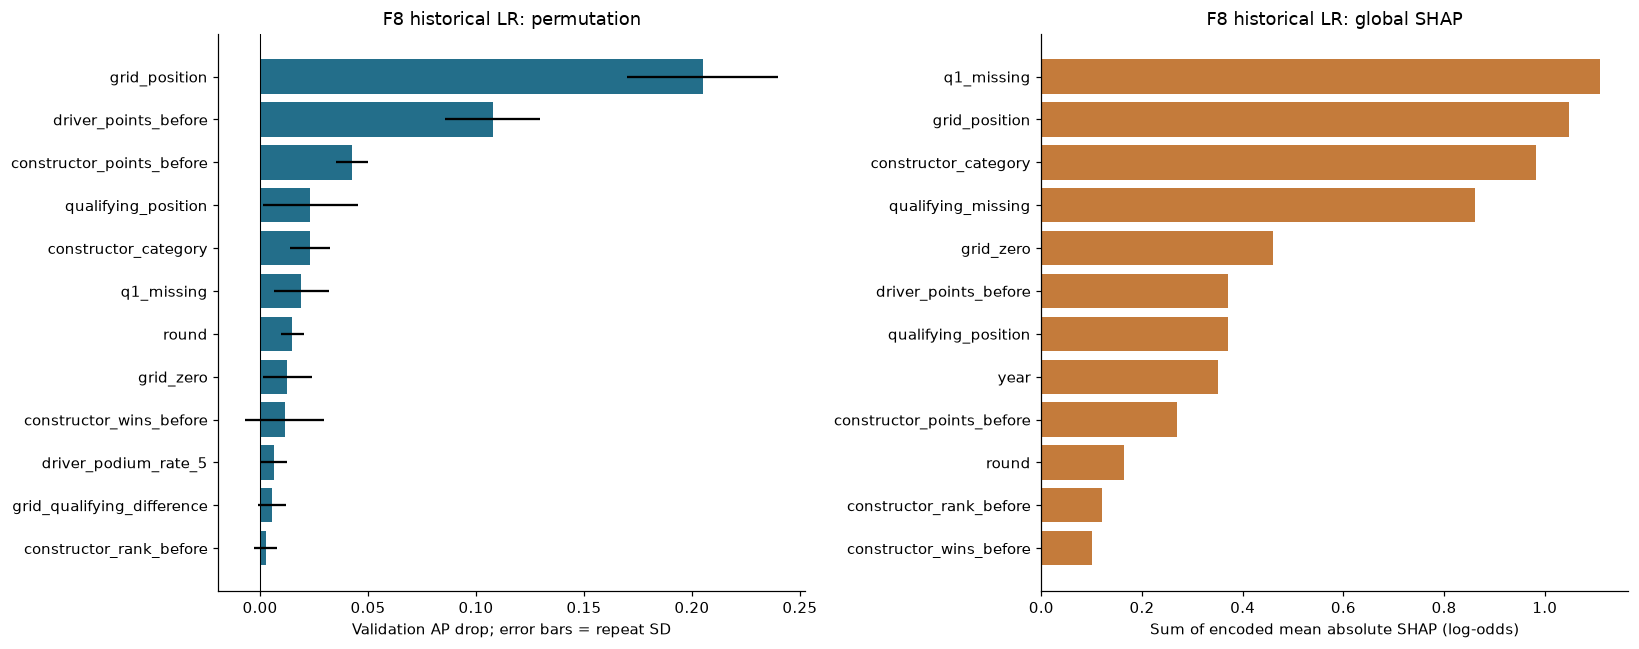

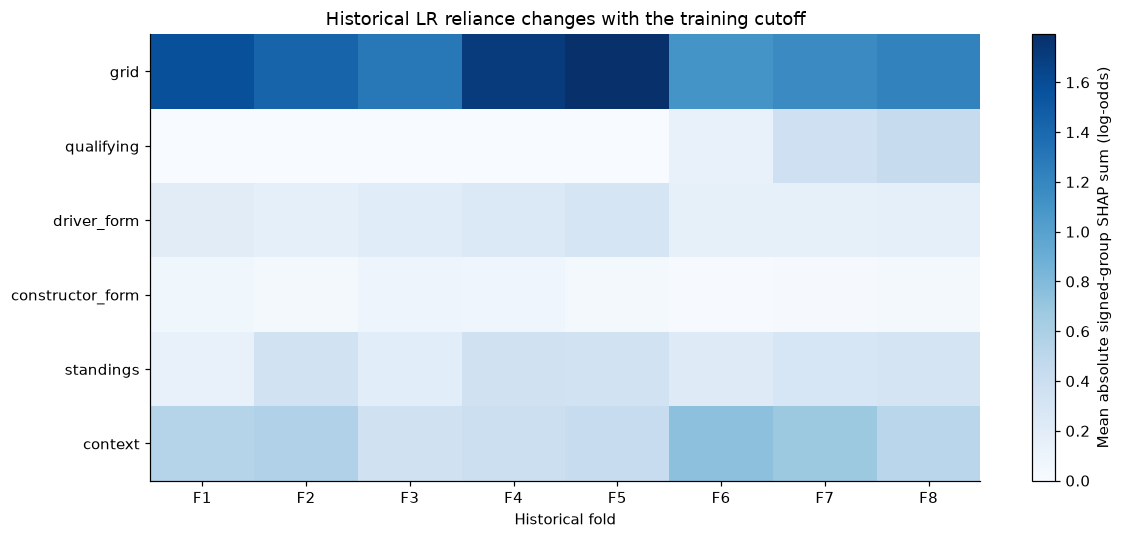

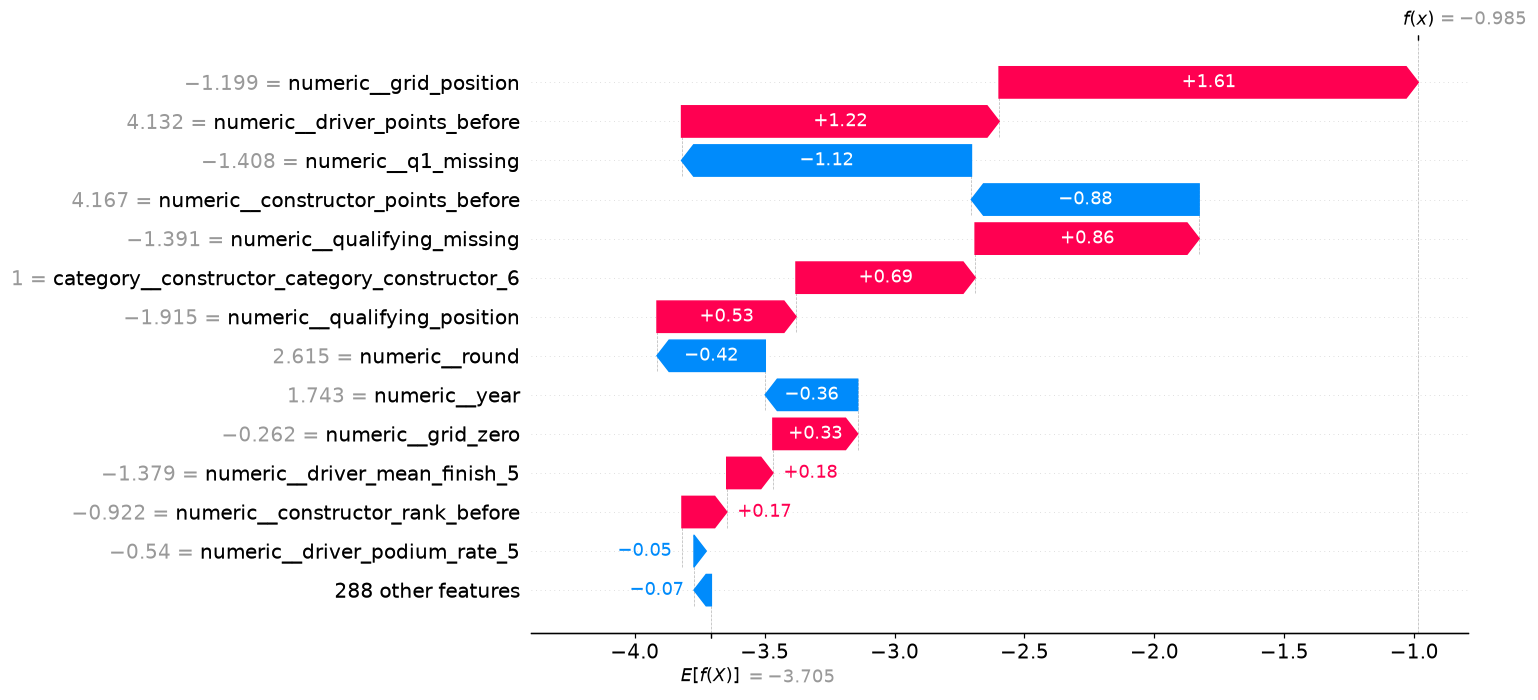

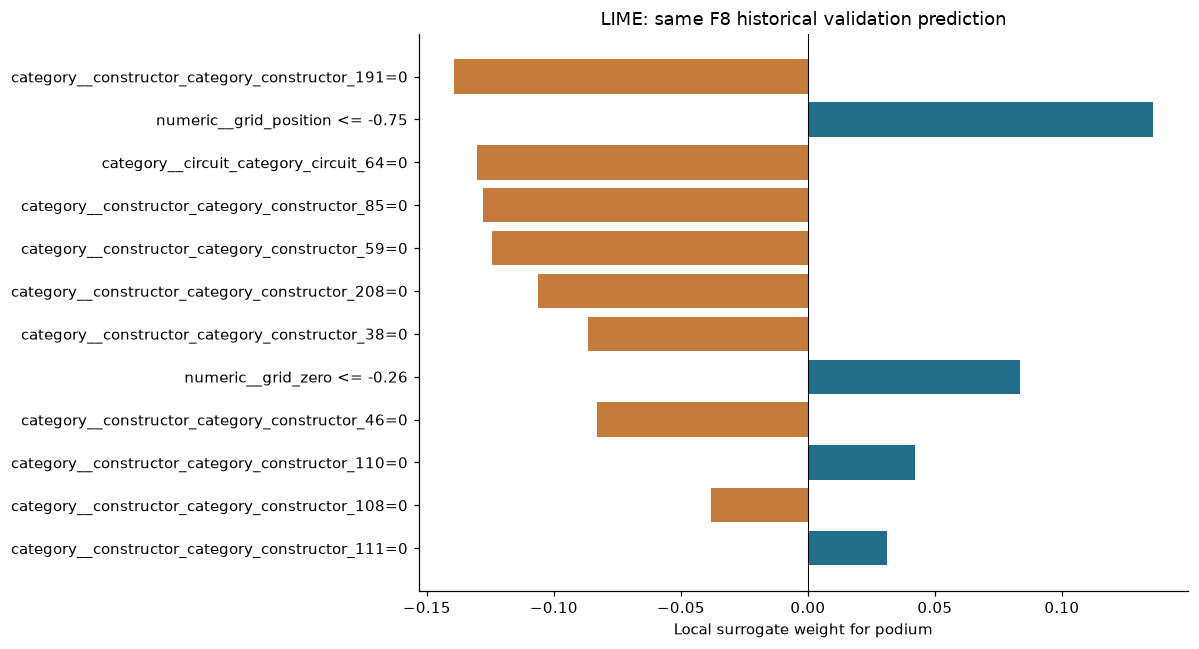

,fold,model,feature_set,training_background_rows,validation_explained_rows,max_log_odds_additivity_error,selected_policy_model,explains_selected_policy_exactly
0,F1,logistic_regression,qualifying_extended,250,200,1.776357e-15,random_forest,False
1,F2,logistic_regression,qualifying_extended,250,200,1.776357e-15,logistic_regression,True
2,F3,logistic_regression,qualifying_extended,250,200,2.664535e-15,logistic_regression,True
3,F4,logistic_regression,qualifying_extended,250,200,1.776357e-15,logistic_regression,True
4,F5,logistic_regression,qualifying_extended,250,200,1.776357e-15,logistic_regression,True
5,F6,logistic_regression,qualifying_extended,250,200,2.220446e-15,logistic_regression,False
6,F7,logistic_regression,qualifying_extended,250,200,1.776357e-15,logistic_regression,True
7,F8,logistic_regression,qualifying_extended,250,200,2.664535e-15,logistic_regression,True


{'raceId': 1072,
 'driverId': 844,
 'date': Timestamp('2021-12-05 00:00:00'),
 'podium': 0,
 'fold': 'F8',
 'model': 'logistic_regression',
 'feature_set': 'qualifying_extended',
 'predicted_probability': 0.27197477064196646,
 'threshold': 0.26999999999999996,
 'log_odds': -0.9846263963065587,
 'shap_base_log_odds': -3.705216194863096,
 'shap_sum': 2.7205897985565373,
 'selection_rule': 'First closest probability to validation-fixed threshold; labels not used to select case.',
 'lime_weighted_r_squared': 0.4065267248432365,
 'lime_surrogate_probability': 0.17067191180268848,
 'lime_absolute_probability_error': 0.10130285883927798}

**Explanation scope and interpretation.** These are the eight actual historical extended logistic fits (with training-unsupported columns removed), not explanations of the NN, forest, or entire model-selection procedure. F8 has training through 2019 and validation in 2020-2021. Its largest permutation drops are grid_position (+0.205 AP), driver_points_before (+0.108 AP), constructor_points_before (+0.042 AP); its largest signed-group SHAP magnitudes are grid, context, qualifying. Permutation evaluates marginal reliance and can break correlated feature relationships. Independent-background linear SHAP allocates additive log-odds contributions under a simplified dependence assumption. The local probability is 0.272; SHAP exactly reconciles its log-odds. LIME has weighted R-squared 0.407 and absolute local probability error 0.101; it is an approximation. Its independently perturbed encoded columns can represent impossible one-hot or derived-feature combinations. Neither explanation establishes causation, calibrated probabilities, or an actionable intervention.

In [29]:
import importlib.util
import subprocess
# Kaggle normally supplies SHAP; only install an absent explanation dependency.
missing_xai=[package for package in ['shap','lime'] if importlib.util.find_spec(package) is None]
if missing_xai:
    subprocess.check_call([sys.executable,'-m','pip','install',*missing_xai])
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.inspection import permutation_importance

XAI_OUT=ERA_OUT/'explanations'
(XAI_OUT/'figures').mkdir(parents=True,exist_ok=True)
permutation_rows=[];shap_rows=[];shap_group_rows=[];xai_checks=[];xai_objects={}
for fold,parts in era_fold_frames.items():
    # Explain an actual fitted historical LR, consistently across folds, not a transferred modern model.
    candidate=era_fitted[(fold,'qualifying_extended','logistic_regression')]
    pipeline=candidate['pipeline'];columns=candidate['columns']
    train_x=era_x(parts['train'],columns);valid_x=era_x(parts['validation'],columns)
    with era_thread_limits(limits=2):
        importance=permutation_importance(pipeline,valid_x,parts['validation'].podium.astype(int),
            scoring='average_precision',n_repeats=8,random_state=903,n_jobs=1)
    permutation_rows.extend({'fold':fold,'feature':c,'mean_ap_drop':importance.importances_mean[i],
        'repeat_std':importance.importances_std[i]}
        for i,c in enumerate(columns))
    prepare=pipeline.named_steps['prepare'];model=pipeline.named_steps['model']
    names=list(prepare.get_feature_names_out())
    encoded_train=np.asarray(prepare.transform(train_x),dtype=float)
    encoded_valid=np.asarray(prepare.transform(valid_x),dtype=float)
    rng=np.random.default_rng(903)
    background_positions=np.sort(rng.choice(len(train_x),min(250,len(train_x)),replace=False))
    explain_positions=np.sort(rng.choice(len(valid_x),min(200,len(valid_x)),replace=False))
    masker=shap.maskers.Independent(encoded_train[background_positions],max_samples=250)
    explainer=shap.LinearExplainer(model,masker,feature_names=names)
    values=explainer(encoded_valid[explain_positions])
    reconstructed=np.asarray(values.base_values)+values.values.sum(axis=1)
    expected=model.decision_function(encoded_valid[explain_positions])
    error=float(np.max(np.abs(reconstructed-expected)))
    assert error<1e-7
    xai_checks.append({'fold':fold,'model':'logistic_regression','feature_set':'qualifying_extended',
        'training_background_rows':len(background_positions),'validation_explained_rows':len(explain_positions),
        'max_log_odds_additivity_error':error,'selected_policy_model':era_selected[fold]['model'],
        'explains_selected_policy_exactly':era_selected[fold]['pipeline'] is pipeline})
    original_names=[name.split('__',1)[1] for name in names]
    mapped=[next((c for c in columns if c in CATEGORICAL and name.startswith(c+'_')),name)
            for name in original_names]
    shap_rows.extend({'fold':fold,'encoded_feature':name,'original_feature':original,
        'mean_absolute_log_odds_shap':float(np.abs(values.values[:,i]).mean())}
        for i,(name,original) in enumerate(zip(names,mapped)))
    for group,group_columns in FEATURE_GROUPS.items():
        indices=[i for i,c in enumerate(mapped) if c in group_columns]
        # Sum signed encoded contributions for a group first, then take mean absolute magnitude.
        contribution=values.values[:,indices].sum(axis=1) if indices else np.zeros(len(explain_positions))
        shap_group_rows.append({'fold':fold,'group':group,'mean_absolute_group_log_odds_shap':float(np.abs(contribution).mean())})
    xai_objects[fold]={'candidate':candidate,'train':encoded_train,'validation':encoded_valid,'names':names,
        'explainer':explainer,'values':values,'explained_positions':explain_positions}
permutation_results=pd.DataFrame(permutation_rows)
shap_global=pd.DataFrame(shap_rows);shap_groups=pd.DataFrame(shap_group_rows)
permutation_results.to_csv(XAI_OUT/'permutation_importance.csv',index=False)
shap_global.to_csv(XAI_OUT/'shap_global.csv',index=False)
shap_groups.to_csv(XAI_OUT/'shap_groups.csv',index=False)
pd.DataFrame(xai_checks).to_csv(XAI_OUT/'scope_and_additivity_checks.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(15,6))
view=permutation_results.loc[permutation_results.fold.eq('F8')].nlargest(12,'mean_ap_drop').sort_values('mean_ap_drop')
axes[0].barh(view.feature,view.mean_ap_drop,xerr=view.repeat_std,color='#236e8a')
axes[0].axvline(0,color='black',linewidth=.7);axes[0].set(title='F8 historical LR: permutation',xlabel='Validation AP drop; error bars = repeat SD')
view=shap_global.loc[shap_global.fold.eq('F8')].groupby('original_feature').mean_absolute_log_odds_shap.sum().nlargest(12).sort_values()
axes[1].barh(view.index,view.values,color='#c47b3b')
axes[1].set(title='F8 historical LR: global SHAP',xlabel='Sum of encoded mean absolute SHAP (log-odds)')
fig.tight_layout();fig.savefig(XAI_OUT/'figures/01_global_permutation_and_shap.png',dpi=150,bbox_inches='tight')
plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(11,5))
matrix=shap_groups.pivot(index='group',columns='fold',values='mean_absolute_group_log_odds_shap').reindex(FEATURE_GROUPS)
im=ax.imshow(matrix.to_numpy(),aspect='auto',cmap='Blues')
ax.set_xticks(range(8),matrix.columns);ax.set_yticks(range(6),matrix.index)
ax.set(title='Historical LR reliance changes with the training cutoff',xlabel='Historical fold')
fig.colorbar(im,ax=ax,label='Mean absolute signed-group SHAP sum (log-odds)')
fig.tight_layout();fig.savefig(XAI_OUT/'figures/02_shap_groups_by_fold.png',dpi=150,bbox_inches='tight')
plt.show();plt.close(fig)

lead=xai_objects['F8'];candidate=lead['candidate'];model=candidate['pipeline'].named_steps['model']
probabilities=model.predict_proba(lead['validation'])[:,1]
local_position=int(np.argmin(np.abs(probabilities-candidate['threshold'])))
local_values=lead['explainer'](lead['validation'][[local_position]])[0]
local_log_odds=float(model.decision_function(lead['validation'][[local_position]])[0])
assert np.isclose(float(local_values.base_values+local_values.values.sum()),local_log_odds,atol=1e-7)
local_metadata=era_fold_frames['F8']['validation'].iloc[local_position][['raceId','driverId','date','podium']].to_dict()
local_metadata.update({'fold':'F8','model':'logistic_regression','feature_set':'qualifying_extended',
    'predicted_probability':float(probabilities[local_position]),'threshold':candidate['threshold'],
    'log_odds':local_log_odds,'shap_base_log_odds':float(local_values.base_values),
    'shap_sum':float(local_values.values.sum()),'selection_rule':'First closest probability to validation-fixed threshold; labels not used to select case.'})
shap.plots.waterfall(local_values,max_display=14,show=False)
plt.gcf().set_size_inches(11,7)
plt.gcf().savefig(XAI_OUT/'figures/03_local_shap_waterfall.png',dpi=150,bbox_inches='tight')
plt.show();plt.close('all')
pd.DataFrame({'encoded_feature':lead['names'],'shap_log_odds':local_values.values,
              'transformed_value':lead['validation'][local_position]}).to_csv(XAI_OUT/'local_shap_values.csv',index=False)

numeric_count=sum(c not in CATEGORICAL for c in candidate['columns'])
lime_background=lead['train'][np.linspace(0,len(lead['train'])-1,min(3000,len(lead['train'])),dtype=int)]
lime_explainer=LimeTabularExplainer(lime_background,mode='classification',
    feature_names=lead['names'],class_names=['not podium','podium'],
    categorical_features=list(range(numeric_count,len(lead['names']))),random_state=903)
with era_thread_limits(limits=2):
    lime_case=lime_explainer.explain_instance(lead['validation'][local_position],model.predict_proba,
        labels=(1,),num_features=12,num_samples=4000)
lime_results=pd.DataFrame(lime_case.as_list(label=1),columns=['condition','local_weight'])
lime_results.to_csv(XAI_OUT/'lime_local.csv',index=False)
local_metadata.update({'lime_weighted_r_squared':float(lime_case.score),
    'lime_surrogate_probability':float(np.asarray(lime_case.local_pred).ravel()[0]),
    'lime_absolute_probability_error':float(abs(np.asarray(lime_case.local_pred).ravel()[0]-probabilities[local_position]))})
(XAI_OUT/'local_explanation_case.json').write_text(json.dumps(local_metadata,indent=2,default=str))
fig,ax=plt.subplots(figsize=(11,6))
view=lime_results.iloc[::-1]
ax.barh(view.condition,view.local_weight,color=['#236e8a' if v>=0 else '#c47b3b' for v in view.local_weight])
ax.axvline(0,color='black',linewidth=.7)
ax.set(title='LIME: same F8 historical validation prediction',xlabel='Local surrogate weight for podium')
fig.tight_layout();fig.savefig(XAI_OUT/'figures/04_local_lime.png',dpi=150,bbox_inches='tight')
plt.show();plt.close(fig)
display(pd.DataFrame(xai_checks));display(local_metadata)
top_permutation=permutation_results.loc[permutation_results.fold.eq('F8')].nlargest(3,'mean_ap_drop')
top_shap=shap_groups.loc[shap_groups.fold.eq('F8')].nlargest(3,'mean_absolute_group_log_odds_shap')
display(Markdown('**Explanation scope and interpretation.** These are the eight actual historical extended logistic '
    'fits (with training-unsupported columns removed), not explanations of the NN, forest, or entire model-selection '
    'procedure. F8 has training through 2019 and validation in 2020-2021. Its largest permutation drops are '+
    ', '.join(f'{r.feature} ({r.mean_ap_drop:+.3f} AP)' for r in top_permutation.itertuples())+
    '; its largest signed-group SHAP magnitudes are '+', '.join(top_shap.group)+'. '
    'Permutation evaluates marginal reliance and can break correlated feature relationships. Independent-background '
    'linear SHAP allocates additive log-odds contributions under a simplified dependence assumption. '
    f'The local probability is {local_metadata["predicted_probability"]:.3f}; SHAP exactly reconciles its log-odds. '
    f'LIME has weighted R-squared {local_metadata["lime_weighted_r_squared"]:.3f} and absolute local probability error '
    f'{local_metadata["lime_absolute_probability_error"]:.3f}; it is an approximation. '
    'Its independently perturbed encoded columns can represent impossible one-hot or derived-feature combinations. '
    'Neither explanation establishes causation, calibrated probabilities, or an actionable intervention.'))


## 24. Inference from complete and partially missing feature records

The earlier ID lookup demonstrates sequential historical use. This additional function accepts an
explicit dictionary of pre-race engineered features. It applies the selected historical pipeline, frozen
threshold, consistent derived flags, input validation and training-fitted missing-value handling.


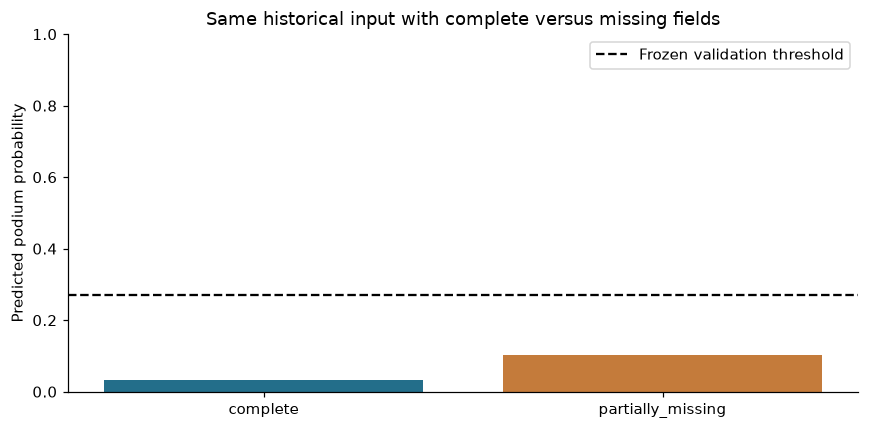

,example,fold,model,feature_set,podium_probability,predicted_podium,threshold,missing_feature_count,missing_features,outside_evaluated_year_range
0,complete,F8,logistic_regression,qualifying_extended,0.032009,0,0.27,0,[],False
1,partially_missing,F8,logistic_regression,qualifying_extended,0.102095,0,0.27,3,"[q1_relative_pct, driver_podium_rate_5, constr...",False


**Inference contract.** Supply the documented engineered pre-race fields; historical rates and standings must already have been computed from strictly earlier races. This helper does not recover arbitrary raw inputs or verify their timestamps. Missing fields use the fitted training imputer, unknown categories the fitted encoder. It recomputes derived differences and missingness flags, rejects unknown feature names and invalid positions, and prevents use on years preceding threshold validation. A later year outside the evaluated range is explicitly flagged. The default F8 model is the model selected on 2020-2021 validation, not a test-chosen winner or a refit on all years. The full/partial probability difference is model sensitivity, not evidence that missing data improves real podium chances. Binary decisions are per entry; they do not enforce exactly three predicted podiums per race.

245

In [30]:
def prepare_podium_record(record):
    """Canonicalize one engineered pre-race record; this does not build histories from raw results."""
    if not isinstance(record,dict): raise TypeError('Provide one feature dictionary.')
    unknown=set(record)-set(FEATURE_COLUMNS)
    if unknown: raise ValueError(f'Unknown features: {sorted(unknown)}')
    out={c:record.get(c,np.nan) for c in FEATURE_COLUMNS}
    for c in NUMERIC:
        if pd.isna(out[c]): out[c]=np.nan
        else:
            out[c]=float(out[c])
            if not np.isfinite(out[c]): raise ValueError(f'{c} must be finite or missing.')
    if pd.notna(out['grid_position']):
        if out['grid_position']<0: raise ValueError('Grid position cannot be negative.')
        if out['grid_position']==0: out['grid_position']=np.nan;out['grid_zero']=1.
        else: out['grid_zero']=0.
    elif pd.isna(out['grid_zero']): out['grid_zero']=0.
    if out['grid_zero'] not in [0.,1.]: raise ValueError('grid_zero must be zero or one.')
    if out['grid_zero']==1: out['grid_position']=np.nan
    if pd.notna(out['qualifying_position']) and out['qualifying_position']<=0:
        raise ValueError('Recorded qualifying position must be positive.')
    out['qualifying_missing']=float(pd.isna(out['qualifying_position']))
    out['q1_missing']=float(pd.isna(out['q1_relative_pct']))
    out['grid_qualifying_difference']=out['grid_position']-out['qualifying_position']
    missing_features=[c for c,v in out.items() if pd.isna(v)]
    for c in CATEGORICAL:
        out[c]='__UNKNOWN__' if pd.isna(out[c]) else str(out[c])
    return out,missing_features

def predict_podium_record(record,fold='F8'):
    """Predict with the validation-selected historical fit; only fitted preprocessing is applied."""
    if fold not in era_selected: raise ValueError(f'Choose a historical fold: {list(era_selected)}')
    normalized,missing=prepare_podium_record(record)
    protocol=next(f for f in ERA_FOLDS if f['fold']==fold)
    year=normalized['year']
    if pd.isna(year) or year<=protocol['validation_end']:
        raise ValueError('Record year must follow the model and threshold-validation periods.')
    candidate=era_selected[fold]
    x=pd.DataFrame([normalized])
    probability=float(candidate['pipeline'].predict_proba(era_x(x,candidate['columns']))[0,1])
    return {'fold':fold,'model':candidate['model'],'feature_set':candidate['feature_set'],
        'podium_probability':probability,'predicted_podium':int(probability>=candidate['threshold']),
        'threshold':candidate['threshold'],'missing_feature_count':len(missing),'missing_features':missing,
        'outside_evaluated_year_range':bool(year>protocol['test_end'])}

# Deterministic complete test-period input; no outcome is inspected to choose the example.
complete_candidates=era_fold_frames['F8']['test'].dropna(subset=FEATURE_COLUMNS)
assert len(complete_candidates)>0
complete_record=complete_candidates.iloc[0][FEATURE_COLUMNS].to_dict()
partial_record={k:v for k,v in complete_record.items()
    if k not in ['q1_relative_pct','driver_podium_rate_5','constructor_podium_rate_5']}
record_examples=[dict(example='complete',**predict_podium_record(complete_record)),
                 dict(example='partially_missing',**predict_podium_record(partial_record))]
record_inference=pd.DataFrame(record_examples)
record_inference.to_csv(ERA_OUT/'record_inference_examples.csv',index=False)
(ERA_OUT/'record_inference_inputs.json').write_text(json.dumps(
    {'complete':complete_record,'partially_missing':partial_record},indent=2,default=lambda x:float(x)))
canonical_partial,_=prepare_podium_record(partial_record)
assert canonical_partial['q1_missing']==1 and canonical_partial['qualifying_missing']==0
assert record_examples[0]['missing_feature_count']==0 and record_examples[1]['missing_feature_count']==3
same_x=era_x(complete_candidates.iloc[[0]],era_selected['F8']['columns'])
assert np.isclose(record_examples[0]['podium_probability'],era_selected['F8']['pipeline'].predict_proba(same_x)[0,1])
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(record_inference.example,record_inference.podium_probability,color=['#236e8a','#c47b3b'])
ax.axhline(era_selected['F8']['threshold'],linestyle='--',color='black',label='Frozen validation threshold')
ax.set(title='Same historical input with complete versus missing fields',ylabel='Predicted podium probability',ylim=(0,1))
ax.legend();fig.tight_layout();fig.savefig(ERA_OUT/'figures/06_record_inference.png',dpi=150,bbox_inches='tight')
plt.show();plt.close(fig)
display(record_inference)
display(Markdown('**Inference contract.** Supply the documented engineered pre-race fields; historical rates and standings '
    'must already have been computed from strictly earlier races. This helper does not recover arbitrary raw inputs or '
    'verify their timestamps. Missing fields use the fitted training imputer, unknown categories the fitted encoder. '
    'It recomputes derived differences and missingness flags, rejects unknown feature names and invalid positions, and '
    'prevents use on years preceding threshold validation. A later year outside the evaluated range is explicitly flagged. '
    'The default F8 model is the model selected on 2020-2021 validation, not a test-chosen winner or a refit on all years. '
    'The full/partial probability difference is model sensitivity, not evidence that missing data improves real podium chances. '
    'Binary decisions are per entry; they do not enforce exactly three predicted podiums per race.'))

import joblib
joblib.dump({'selected':era_selected,'folds':ERA_FOLDS,'features':FEATURE_COLUMNS,
             'groups':FEATURE_GROUPS,'package_versions':runtime_environment},ERA_OUT/'historical_selected_models.joblib',compress=3)
runtime_environment['packages'].update({name:version(name) for name in ['shap','lime','joblib','threadpoolctl']})
(ROOT/'artifacts/runtime_environment.json').write_text(json.dumps(runtime_environment,indent=2))


## 25. Reproducibility and submission scope

The notebook is the complete historical analytical workflow. Its report uses the same executed outputs
and every saved plot. The submitted prediction task is binary podium probability per entered driver;
it does not reconstruct exact finishing order. The folds make independent test predictions for later
races in every reporting era, with explicit initial warm-up and validation gaps. Earlier completed test
events may update later pre-race form, but fitted parameters and thresholds stay fixed within a fold.

The known limitations are shared-drive selection ambiguity; qualifying format/coverage drift; historical
entry populations and Indianapolis 500 context; constructor identity changes; stale pre-sprint standings;
unseen categories; temporal dependence, small early samples and pooled-score calibration; repeated
validation use; and previously inspected test outcomes. Explanations are associations, not causes.
No model or preprocessing choice is selected using a newly computed test score.

Publish this chosen notebook on Kaggle with the dataset attached, verify its hosted Run All, add it and
the supplied supporting files to an accessible GitHub repository, and submit both links plus the PDF.
Those external publication/submission actions remain the team's responsibility.

**Method references:** [dataset](https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020),
[scikit-learn preprocessing](https://scikit-learn.org/stable/modules/preprocessing.html),
[QuantileTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.QuantileTransformer.html),
[linear SHAP](https://shap.readthedocs.io/en/latest/generated/shap.LinearExplainer.html),
[LIME API](https://lime-ml.readthedocs.io/en/latest/lime.html).
Official F1 sources for the retrospective start-status annotations are exported in the analysis tables.


In [31]:
# Last notebook checks cover all raw files and every declared feature group.
assert {t:sha256(DATA_DIR/f'{t}.csv') for t in TABLES}==hashes_before
assert set(ablation_results.removed_group)==set(FEATURE_GROUPS)
assert len(ablation_results)==8*6
assert order_results.groupby(['fold','experiment']).size().eq(2).all()
assert len(order_results)==8
assert all(r['max_log_odds_additivity_error']<1e-7 for r in xai_checks)
assert record_inference.podium_probability.between(0,1).all()
print('Analytical workflow complete. Independent audit and matching PDF are supplied separately.')
print('Historical model artifacts:',ERA_OUT)


Analytical workflow complete. Independent audit and matching PDF are supplied separately.
Historical model artifacts: C:\Users\alimf\Documents\ChatGPT\ACL Project\tmp\historical_completion\final_check_20261019T162847Z\experiments\all_era\artifacts\all_era
